<a href="https://colab.research.google.com/github/JulTob/Optimization/blob/main/Practicas/RampaIsot%C3%B3nica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# De escalones a rampas: representación y evaluación predictiva de la regresión isotónica

**Julio Toboso** · Noviembre de 2026

### Resumen

La regresión isotónica estima una relación monótona sin imponerle una forma, pero su solución por escalones es discontinua y solo está definida en los puntos observados. Proponemos un marco basado en sumas de rampas saturadas con pesos no negativos.


En una variable demostramos que, con un nudo en cada observación, el marco reproduce exactamente el ajuste isotónico. A partir de ahí permite usar menos rampas, elegirlas según los datos o regularizarlas.

En dos variables, normalizadas al cuadrante positivo, la misma pieza da tres modelos con hipótesis distintas sobre cómo se combinan las entradas: Zigurat (rampas sobre cada eje: efectos aditivos), Diana (rampas sobre el radio) y Tangentes (cada rampa con su propia dirección; contiene a Zigurat como caso particular). La isotónica clásica fija de antemano el orden de las entradas y solo estima niveles; Tangentes estima también las direcciones en las que crece la respuesta.

Proponemos ordenar los tres modelos por su error de predicción como diagnóstico de esa estructura, y lo evaluamos con datos sintéticos de estructura conocida.

A diferencia de la regresión isotónica clásica, que fija de antemano el orden de las entradas y solo estima niveles, las rampas permiten estimar también la dirección a lo largo de la cual crece la respuesta.



Palabras clave: `regresión isotónica`; `rampas saturadas`; `monotonía`; `interpolación`;  `regresión con restricciones`.

In [1]:
# @title Preparación: librería Rampas (ejecutar primero; re-ejecutar tras cada actualización del repo)
%pip install -q --force-reinstall --no-deps --no-cache-dir "git+https://github.com/JulTob/Optimization@rampas"
    #-- Siempre la última versión de la rama `rampas`; no toca numpy, scipy, etc.

import sys, importlib
cargados = [nombre for nombre in sys.modules if nombre == "Rampas" or nombre.startswith("Rampas.")]
for nombre in cargados:
    del sys.modules[nombre]
    #-- Olvida la versión ya importada: el próximo import lee la recién instalada.
importlib.invalidate_caches()

!git ls-remote https://github.com/JulTob/Optimization rampas
    #-- Commit instalado.

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
1cfeec6ad56bbdcaaac664aba95473f4feda5cd2	refs/heads/rampas


In [2]:
# @title Librerías
import numpy as np
import matplotlib.pyplot as plt
from Rampas.senales import rampa_unitaria, rampa
from Rampas.isotonica import ajustar_isotonica, evaluar_nudos
from Rampas.rampas_1d import rampas_con_nudo_en_cada_dato


# 1. Introducción
Cuando se conoce el sentido de una relación, pero no su forma, imponer una recta o un polinomio puede introducir restricciones innecesarias. La regresión isotónica utiliza únicamente el orden para estimar una __respuesta no decreciente__. Sin embargo, es importante separar la solución del problema estadístico en los puntos observados de la regla utilizada para extender esa solución a nuevos puntos.

Este trabajo propone las sumas de rampas saturadas con pesos no negativos como marco común. Tiene tres objetivos: demostrar que, en una variable, el marco contiene la regresión isotónica como caso particular; construir con la misma pieza tres modelos en dos variables (Zigurat, Tangentes y Diana), cada uno con una hipótesis distinta sobre cómo se combinan las entradas; y comprobar si comparar sus ajustes permite diagnosticar esa estructura.

El estudio procede en dos etapas. En una variable usamos las dos señales del enunciado original, con verdad conocida, para validar el marco frente a la regresión isotónica. En dos variables generamos datos con cada una de las tres estructuras y ajustamos los tres modelos a todos ellos, para ver si el mejor por error de predicción coincide con la estructura real.

# 1.1. Preguntas de investigación

> #### ¿Puede un mismo marco de rampas reproducir la regresión isotónica y, en varias variables, revelar información no trivial sobre cómo se combinan las entradas?

Esta pregunta principal invita a varias preguntas intermedias.
1. ¿Reproduce la suma de rampas con un nudo en cada observación exactamente el ajuste isotónico?
2. ¿Mejoran o empeoran la predicción las variantes con menos nudos o con regularización?
3. ¿Recupera Tangentes, ajustado por barrido de ángulos, las direcciones con las que se generaron los datos?
4. ¿Coincide el mejor modelo por error de predicción (Zigurat, Tangentes o Diana) con la estructura real de los datos?

El punto de partida es una práctica de regresión isotónica con dos señales en una variable; su enunciado se reproduce íntegro a continuación:

# <font color="steelblue">**Problema planteado**</font>




## <font color="steelblue">___Isotonic Regression___</font>

La <b>regresión isotónica</b> es una técnica no paramétrica utilizada en estadística para ajustar un conjunto de datos/observaciones a una función no decreciente. Esta técnica es útil cuando se espera que la relación entre las variables independientes y la variable dependiente  es una relación monótona pero no lineal.

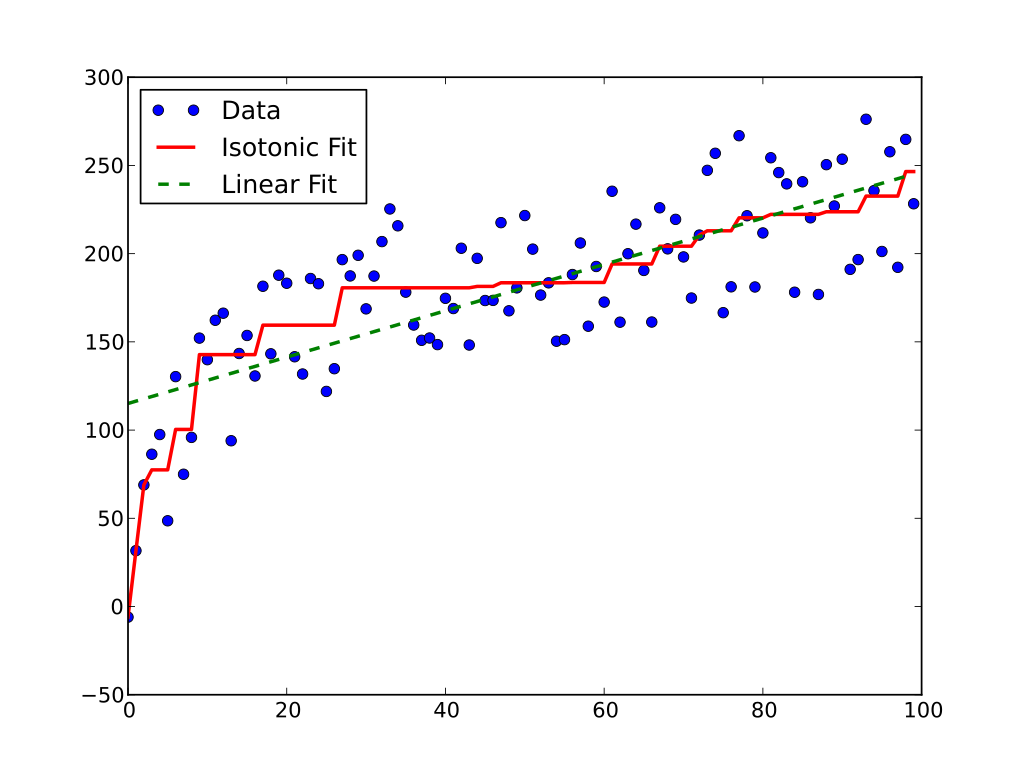

## <font color="steelblue">**Problema Ejemplar**</font>

Dado un conjunto de observaciones $(x_i,y_i)$ para $i=1,\cdots,n$, la regresión isotónica puede formularse mediante un problema de optimización cuadrática del siguiente modo:

$$\min \sum_{i=1}^n \epsilon^2_i \qquad \qquad\qquad$$
$$ s.a. \qquad\qquad\qquad\qquad$$
$$  y_i=\alpha_i + \epsilon_i, \quad i=1,\cdots,n$$
$$ p_{ij} \alpha_i \leq p_{ij}\alpha_j, \quad i,j=1,\cdots,n$$
$$ \alpha_i, \, \,\epsilon_i \,\quad  \text{free} \quad i=1,\cdots,n$$

donde $P=\{p_{ij}\}$ es una matriz binaria que recoge el orden parcial de los datos observados $x_i$.

$$ p_{ij}= 1 \quad si \quad  \mathbf{x}_i \preceq \mathbf{x}_j$$
$$ p_{ij}= 0 \quad si \quad  \mathbf{x}_i \nprec \mathbf{x}_j$$

Para cada una de las distribuciones siguientes, se generan 25 valores y se calculan las regresiones isotónicas para esos 25 valores.
* Caso 1: Cobb-Douglas, ($x,y$):
  $$y_i=x_i^{0.5}+v_i, \quad x_i \sim U(1,6), v_i\sim N(0,\sigma_v^2)$$
* Caso 2: Logistic function, ($x,y$):
  $$y_i=\frac{1+e^7}{e^7}\frac{e^{-3+10x_i}}{1+e^{-3+10x_i}}+v_i, \quad x_i \sim U(0,1), v_i\sim N(0,\sigma_v^2)$$

Utilizar $\sigma_v= 0.1$ y $\sigma_v= 0.2$

* Realizar una representación gráfica del ajuste realizado en los casos 1 y 2.
* Calcular para cada ajuste

  $$ MSE = \dfrac{1}{n}\sum_{i}( \hat{y}_i - y_i)^2$$

* Comparar con los siguientes ajustes de regresión:
  - $ \hat{y} = \alpha + \beta x $
  - $ \hat{y} = \alpha + \beta_1 x + \beta_2 x^2 $
  - $ \hat{y} = \alpha + \beta_1 x + \beta_2 x^2 +\beta_3 x^3$
  - $ \hat{y} = \alpha x^\beta $


  


In [3]:
# @title Distribuciones
from scipy.special import expit

# 1. Generación de datos estocásticos
def s_1( x ):
    """Caso 1, Cobb-Douglas: y = √x."""
    return np.sqrt(x)

def s_2( x ):
    """Caso 2, logística escalada para que f_2(1) = 1."""
    x = np.asarray(x, dtype=float)
    return (1 + np.exp(-7)) * expit(-3 + 10 * x)
        #-- Igual que (1+e⁷)/e⁷ · eᶻ/(1+eᶻ), sin desbordar para z grande.

def uniform(low, up, n,
            seed = 42):
    return np.sort(np.random.uniform(low, up, n))

def gaussian_noise(sigma=0.1, size=25):
    return np.random.normal(0, sigma, size)

def muestra(f, x,
            sigma, semilla):
    """y = f(x) + ruido N(0, σ²), con un generador propio."""
    ruido = np.random.default_rng(semilla).normal(0.0, sigma, len(x))
    return f(x) + ruido



In [4]:
# @title Modelos de referencia
from Rampas.referencias import catalogo_de_referencias
print(*catalogo_de_referencias(), sep="\n")

Recta
Polinomio de grado 2
Polinomio de grado 3
Potencia
Logística


In [5]:
# @title Datos: los cuatro escenarios y una muestra de cada uno
from typing import NamedTuple

class Escenario(NamedTuple):
    titulo:  str
    señal:   object      #-- La s(x) generadora.
    dominio: tuple       #-- (bajo, alto) de x.
    sigma:   float
    x:       object      #-- Una realización observada: las figuras
    y:       object      #-- la enseñan; el ranking genera las suyas.

N = 25
generador = np.random.default_rng(2025)
x1 = np.sort(generador.uniform(1, 6, N))
x2 = np.sort(generador.uniform(0, 1, N))
#-- Las mismas x para ambos ruidos de cada caso, como en el enunciado.

escenarios = [
    Escenario("Caso 1 · σ = 0.1", s_1, (1, 6), 0.1, x1, muestra(s_1, x1, 0.1, semilla=42)),
    Escenario("Caso 1 · σ = 0.2", s_1, (1, 6), 0.2, x1, muestra(s_1, x1, 0.2, semilla=43)),
    Escenario("Caso 2 · σ = 0.1", s_2, (0, 1), 0.1, x2, muestra(s_2, x2, 0.1, semilla=44)),
    Escenario("Caso 2 · σ = 0.2", s_2, (0, 1), 0.2, x2, muestra(s_2, x2, 0.2, semilla=45)),
    ]

# 2. Formulación matemática

### 2.1. Ajuste isotónico discreto

En una variable, el orden parcial del enunciado es un orden total, salvo empates. Agrupamos las observaciones con el mismo $x$ en un solo **nudo**: los nudos son los valores distintos $t_0<t_1<\dots<t_m$, y cada uno lleva $n_j$ observaciones con media $\bar y_j$. El estimador clásico resuelve

$$
\min_{\theta}\ \sum_{j=0}^{m} n_j\,(\bar y_j-\theta_j)^2
\quad\text{sujeto a}\quad
\theta_0\le\theta_1\le\dots\le\theta_m ,
$$

donde $\theta_j$ es el nivel ajustado en el nudo $t_j$ (la $\alpha_i$ del enunciado). Agrupar no cambia el problema: $\sum_i (y_i-\theta(x_i))^2$ y la suma ponderada anterior difieren en una constante que no depende de $\theta$.

La solución $\hat\theta$ es única: el objetivo es estrictamente convexo y las restricciones forman un conjunto convexo. Se calcula por optimización cuadrática o con el algoritmo PAVA (*pool adjacent violators*), que recorre los nudos y promedia los bloques vecinos que rompen el orden.

Esa solución solo da valores en los nudos. Para predecir entre ellos hace falta una **regla de extensión**:
- **por escalones:** entre $t_{j}$ y $t_{j+1}$ se mantiene el nivel $\hat\theta_j$;
- **por interpolación lineal:** se unen los niveles con segmentos.

Fuera de $[t_0,t_m]$ ambas son constantes. Coinciden en los nudos y difieren entre ellos. En §2.2 veremos que la primera se construye con escalones $u$ y la segunda con rampas $r$.

### 2.2. Rampas saturadas

La pieza base es la rampa unitaria, saturada:

$$
r(t)=
\begin{cases}
0, & t<0,\\
t, & 0\le t\le 1,\\
1, & t>1.
\end{cases}
$$

equivalentemente:
$$
r(t)=\min\bigl(1,\max(0,t)\bigr)
$$

Es una señal continua y no decreciente: vale 0 antes de $t=0$, sube linealmente y se queda en 1 a partir de $t=1$.



Es una señal continua y no decreciente que pasa de 0 a 1 en un intervalo de longitud uno. Su derivada es el pulso rectangular unitario sobre $[0,1]$ (salvo en $t=0$ y $t=1$, donde el pulso tampoco está definido).

Toda rampa que usaremos es esta señal desplazada y escalada. Entre dos nudos $a<b$:

$$
R_{a,b}(x)=r\!\left(\frac{x-a}{b-a}\right).
$$



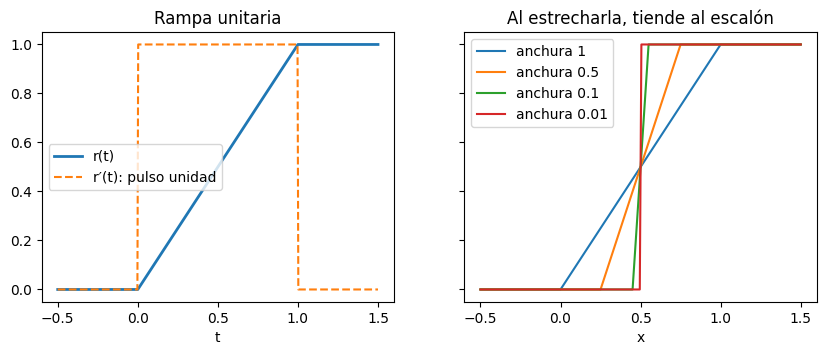

In [6]:
# @title Rampa unitaria: pulso y límite al escalón
from Rampas.senales import rampa_unitaria, rampa


t = np.linspace(-0.5, 1.5, 801)
figura, (izquierda, derecha) = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)

izquierda.plot(t, rampa_unitaria(t), lw=2, label="r(t)")
izquierda.plot(t, np.gradient(rampa_unitaria(t), t), "--", label="r′(t): pulso unidad")    #-- Derivada numérica: vale 1 dentro de [0, 1] y 0 fuera.
izquierda.set(title="Rampa unitaria", xlabel="t")
izquierda.legend(loc="center left")

for ancho in (1, 0.5, 0.1, 0.01):
    derecha.plot(t, rampa(t, 0.5 - ancho/2, 0.5 + ancho/2), label=f"anchura {ancho}")
    #-- Misma rampa centrada en 0.5, cada vez más estrecha.
derecha.set(title="Al estrecharla, tiende al escalón", xlabel="x")
derecha.legend(loc="upper left")
plt.show()

Cuando $b\to a$, $R_{a,b}$ tiende al escalón unitario $u(x-a)$, que es la pieza de la isotónica escalonada.

**Identidad.** Sean nudos $t_0<t_1<\dots<t_m$ y valores $v_0,\dots,v_m$ cualesquiera. Entonces

$$
f(x)=v_0+\sum_{j=1}^{m}(v_j-v_{j-1})\,R_{t_{j-1},t_j}(x)
$$


es la interpolación lineal de los puntos $(t_j,v_j)$, constante fuera de $[t_0,t_m]$.

**Intuición.** Imaginemos los niveles $v_0,\dots,v_m$ como peldaños. Cada peldaño se alcanza desde el anterior subiendo un salto $w_j$:

$$
v_j = v_{j-1} + w_j \qquad\Longrightarrow\qquad v_k = v_0 + \sum_{j=1}^{k} w_j .
$$

Un escalón $u$ sube cada salto de golpe en el nudo; una rampa $R_{t_{j-1},t_j}$ lo sube poco a poco a lo largo del tramo $[t_{j-1},t_j]$. Al recorrer $t$ de izquierda a derecha, cada rampa va «llenando» su salto, y cuando $t$ llega a $t_k$ ya se han sumado completos los $k$ primeros: estamos en $v_k$.

Sean nudos $t_0<t_1<\dots<t_m$, valores $v_0,\dots,v_m$ y saltos $w_j=v_j-v_{j-1}$. Entonces

$$
f(x)=v_0+\sum_{j=1}^{m} w_j\,R_{t_{j-1},t_j}(x)
$$

es la interpolación lineal de los puntos $(t_j,v_j)$, constante fuera de $[t_0,t_m]$.



*Demostración.* Sea $x\in[t_{k-1},t_k]$ y $\lambda=\dfrac{x-t_{k-1}}{t_k-t_{k-1}}\in[0,1]$.

En ese tramo, las rampas anteriores ya están saturadas y las posteriores aún no se han activado:

$$
R_{t_{j-1},t_j}(x)=
\begin{cases}
1 & j<k\\
\lambda & j=k\\
0 & j>k
\end{cases}
\qquad\Longrightarrow\qquad
f(x)=\underbrace{v_0+\sum_{j<k} w_j}_{v_{k-1}}+\lambda\,w_k ,
$$

que es la interpolación lineal entre $(t_{k-1},v_{k-1})$ y $(t_k,v_k)$. Fuera del rango de los nudos:

$$
x\le t_0:\ \text{todas las rampas valen }0\ \Rightarrow\ f(x)=v_0,
\qquad
x\ge t_m:\ \text{todas valen }1\ \Rightarrow\ f(x)=v_0+\sum_{j=1}^{m}w_j=v_m. \qquad
$$

$\blacksquare$




**Monotonía.** $f$ es no decreciente si y solo si ningún salto es negativo, $w_j\ge 0$: subir peldaños nunca hace bajar. Por eso **la restricción de orden de la isotónica se convierte en una restricción de signo sobre los pesos**.

### 2.3. Las rampas contienen a la isotónica

Con los nudos $t_0<\dots<t_m$ de §2.1 y $R_j=R_{t_{j-1},t_j}$, consideramos la familia

$$
𝓕 = \Big\{\,b+\sum_{j=1}^{m} w_j R_j \;:\; b\in\mathbb R,\ w_j\ge 0\,\Big\}.
$$

**Proposición.** El ajuste por mínimos cuadrados en $𝓕$ es único y es la interpolación lineal de los niveles isotónicos $\hat\theta$.

*Demostración.* Con $v_0=b$ y $v_j=v_{j-1}+w_j$, los saltos $w\ge 0$ equivalen, acumulados, a los niveles ordenados $v_0\le\dots\le v_m$ (§2.2), y $f(t_j)=v_j$. Como el error solo mira los nudos, ajustar en $𝓕$ es el problema de §2.1: su solución única es $v=\hat\theta$, y la función es su interpolación lineal (§2.2). $\blacksquare$

**Consecuencias.**
1. El ajuste isotónico se resuelve como mínimos cuadrados con pesos no negativos (NNLS).
2. La escalonada y la lineal tienen el mismo error de entrenamiento; solo se distinguen al predecir entre nudos.
3. Cualquier cambio en $𝓕$ da otro estimador (§2.4).

# 2.4. Familias en una variable

Todas las familias de modelos son sumas de rampas $f=b+\sum_j w_j R_j$ con $w_j\ge 0$, así que todas son crecientes. Se distinguen en **qué rampas se permiten** y **cómo se eligen**.

---

## **Isotónica escalonada.**
Los niveles $\hat{\theta}$ extendidos con escalones $u$ (§2.1). Es la referencia clásica, es un caso particular de una suma de rampas: es el límite cuando todas las pendientes se estrechan hasta un solo punto.

---

## **Isotónica lineal.**
Una rampa entre cada par de nudos consecutivos, con todos los pesos libres ($w_j\ge0$). Es el óptimo de 𝓕 (§2.3): tiene el mismo error de entrenamiento que la escalonada y solo cambia la predicción entre nudos. Usa tantas rampas como nudos haya.

---

## **Rampas comprimidas.**
$K$ rampas de la misma anchura, entre $K+1$ nudos equiespaciados fijados de antemano. Solo se ajustan los pesos, y el problema sigue siendo convexo. Con pocas rampas, la curva no puede seguir el ruido; a cambio, puede perder subidas que caigan entre dos nudos fijos.

---

## **Rampas libres.**
$K$ rampas de cualquier anchura, elegidas entre todas las que van de un nudo a cualquier otro. El ajuste decide dónde se pone cada rampa y cuánto mide: rampas estrechas donde la respuesta sube deprisa y anchas donde sube despacio. Elegir el mejor conjunto de $K$ rampas es combinatorio; se añade una cada vez (la que más reduce el error) y después se repasan por turnos. No garantiza el óptimo, pero el error nunca sube.

---

## **Rampas regularizadas.**
Un catálogo fijo de rampas a varias escalas (el rango completo, la mitad, un cuarto y un octavo), con pesos $w_j\ge0$ y una penalización $\lambda\sum_j w_j^2$. Las rampas anchas recogen la tendencia y las estrechas los detalles. La penalización prefiere repartir la subida entre muchas rampas pequeñas que concentrarla en pocas grandes: suaviza la curva y hace la solución única. El parámetro $\lambda$ regula cuánto: con $\lambda\to0$ se pega a los datos; con $\lambda$ grande se aplana hacia la media.

---

## **Rampas por división.**
Se empieza con una sola rampa, del mínimo al
máximo de $x$, y se busca el nudo interior que más reduce el error. Si el corte quita al menos una fracción del error global (el 5% en nuestro estudio), se acepta, y la búsqueda se repite dentro de cada mitad, recursivamente. Hemos seleccionado esta metodología para evitar overfitting. Partir una rampa nunca empeora el ajuste, pero no siempre lo mejora de forma perceptible: la recursión se detiene en un punto estable, y el número de rampas emerge de la búsqueda en lugar de fijarse de antemano.

---

Las dos primeras tienen el mismo error de entrenamiento. Las comprimidas y las libres usan el mismo número de rampas $K$, así que comparan dos estrategias: posiciones fijadas de antemano o elegidas por los datos. Los modelos de comparación (recta, polinomios de grado 2 y 3, potencia y logística) se describen en §3.

# 3. Datos y protocolo experimental

### 3.1. Escenarios unidimensionales

Usamos las dos señales del enunciado como generadores estocásticos $s(x)$. Las observaciones son $y_i = s(x_i) + G_i$, con $G_i \sim N(0,\sigma^2)$, $n = 25$ y $\sigma \in \{0.1,\, 0.2\}$:

- **Caso 1 (Cobb-Douglas):** $s_1(x) = \sqrt{x}$, con $x \sim U(1, 6)$.
- **Caso 2 (logística):** $s_2(x) = (1 + e^{-7})\,\dfrac{1}{1 + e^{\,3 - 10x}}$, con $x \sim U(0, 1)$. El factor $(1 + e^{-7})$ hace que $s_2(1) = 1$.

Dos señales por dos niveles de ruido dan cuatro escenarios. Las figuras de
§2.4 muestran una realización de cada uno; el protocolo siguiente los repite con muestras nuevas.


In [7]:
# @title Comprobación: rampas con un nudo por dato = isotónica lineal

for e in escenarios:
    malla = np.linspace(e.x.min(), e.x.max(), 500)
    isotonica = evaluar_nudos(ajustar_isotonica(e.x, e.y), malla)
    rampas = rampas_con_nudo_en_cada_dato(e.x, e.y)(malla)
    print(f"{e.titulo}: diferencia máxima = {np.max(np.abs(isotonica - rampas)):.1e}")

Caso 1 · σ = 0.1: diferencia máxima = 6.2e-15
Caso 1 · σ = 0.2: diferencia máxima = 8.9e-16
Caso 2 · σ = 0.1: diferencia máxima = 4.4e-16
Caso 2 · σ = 0.2: diferencia máxima = 6.7e-16


### 3.2. Protocolo, Comparación y ranking

**Protocolo.** En cada escenario se hacen $R$ repeticiones. En cada una, todos los modelos ven los mismos datos:

1. **Entrenamiento:** $n = 25$ pares $(x_i, y_i)$ nuevos, generados a partir de una semilla registrada.
2. **Ajuste:** todas las familias de §2.4 y los modelos de referencia, solo con el entrenamiento. Los parámetros que el modelo no fija ($K$, $\lambda$) se eligen por validación cruzada dentro del entrenamiento.
3. **Prueba:** $N_{\text{test}}$ pares nuevos de la misma distribución, con $x$ nuevas. El test no interviene en ninguna elección.
4. **Error:** para cada modelo y repetición,
$$\langle |y - f(x)|^2 \rangle_{\text{test}} = \frac{1}{N_{\text{test}}} \sum_{i=1}^{N_{\text{test}}} \big(y_i^{\text{test}} - f(x_i^{\text{test}})\big)^2 .$$
Como la señal es conocida, se calcula además $\langle |f(x) - s(x)|^2 \rangle$ sobre una malla de todo el dominio.

Las dos medidas están ligadas: con ruido independiente, la primera vale en media $\sigma^2$ más la segunda. Ordenan los modelos igual, pero la segunda no lleva rui2.4do de prueba y es más precisa; la primera es la única disponible con datos reales.

Las $x$ de prueba son nuevas porque sobre las $x$ de entrenamiento la isotónica escalonada y la lineal coinciden (§2.3) y no podrían distinguirse. Algunas $x$ de prueba caen fuera del rango de entrenamiento; ahí cada modelo extrapola como lo define (las rampas, constante).





### 3.3. Comparación y ranking

Comparamos las seis familias de rampas (§2.4) con los modelos de referencia
del enunciado — recta, polinomios de grado 2 y 3, y potencia — más una
logística. Dos referencias juegan con ventaja conocida: la potencia en el
Caso 1 y la logística en el Caso 2 tienen la misma forma que la señal, así
que marcan el techo de un paramétrico bien especificado.



Para cada modelo se reportan la media y la varianza del error de test
$\langle |y - f(x)|^2 \rangle$ y del error de señal
$\langle |f(x) - s(x)|^2 \rangle$ sobre una malla del dominio. Con ruido
independiente, el error de test vale en media $\sigma^2$ más el de señal:
ambos ordenan igual, pero el de señal no arrastra el ruido de la muestra de
prueba, y el de test es el único medible cuando la señal no se conoce. El
ranking ordena por error de señal medio. La tabla de victorias lo
complementa: en cada repetición los modelos se ordenan por su error de
señal, y se reportan las victorias (veces en el puesto 1) y el puesto
medio, mejor y peor de cada modelo.

Los parámetros fijados de antemano forman parte de la definición de cada
modelo: $K = 6$ en comprimidas y libres, $\lambda$ en regularizadas y el
umbral $\varepsilon = 2\,\Delta p / n$ de la división (§2.4). Ninguna
elección toca las muestras de prueba.

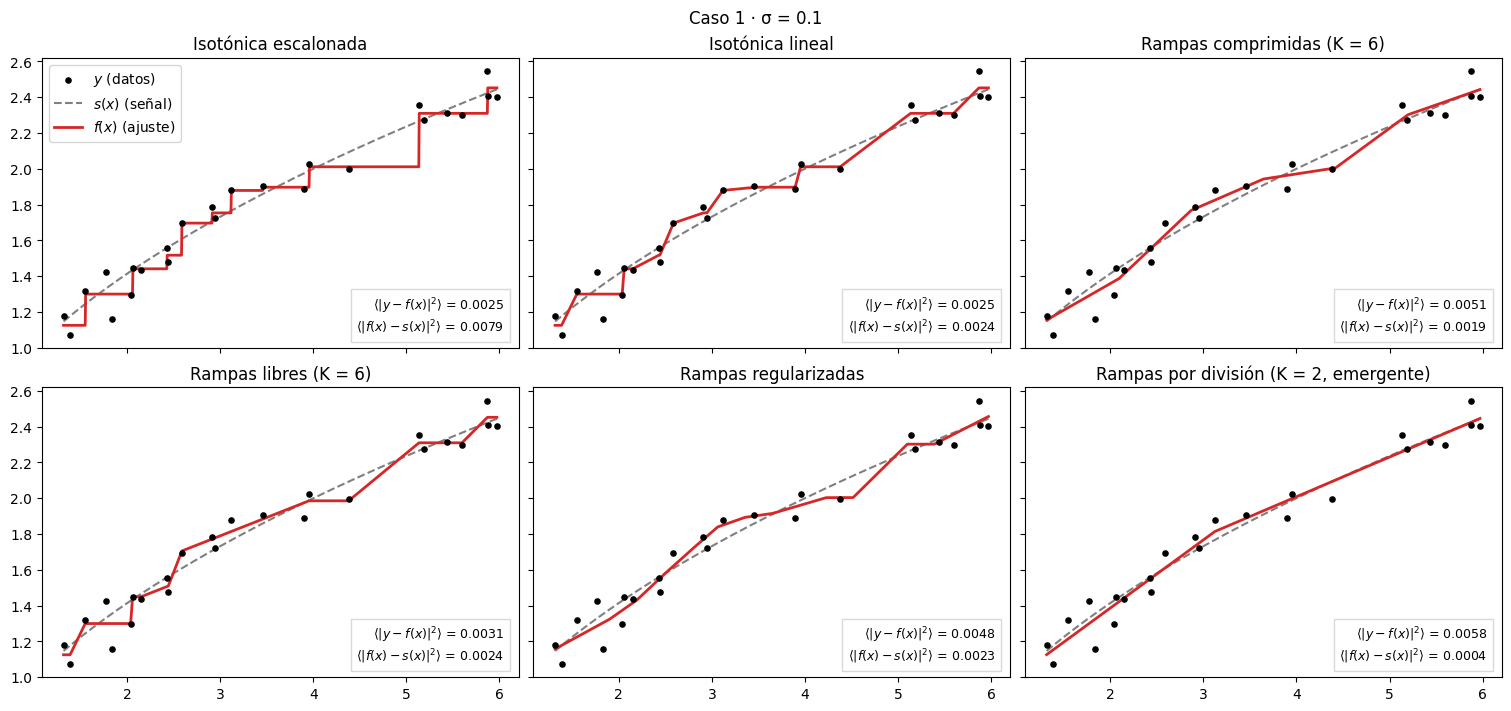

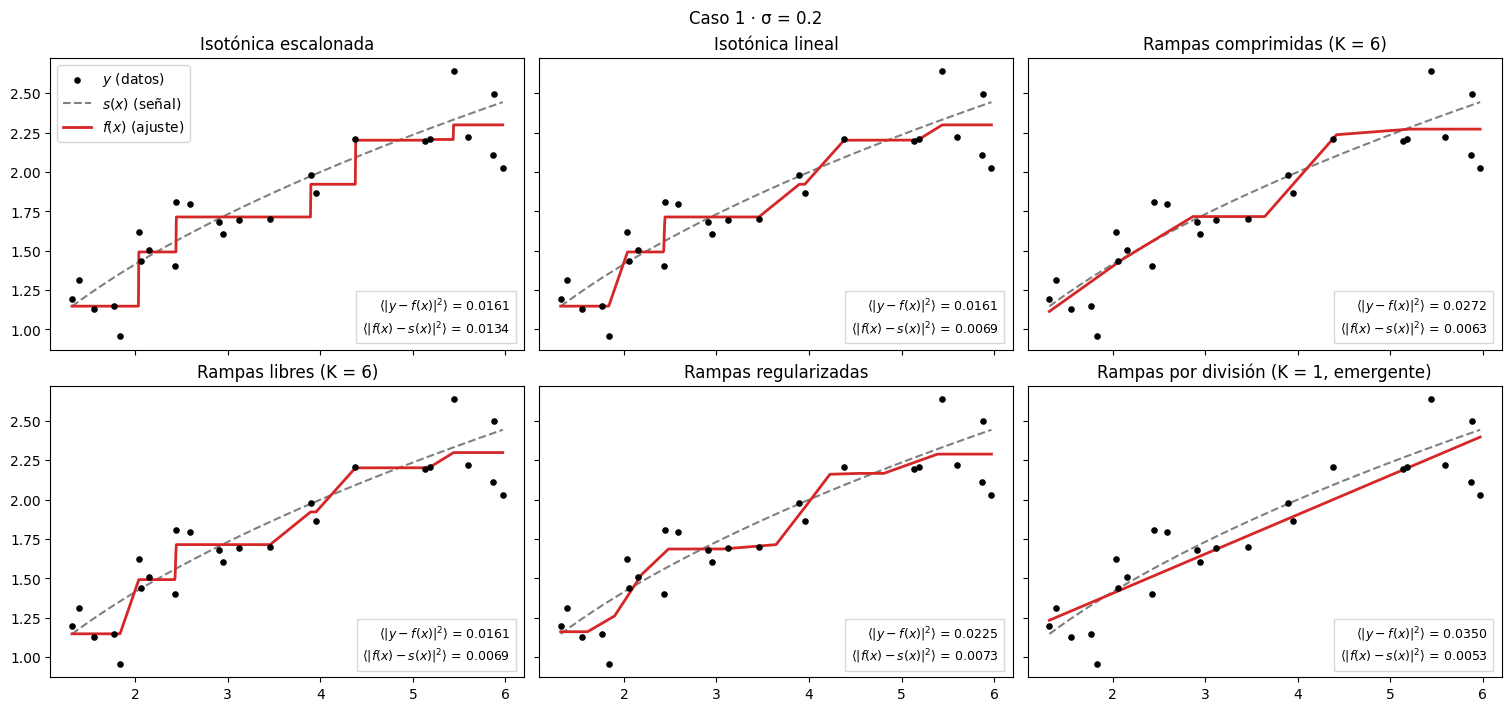

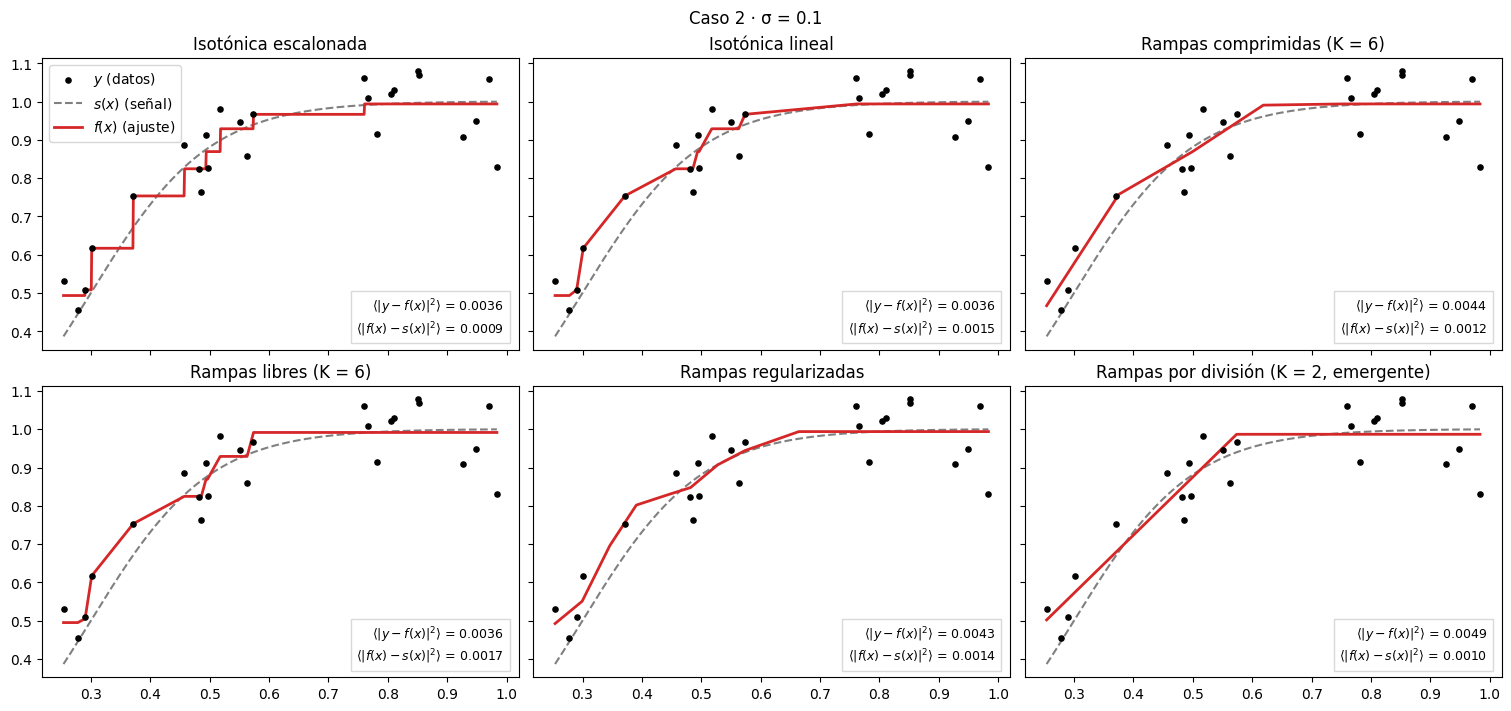

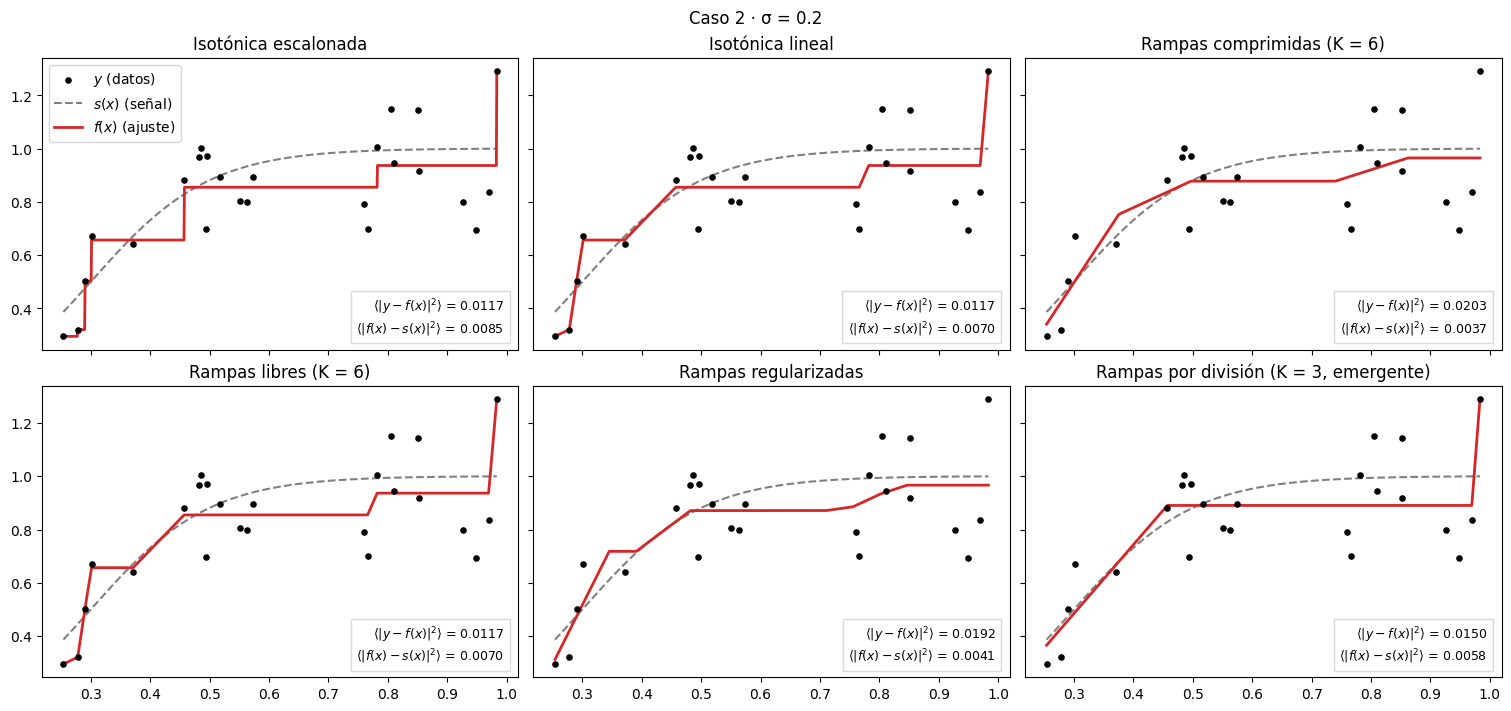

In [8]:
# @title Las familias en los cuatro escenarios
from Rampas.graficos import dibujar_familias

for e in escenarios:
    dibujar_familias(e.x, e.y, verdad=e.señal, titulo=e.titulo)
    plt.show()

## 4. Resultados unidimensionales

### 4.1. Las familias, comparadas

Tres cosas saltan a la vista. La escalonada y la lineal parten de
los mismos niveles y solo difieren entre nudos, como exige §2.3. Las
comprimidas, con sus nudos equiespaciados fijados de antemano, pierden nitidez
justo donde la logística sube. Y la división elige pocas rampas: la raíz
cuadrada con ruido alto se queda en una sola. Una advertencia: la suavidad
visual no es evidencia de menor riesgo predictivo; para eso están las tablas
que siguen.


In [9]:
# @title Ranking en los cuatro escenarios (~1 min)
from Rampas.ranking import ranking_de_modelos

for e in escenarios:
    print(e.titulo)
    display(ranking_de_modelos(e.señal, *e.dominio, e.sigma, semilla=2026))

Caso 1 · σ = 0.1


,Test (media),Test (varianza),Señal (media),Señal (varianza),Ajustes fallidos
Modelo,,,,,
Potencia,0.011240,0.000015,0.001334,0.000004,0
Polinomio de grado 2,0.012581,0.000022,0.002835,0.000010,0
Logística,0.012795,0.000023,0.003021,0.000009,0
Rampas por división,0.012935,0.000018,0.003241,0.000005,0
Recta,0.012971,0.000019,0.003332,0.000004,0
Polinomio de grado 3,0.013386,0.000024,0.003592,0.000009,0
Rampas comprimidas (K = 6),0.015428,0.000021,0.005447,0.000005,0
Isotónica lineal,0.015554,0.000033,0.005505,0.000007,0
Rampas libres (K = 6),0.015805,0.000034,0.005765,0.000008,0


Caso 1 · σ = 0.2


,Test (media),Test (varianza),Señal (media),Señal (varianza),Ajustes fallidos
Modelo,,,,,
Potencia,0.044942,0.000231,0.005291,0.000055,0
Recta,0.046566,0.000257,0.007360,0.000063,0
Rampas por división,0.050500,0.000430,0.010510,0.000116,0
Polinomio de grado 2,0.050149,0.000360,0.011194,0.000156,0
Logística,0.050576,0.000361,0.011398,0.000141,0
Polinomio de grado 3,0.053533,0.000385,0.014386,0.000151,0
Rampas comprimidas (K = 6),0.055357,0.000326,0.015414,0.000085,0
Isotónica lineal,0.056802,0.000515,0.016535,0.000138,0
Rampas regularizadas,0.056079,0.000350,0.016640,0.000105,0


Caso 2 · σ = 0.1


,Test (media),Test (varianza),Señal (media),Señal (varianza),Ajustes fallidos
Modelo,,,,,
Logística,0.012379,0.000018,0.002498,0.000006,0
Rampas por división,0.012987,0.000020,0.003218,0.000007,0
Rampas comprimidas (K = 6),0.013544,0.000021,0.003572,0.000006,0
Isotónica lineal,0.014208,0.000035,0.004270,0.000011,0
Rampas regularizadas,0.014157,0.000026,0.004427,0.000011,0
Rampas libres (K = 6),0.014449,0.000037,0.004556,0.000013,0
Polinomio de grado 2,0.014701,0.000024,0.005542,0.000009,0
Polinomio de grado 3,0.015764,0.000031,0.006388,0.000014,0
Isotónica escalonada,0.017991,0.000045,0.007981,0.000017,0


Caso 2 · σ = 0.2


,Test (media),Test (varianza),Señal (media),Señal (varianza),Ajustes fallidos
Modelo,,,,,
Logística,0.050032,0.000310,0.010417,0.000109,0
Rampas por división,0.049572,0.000342,0.010611,0.000135,0
Rampas comprimidas (K = 6),0.052402,0.000308,0.012695,0.000095,0
Rampas regularizadas,0.053145,0.000348,0.014171,0.000133,0
Polinomio de grado 2,0.052140,0.000356,0.014175,0.000149,0
Isotónica lineal,0.054271,0.000529,0.014652,0.000165,0
Rampas libres (K = 6),0.054419,0.000537,0.014939,0.000172,0
Potencia,0.055914,0.000285,0.017393,0.000050,0
Polinomio de grado 3,0.056138,0.000407,0.017709,0.000172,0


### 4.2. Ranking por error medio

El protocolo de §3.2 da, por modelo y escenario, el error de test y el error
de señal medios. Tres lecturas:

**El techo bien especificado se respeta.** La potencia en el Caso 1 y la
logística en el Caso 2 — los paramétricos con la forma de la señal — ganan
su caso: 0.0013 y 0.0053 de error de señal la potencia; 0.0025 y 0.0104 la
logística. Ninguna familia de rampas debería superarlos, y ninguna lo hace.

**Las rampas pagan poco por no conocer la forma.** Rampas por división es la
mejor familia en los cuatro escenarios, y en el Caso 2 pisa los talones al
techo: 0.0032 frente a 0.0025 (σ = 0.1) y 0.0106 frente a 0.0104 (σ = 0.2),
un empate técnico. El contraste está en el otro sentido: el paramétrico
*equivocado* se hunde — la recta es última en el Caso 2 (0.0190 y 0.0233) y
la potencia cae al décimo puesto — mientras que las rampas no tienen
escenario catastrófico. Conocer la forma vale mucho cuando se acierta y
cuesta mucho cuando se falla; las rampas nunca la necesitan.

**Extender por escalones sale caro.** La isotónica escalonada es la peor
familia de rampas en los cuatro escenarios, con el doble de error de señal
que su interpolación lineal (0.0101 frente a 0.0055 en el Caso 1 con
σ = 0.1). Mismo error de entrenamiento por §2.3; predicción muy distinta.

La relación de §3.2 se verifica en toda la tabla: el error de test es,
columna a columna, el de señal más σ² (0.0112 ≈ 0.0013 + 0.01 para la
potencia en el Caso 1 con σ = 0.1).

In [10]:
# @title Liga: todos los escenarios en una tabla
from Rampas.ranking import liga_de_victorias

display(liga_de_victorias(
    [(e.señal, *e.dominio, e.sigma) for e in escenarios],
    semilla=2026,
    ))

,Victorias,Puesto medio,Mejor,Peor
Modelo,,,,
Logística,11,2.900,1.0,7.0
Rampas por división,6,3.675,1.0,7.0
Polinomio de grado 2,1,4.575,1.0,11.0
Potencia,20,4.950,1.0,10.0
Rampas comprimidas (K = 6),2,5.650,1.0,11.0
Polinomio de grado 3,0,6.200,2.0,11.0
Isotónica lineal,0,6.550,3.0,10.0
Rampas regularizadas,0,7.175,2.0,11.0
Recta,0,7.350,2.0,11.0


### 4.3. Puestos por repetición y clasificación conjunta

El error medio de §4.2 resume cada escenario; aquí se examina la
distribución. En cada repetición los modelos se ordenan por error de señal;
se reportan las victorias y el puesto medio, mejor y peor, por escenario y
en la clasificación conjunta de las 40 repeticiones.

Los puestos separan dos regímenes de riesgo. Los modelos paramétricos son
bimodales: puesto medio 1.0 cuando su forma coincide con la señal (la
potencia en el Caso 1) y puestos 8–11 cuando no (la misma potencia en el
Caso 2; la recta, última en las diez repeticiones del Caso 2 con σ = 0.1).
Las familias de rampas ocupan una banda intermedia estable: la división se
mueve entre 2.3 y 5.2 de puesto medio según el escenario. En la
clasificación conjunta esa estabilidad decide: la potencia, con 20
victorias en 40 repeticiones, queda por detrás de la división, con 6,
porque el puesto medio penaliza la caída bajo mala especificación más de lo
que premian las victorias. La dispersión del puesto entre escenarios actúa
así como medida empírica del riesgo de especificación, y las rampas la
minimizan.

La ventaja del paramétrico bien especificado decrece con el ruido: en el
Caso 2, la logística supera a la división con σ = 0.1 (puestos medios 1.5
frente a 2.8) y cede con σ = 0.2 (2.4 frente a 2.3). Con ruido alto, el
error de estimación domina sobre la ventaja de especificación y la familia
monótona flexible alcanza al modelo verdadero.

Las columnas Mejor y Peor acotan la variabilidad: incluso la división
oscila entre los puestos 1 y 7. Con n = 25, una comparación sobre una sola
muestra es poco informativa, lo que justifica el promedio del protocolo.



# 5. Modelos en dos variables

Los tres modelos aplican la maquinaria de una variable (§2) a una proyección del plano: cada pieza es una suma de rampas $f$ con pesos no negativos sobre un escalar derivado de los datos en $(x, y)$. Difieren solo en qué proyección usan, y esa elección esconde una hipótesis sobre cómo se combinan las entradas. En los ejemplos, el dominio se traslada y escala a $[0,1]²$, con el origen en el mínimo de los datos.



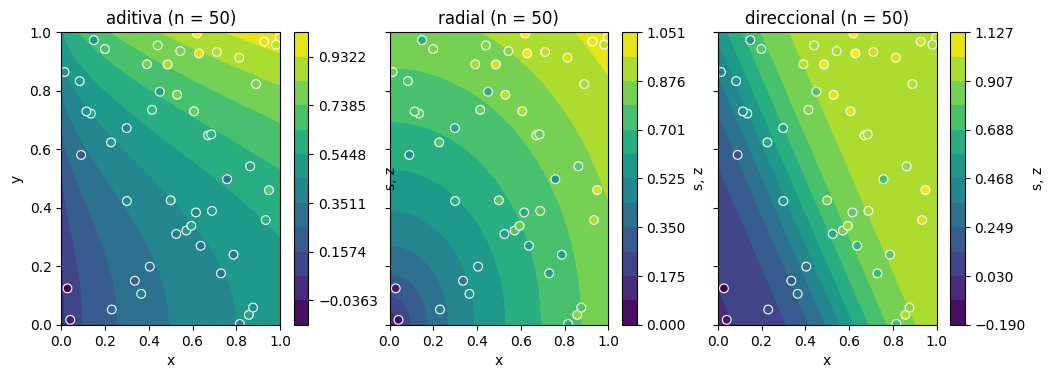

In [11]:
# @title Datos de §5: una muestra de cada estructura sobre su señal (n = 50)
from Rampas.estructuras import ESTRUCTURAS, muestra_2d
from Rampas.graficos import dibujar_datos_2d

muestras = {nombre: (*muestra_2d(s, 50, 0.1, 0), s) for nombre, s in ESTRUCTURAS.items()}
dibujar_datos_2d(muestras); plt.show()

### 5.1. Zigurat: estructura aditiva ortogonal

$$
f_Z(x,y)=c+f_x(x)+f_y(y).
$$

Cada variable actúa por separado. Es monótona en cada coordenada porque lo
son $f_x$ y $f_y$. Su ventaja es el menor coste estructural; su limitación,
que no representa interacciones.


### 5.2. Diana: dependencia radial

$$
f_D(x,y)=f\!\left(\sqrt{x^2+y^2}\right).
$$

Solo importa la distancia al origen. En la normalización de $[0,1]^2$ ambas coordenadas crecen
con el radio, así que la monotonía radial implica monotonía en cada
coordenada.



### 5.3. Tangentes: proyecciones direccionales

$$
f_T(x,y) = b + Σₖ fₖ(ûₖ·x)
$$

Con direcciones ûₖ ≥ 0 estimadas por barrido de ángulos en
$[0°, 90°]$ y retroajuste. Las direcciones no negativas garantizan la
monotonía en cada coordenada.Contiene a Zigurat y al modelo de una sola proyección como casos particulares.


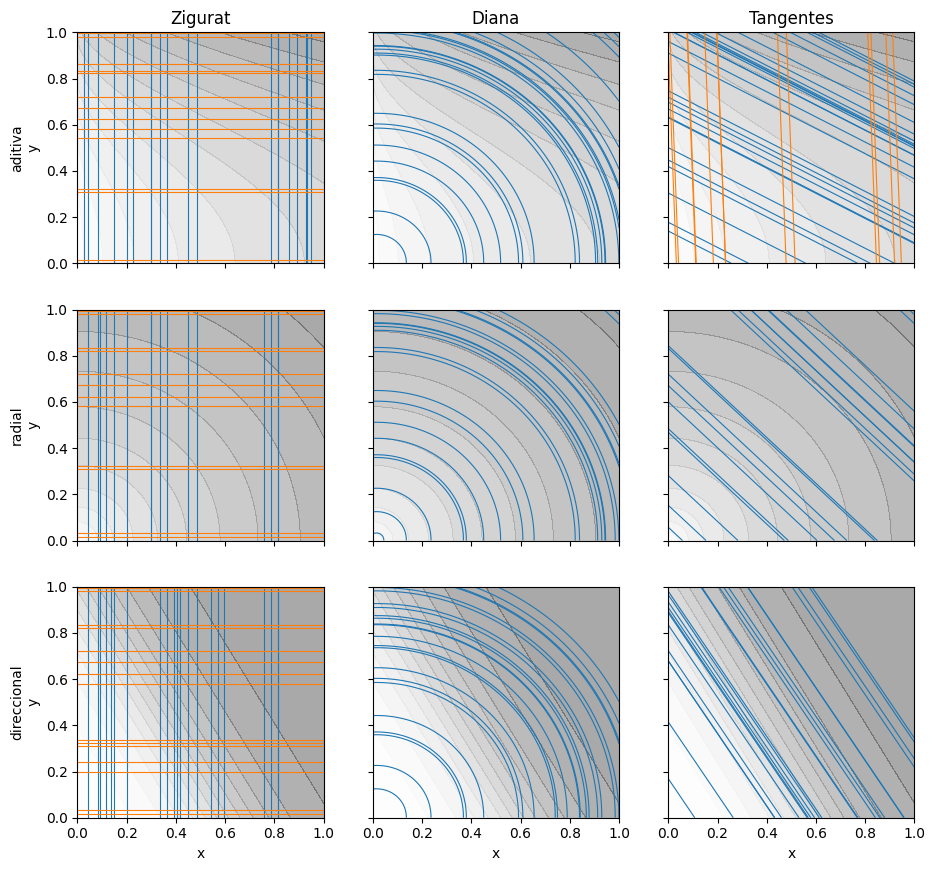

In [12]:
# @title Figura (5.3): la red de nudos de cada modelo
from Rampas.graficos import dibujar_redes
dibujar_redes(muestras); plt.show()

### 5.4. Pathfinder: el isotónico con camino

Los tres modelos anteriores son hipótesis sobre la estructura; el Pathfinder
la construye explorando con la visión de Tangentes. Desde el origen, cada
paso elige la dirección de mayor crecimiento isotónico del residuo, avanza
por el llano hasta donde empieza la subida, la escala con una rampa,
y una vez arriba reajusta todos los pesos y reevalúa desde la nueva posición. Itera hasta
quedarse sin nodos. El resultado es la representación completa de la estructura
monótona, descrita por los pares $(w_k, P_k)$.

El camino $P_0, P_1, \dots$ sigue aproximadamente la dirección de máximo
crecimiento, perpendicular a las curvas de nivel, y su rumbo dominante
delata la estructura.

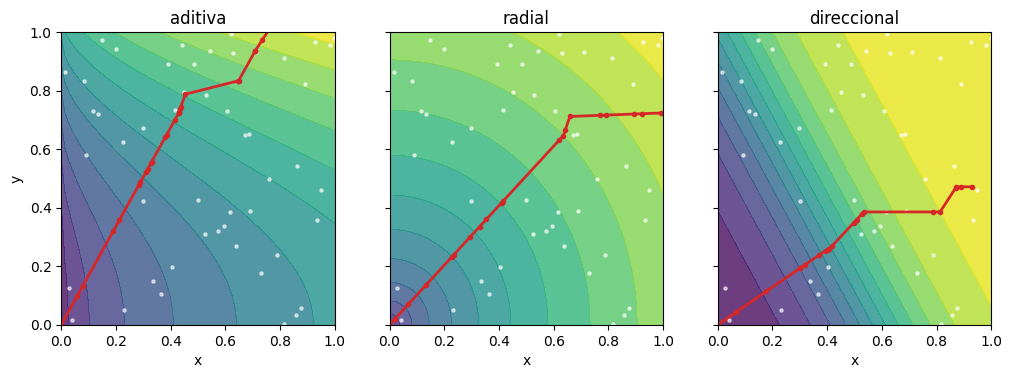

In [13]:
# @title Figura (5.4): el camino del Pathfinder
from Rampas.graficos import dibujar_caminos
dibujar_caminos(muestras); plt.show()

In [14]:
# @title Figura interactiva: modelos en 3D (arrastra para girar)
from Rampas.graficos import figura_3d_interactiva
figura_3d_interactiva(muestras).show()

### 5.5. Diseño y resultados

Los datos se generan con $(x, y)$ uniformes en $[0,1]^2$, $\sigma = 0.1$ y
cada una de las tres estructuras:

- aditiva: $s(x,y) = \tfrac12\sqrt{x} + \tfrac12 y^2$;
- radial: $s(x,y) = \sqrt{r/\sqrt2}$, con $r = \sqrt{x^2+y^2}$;
- direccional: $s(x,y) = L\big(8\,(x\cos 30° + y \sin 30° - \tfrac12)\big)$,
  con $L$ la logística estándar.

Se usan $n = 50$ datos: con 25, como en una variable, el plano queda con unos
cinco puntos por eje, demasiado pocos para estimar direcciones. Los tres
modelos y el Pathfinder se ajustan en cada estructura, en un diseño 3×3 donde
cada hipótesis se evalúa también en los mundos ajenos. Se hacen 10
repeticiones y el error de señal $\langle |f - s|^2 \rangle$ se mide en 3000
puntos nuevos del dominio. Concursan las tres hipótesis; el Pathfinder aparece
en la tabla, fuera del concurso.

In [15]:
# @title Experimento 3×3 (~30 s)
from Rampas.experimento import ejecutar
medias, victorias, angulos = ejecutar(repeticiones=10)
display(medias.round(4)); display(victorias)

,Zigurat,Diana,Tangentes,Pathfinder,Camino por división
aditiva,0.0036,0.0058,0.0046,0.0054,0.0055
radial,0.0054,0.0022,0.0036,0.0033,0.0048
direccional,0.0136,0.0186,0.0032,0.0046,0.0022


,Zigurat,Diana,Tangentes
aditiva,8,0,2
radial,0,10,0
direccional,0,0,10


In [16]:
# @title Ranking 2D: conjunto y por señal (~30 s)
from Rampas.experimento import ranking_2d, separar_por_estructura

formato = lambda t: t.style.format("{:.4f}").format("{:.1e}", subset=["Señal (varianza)"])

tabla = ranking_2d()
display(formato(tabla))
for estructura, parte in separar_por_estructura(tabla).items():
    print(estructura)
    display(formato(parte))

,Entrenamiento,Prueba,Señal (media),Señal (varianza)
Modelo · estructura,,,,
Camino por división · direccional,0.0090,0.0122,0.0022,6.3e-07
Diana · radial,0.0062,0.0123,0.0022,8.3e-07
Tangentes · direccional,0.0050,0.0132,0.0032,1.6e-06
Pathfinder · radial,0.0065,0.0133,0.0033,1.1e-06
Zigurat · aditiva,0.0042,0.0136,0.0036,1.6e-06
Tangentes · radial,0.0062,0.0136,0.0036,8.7e-07
Tangentes · aditiva,0.0052,0.0146,0.0046,1.4e-06
Pathfinder · direccional,0.0065,0.0145,0.0046,1.7e-06
Camino por división · radial,0.0087,0.0148,0.0048,3.6e-05


aditiva


,Entrenamiento,Prueba,Señal (media),Señal (varianza)
Modelo,,,,
Zigurat,0.0042,0.0136,0.0036,1.6e-06
Tangentes,0.0052,0.0146,0.0046,1.4e-06
Pathfinder,0.0066,0.0155,0.0054,3.2e-06
Camino por división,0.0083,0.0155,0.0055,1.1e-04
Diana,0.0076,0.0159,0.0058,1.1e-06


radial


,Entrenamiento,Prueba,Señal (media),Señal (varianza)
Modelo,,,,
Diana,0.0062,0.0123,0.0022,8.3e-07
Pathfinder,0.0065,0.0133,0.0033,1.1e-06
Tangentes,0.0062,0.0136,0.0036,8.7e-07
Camino por división,0.0087,0.0148,0.0048,3.6e-05
Zigurat,0.0059,0.0153,0.0054,1.4e-06


direccional


,Entrenamiento,Prueba,Señal (media),Señal (varianza)
Modelo,,,,
Camino por división,0.0090,0.0122,0.0022,6.3e-07
Tangentes,0.0050,0.0132,0.0032,1.6e-06
Pathfinder,0.0065,0.0145,0.0046,1.7e-06
Zigurat,0.0078,0.0234,0.0136,6.7e-06
Diana,0.0179,0.0287,0.0186,2.2e-06


In [17]:
# @title Ranking 2D: cada modelo · estructura, por error de señal (~30 s)
from Rampas.experimento import ranking_2d

tabla = ranking_2d()
display(tabla.style.format("{:.4f}").format("{:.1e}", subset=["Señal (varianza)"]))

,Entrenamiento,Prueba,Señal (media),Señal (varianza)
Modelo · estructura,,,,
Camino por división · direccional,0.0090,0.0122,0.0022,6.3e-07
Diana · radial,0.0062,0.0123,0.0022,8.3e-07
Tangentes · direccional,0.0050,0.0132,0.0032,1.6e-06
Pathfinder · radial,0.0065,0.0133,0.0033,1.1e-06
Zigurat · aditiva,0.0042,0.0136,0.0036,1.6e-06
Tangentes · radial,0.0062,0.0136,0.0036,8.7e-07
Tangentes · aditiva,0.0052,0.0146,0.0046,1.4e-06
Pathfinder · direccional,0.0065,0.0145,0.0046,1.7e-06
Camino por división · radial,0.0087,0.0148,0.0048,3.6e-05


La diagonal se cumple: cada hipótesis tiene el menor error medio en su
estructura y gana 28 de las 30 repeticiones. Fuera de su mundo, las hipótesis
restringidas fallan con claridad: en la estructura direccional, Zigurat y
Diana multiplican por 4 y por 6 el error de Tangentes (0.0136 y 0.0186 frente
a 0.0032).

Las dos derrotas de la diagonal ocurren en la estructura aditiva y las gana
Tangentes, que contiene a Zigurat. El modelo general nunca queda lejos: es
segundo en la aditiva (0.0046 frente a 0.0036) y en la radial (0.0036 frente
a 0.0022). Es el patrón de §4.3 en dos variables: las hipótesis restringidas
son bimodales y el modelo general es estable. Para el diagnóstico, esto obliga
a leer el margen y no solo el ganador: si un modelo general gana por poco a
uno restringido que contiene, la lectura parsimoniosa es la estructura
restringida.

Las direcciones de Tangentes apoyan la lectura, pero no la sustituyen. En la
estructura direccional recuperan el ángulo verdadero en las diez repeticiones
(entre 26° y 33°). En la radial y en la aditiva dan a menudo una única
dirección oblicua cerca de la diagonal, así que el ángulo por sí solo no
distingue esas dos estructuras.

El Pathfinder, completo y sin regularizar, queda cerca de Tangentes: le gana
en la radial (0.0033 frente a 0.0036) y pierde en la aditiva y en la
direccional (0.0056 y 0.0045). Es la relación de §4 entre la isotónica lineal
y las rampas por división, ahora en dos variables: la representación completa
también sigue parte del ruido.

## 6. Discusión

**La ganancia está en la familia, no en la identidad.** La equivalencia de
§2.3 no mejora ninguna predicción por sí sola: la isotónica lineal es la
misma función, escrita con rampas. Lo que cambia los resultados es elegir
qué rampas se permiten. Dos decisiones dominan en §4. La primera es la regla
de extensión: la escalonada y la lineal comparten niveles y error de
entrenamiento, y aun así la escalonada duplica el error de señal. La segunda
es la selección de nudos: la división, que añade rampas solo mientras pagan
su coste de descripción, es la mejor familia en los cuatro escenarios.

**El riesgo de especificación tiene el mismo patrón en una y dos
variables.** Los modelos rígidos son bimodales: los paramétricos en §4 y
Zigurat y Diana en §5 son óptimos cuando su forma coincide con la señal y
caen al fondo cuando no. Los modelos generales de rampas (la división en una
variable, Tangentes en dos) no ganan siempre, pero nunca se hunden. Si no se
conoce la forma, esa estabilidad vale más que el óptimo condicional: en la
clasificación conjunta, la potencia acumula más victorias que nadie y queda
por detrás de la división en puesto medio. La ventaja del modelo bien
especificado, además, se reduce con el ruido.

**El diagnóstico funciona si se lee el margen.** El modelo con menor error
coincide con la estructura real en 28 de 30 repeticiones, pero un modelo que
contiene a otro puede ganarle por poco en el mundo de este, como Tangentes a
Zigurat en la estructura aditiva. Por eso la regla de lectura es
parsimoniosa: una victoria estrecha del modelo general apunta a la
estructura restringida. Las direcciones aprendidas confirman la estructura
direccional, pero no separan la aditiva de la radial; son un apoyo, no un
criterio. El Pathfinder añade una lectura visual, porque su camino sigue la
dirección de máximo crecimiento. Como representación completa, también
sigue parte del ruido, igual que la isotónica lineal en una variable.

**Limitaciones.** Los datos son sintéticos y de estructura conocida, con
tamaños pequeños (25 datos en una variable, 50 en dos) y un único nivel de
ruido en dos variables.

## 7. Conclusiones y trabajo futuro

Un mismo marco, sumas de rampas saturadas con pesos no negativos, reproduce
la regresión isotónica en una variable y, en dos, permite diagnosticar cómo
se combinan las entradas. Las preguntas de §1.1 quedan respondidas así:

1. **Equivalencia.** Con un nudo en cada observación, la suma de rampas es
   exactamente la isotónica lineal: se demuestra en §2.3 y se verifica
   numéricamente, con diferencias del orden de 10⁻¹⁵.
2. **Variantes.** Cambiar la familia sí cambia la predicción. La regla de
   extensión importa: la isotónica escalonada es la peor familia en los
   cuatro escenarios. La selección de nudos también: las rampas por
   división, que solo añaden una rampa cuando su mejora paga su coste de
   descripción, mejoran a la isotónica lineal en los cuatro y empatan con
   el paramétrico bien especificado cuando el ruido es alto.
3. **Direcciones.** Tangentes recupera la dirección de una señal
   direccional en todas las repeticiones (26°–33° frente a 30°). En las
   estructuras aditiva y radial las direcciones aprendidas no son
   diagnósticas por sí solas.
4. **Diagnóstico.** El modelo con menor error de señal coincide con la
   estructura real en las tres estructuras, y en 28 de 30 repeticiones. Las
   excepciones son victorias estrechas del modelo general sobre el
   restringido que contiene, y se resuelven con una lectura parsimoniosa
   del margen.

En una y en dos variables aparece el mismo patrón de riesgo: los modelos
rígidos son óptimos cuando su forma acierta y caen al fondo cuando no,
mientras que los modelos generales de rampas nunca se hunden. Cuando la
forma es desconocida, esa estabilidad es la propiedad que importa.

**Trabajo futuro.**

- **Pathfinder regularizado.** El Pathfinder completo es el análogo en dos
  variables de la isotónica lineal y, como ella, sigue parte del ruido. Su
  variante con umbral de parada debería cumplir el papel de las rampas por
  división.
- **Criterio de parada.** El umbral ε = 2Δp/n tiene una justificación de
  longitud de descripción. Alternativas como la blancura del residuo o la
  calibración por remuestreo quedan por comparar con el protocolo de §3.
- **Estructuras fuera de las hipótesis.** Una interacción multiplicativa
  como la Cobb-Douglas de dos variables, s = x^a y^b, no pertenece a
  ninguna de las tres y es la prueba natural de los límites del
  diagnóstico.
- **Más dimensiones.** La maquinaria de rampas no depende de la dimensión,
  pero la búsqueda de direcciones por barrido de ángulos no escala más
  allá del plano.
- **Datos reales,** con más niveles de ruido y tamaños de muestra, y
  relaciones con monotonía de signo mixto.

In [18]:
4raise "Stop here. Only notes after this break."

SyntaxError: invalid decimal literal (3162467902.py, line 1)








## Trazabilidad y pendientes para la versión publicable

- [ ] Verificar la fórmula exacta de la función logística tal como se ejecuta en el código.
- [ ] Fijar la definición operacional y los hiperparámetros de cada estimador.
- [ ] Aislar y exportar los cuatro escenarios unidimensionales.
- [ ] Repetir pruebas con muestras y semillas independientes y registrar incertidumbre.
- [ ] Comprobar las restricciones de monotonía sobre el dominio de cada geometría.
- [ ] Revisar si la simulación bidimensional compara modelos sobre señales equivalentes y emparejadas.
- [ ] Añadir figuras numeradas, resultados numéricos verificados y referencias primarias.
- [ ] Separar el código reproducible (anexo/cuaderno) del hilo argumental del artículo.


In [ ]:
from Rampas.modelos_2d import ajustar_ascenso, camino_del_ascenso

modelo = ajustar_ascenso(X, y)          # pasos=None, sensibilidad=0.05
modelo.predecir(X_nuevos)
modelo.angulos_grados()                 # direcciones de los tramos
camino_del_ascenso(modelo)              # los puntos P_0, P_1, … del camino

In [ ]:
def evaluar_ajuste(x, y, modelo, n_malla=300):
    """Devuelve (malla, curva, MSE de entrenamiento), sin dibujar."""
    x = vector_finito(x, "x")
    y = vector_finito(y, "y")

    if not isinstance(n_malla, (int, np.integer)) or n_malla < 2:
        raise ValueError("n_malla debe ser un entero mayor o igual que 2.")

    predecir = regresion(x, y, modelo)
    mse = MSE(y, predecir(x))
    malla = np.linspace(x.min(), x.max(), n_malla)

    return malla, predecir(malla), mse

In [ ]:
# @title Resolución Isotónica
def regresion_isotonica(x, y):
    """
    Resuelve la regresión isotónica formulada como un problema de optimización cuadrática:
    - Minimizar sum (alpha_i - y_i)^2
    - Sujeto a: alpha_i <= alpha_j para todo x_i <= x_j
    """
    n = len(x)
    alpha = cp.Variable(n)

    # Crear las restricciones de orden basados en los valores de x
    constraints = []
    for i in range(n):
        for j in range(n):
            if x[i] < x[j]:
                constraints.append(alpha[i] <= alpha[j])
            elif x[i] == x[j] and i != j:
                constraints.append(alpha[i] == alpha[j])
    #print(constraints)

    # Función objetivo: Minimizar el error cuadrático
    objective = cp.Minimize(cp.sum_squares(alpha - y))
    prob = cp.Problem(objective, constraints)
    prob.solve(
        solver=cp.OSQP,
        eps_abs=1e-9,
        eps_rel=1e-9,
        )

    if prob.status != cp.OPTIMAL or alpha.value is None:
        raise RuntimeError(
            f"No se obtuvo una solución óptima: {prob.status}"
            )

    return np.asarray(alpha.value, dtype=float)



In [ ]:
import numpy as np

from scipy.optimize import curve_fit
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.utils.validation import (
    check_array,
    check_is_fitted,
    check_X_y,
    )


class RegresorCurva(RegressorMixin, BaseEstimator):
    """Adapta una fórmula f(x, *parametros) al contrato fit / predict."""

    def __init__(estimador, funcion, iniciales=None, maxfev=30000):
        estimador.funcion = funcion
        estimador.iniciales = iniciales
        estimador.maxfev = maxfev

    def get_params(estimador, deep=True):
        # Permite que clone copie la configuración del estimador.
        return {
            "funcion": estimador.funcion,
            "iniciales": estimador.iniciales,
            "maxfev": estimador.maxfev,
            }

    def fit(estimador, X, y):
        entradas, observaciones = check_X_y(
            X, y, dtype=float, y_numeric=True
            )

        if entradas.shape[1] != 1:
            raise ValueError(
                "El ajuste de curvas necesita una sola columna X."
                )

        x = entradas[:, 0]
        iniciales = estimador.iniciales

        if callable(iniciales):
            iniciales = iniciales(x, observaciones)

        estimador.parametros_, _ = curve_fit(
            estimador.funcion,
            x,
            observaciones,
            p0=iniciales,
            maxfev=estimador.maxfev,
            )
        estimador.n_features_in_ = 1
        return estimador

    def predict(estimador, X):
        check_is_fitted(estimador, "parametros_")
        entradas = check_array(X, dtype=float)

        if entradas.shape[1] != 1:
            raise ValueError(
                "La predicción necesita una sola columna X."
                )

        return np.asarray(
            estimador.funcion(
                entradas[:, 0], *estimador.parametros_
                ),
            dtype=float,
            )


def iniciales_logisticos(x, y):
    """Iniciales (L, k, x0, c), obtenidas del entrenamiento."""
    ancho = np.ptp(x)

    if ancho == 0:
        raise ValueError(
            "El ajuste logístico necesita valores x distintos."
            )

    return (
        max(np.ptp(y), 1e-6),
        4 / ancho,
        np.median(x),
        np.min(y),
        )


estimadores = {
    "Lineal": LinearRegression(),

    "Cuadrático": make_pipeline(
        PolynomialFeatures(2, include_bias=False),
        LinearRegression(),
        ),

    "Cúbico": make_pipeline(
        PolynomialFeatures(3, include_bias=False),
        LinearRegression(),
        ),

    "Potencial": RegresorCurva(
        modelo_potencial,
        iniciales=(1, 0.5),
        ),

    "Logístico": RegresorCurva(
        modelo_logistico,
        iniciales=iniciales_logisticos,
        ),

    "Isotónico": IsotonicRegression(
        increasing=True,
        out_of_bounds="clip",
        ),
    }

In [ ]:
def generar_prueba(verdad, x, sigma, semilla_prueba=2026):
    """Genera nuevas respuestas en los mismos x con un RNG local."""
    x = vector_finito(x, "x")
    sigma = float(sigma)

    if not np.isfinite(sigma) or sigma < 0:
        raise ValueError("sigma debe ser finito y no negativo.")

    señal = vector_finito(verdad(x.copy()), "señal verdadera")

    if señal.shape != x.shape:
        raise ValueError(
            "La señal verdadera debe devolver un valor por x."
            )

    generador = np.random.RandomState(semilla_prueba)

    return vector_finito(
        señal + generador.normal(0.0, sigma, size=x.shape),
        "y_prueba",
        )


def evaluar_comparacion(x, y, y_prueba, modelo, n_malla=300):
    """Ajusta una vez y evalúa ambas muestras con el mismo predictor."""
    x = vector_finito(x, "x")
    y = vector_finito(y, "y")
    y_prueba = vector_finito(y_prueba, "y_prueba")

    if y.shape != x.shape or y_prueba.shape != x.shape:
        raise ValueError(
            "x, y e y_prueba deben tener la misma forma (n,)."
            )

    if not isinstance(n_malla, (int, np.integer)) or n_malla < 2:
        raise ValueError(
            "n_malla debe ser un entero mayor o igual que 2."
            )

    predecir = regresion(x, y, modelo)
    predicciones = predecir(x)
    malla = np.linspace(x.min(), x.max(), n_malla)

    return (
        malla,
        predecir(malla),
        MSE(y, predicciones),
        MSE(y_prueba, predicciones),
        )

In [ ]:
def crear_grafico(
        x, y,
        malla, curva,
        titulo, mse, *,
        tipo_error="entrenamiento"
        ):
    from bokeh.models import Label
    from bokeh.plotting import figure

    grafico = figure(
        width=900,
        height=400,
        title=titulo,
        x_axis_label="x",
        y_axis_label="y",
        tools="pan,wheel_zoom,box_zoom,reset,save",
        )

    grafico.scatter(
        x, y,
        size=6,
        color="black",
        alpha=0.8,
        legend_label="Observaciones",
        )

    grafico.line(
        malla, curva,
        line_width=2,
        color="red",
        legend_label="Modelo ajustado",
        )

    grafico.legend.location = "top_left"

    grafico.add_layout(Label(
        x=10,
        y=10,
        x_units="screen",
        y_units="screen",
        text=f"MSE {tipo_error} = {mse:.6f}",
        text_baseline="bottom",
        text_font_size="11pt",
        background_fill_color="white",
        background_fill_alpha=0.85,
        ))

    return grafico

In [ ]:
def mostrar_graficos(*graficos):
    from html import escape

    from IPython.display import HTML, display
    from bokeh.embed import file_html
    from bokeh.layouts import column
    from bokeh.resources import CDN

    if not graficos:
        raise ValueError("Se necesita al menos una figura.")

    alto = (
        sum(grafico.height for grafico in graficos)
        + 20 * (len(graficos) - 1)
        )

    conjunto = column(*graficos, spacing=20, height=alto)
    documento = file_html(conjunto, CDN, "Ajuste y evaluación")

    display(HTML(
        '<div>'
        '<iframe title="Ajuste y evaluación" '
        f'srcdoc="{escape(documento, quote=True)}" '
        f'style="width:100%;height:{alto + 40}px;border:0">'
        '</iframe>'
        '</div>'
        ))

In [ ]:
def crear_explorador(
        problemas, estimadores, verdades, semilla_prueba=2026
        ):
    import ipywidgets as widgets
    from bokeh.models import Range1d

    if not problemas or not estimadores:
        raise ValueError(
            "Se necesita al menos un problema y un estimador."
            )

    sigmas = ("0.1", "0.2")
    muestras_prueba = {}

    for nombre, (x, muestras) in problemas.items():
        if nombre not in verdades:
            raise ValueError(
                f"Falta la señal verdadera de {nombre}."
                )

        if any(sigma not in muestras for sigma in sigmas):
            raise ValueError(
                f"{nombre} necesita muestras para σ=0.1 y σ=0.2."
                )

        muestras_prueba[nombre] = {
            sigma: generar_prueba(
                verdades[nombre], x, sigma, semilla_prueba
                )
            for sigma in sigmas
            }

    selector_problema = widgets.Dropdown(
        options=list(problemas),
        description="Problema:",
        )
    selector_sigma = widgets.Dropdown(
        options=sigmas,
        description="Ruido σ:",
        )
    selector_modelo = widgets.Dropdown(
        options=list(estimadores),
        description="Modelo:",
        )

    def actualizar(problema, sigma, modelo):
        try:
            x, muestras = problemas[problema]
            y = muestras[sigma]
            y_prueba = muestras_prueba[problema][sigma]

            malla, curva, mse_entrenamiento, mse_prueba = (
                evaluar_comparacion(
                    x, y, y_prueba, estimadores[modelo]
                    )
                )

            titulo = f"{problema} · {modelo} · σ={sigma}"

            entrenamiento = crear_grafico(
                x, y, malla, curva,
                f"{titulo} · Entrenamiento",
                mse_entrenamiento,
                )

            prueba = crear_grafico(
                x, y_prueba, malla, curva,
                (   f"{titulo} · Prueba · mismas x "
                    f"· semilla {semilla_prueba}"
                    ),
                mse_prueba,
                tipo_error="prueba",
                )

            # Los dos paneles comparten escala y movimientos de zoom.
            valores_y = np.concatenate((y, y_prueba, curva))

            margen_x = 0.05 * max(np.ptp(x), 1e-6)
            margen_y = 0.10 * max(np.ptp(valores_y), 1e-6)

            rango_x = Range1d(
                np.min(x) - margen_x,
                np.max(x) + margen_x,
                )
            rango_y = Range1d(
                valores_y.min() - margen_y,
                valores_y.max() + margen_y,
                )

            for grafico in (entrenamiento, prueba):
                grafico.x_range = rango_x
                grafico.y_range = rango_y

            mostrar_graficos(entrenamiento, prueba)

        except (
            ValueError, TypeError, RuntimeError, FloatingPointError
        ) as error:
            print(
                f"No se pudo mostrar {problema} · {modelo} "
                f"· σ={sigma}: {error}"
                )

    salida = widgets.interactive_output(
        actualizar,
        {   "problema": selector_problema,
            "sigma": selector_sigma,
            "modelo": selector_modelo,
            },
        )

    salida.layout.min_height = "860px"

    controles = widgets.HBox([
        selector_problema,
        selector_sigma,
        selector_modelo,
        ])

    return widgets.VBox([controles, salida])

In [ ]:
problemas = {
    "Cobb-Douglas": (x1, {"0.1": y1_1, "0.2": y1_2}),
    "Logístico": (x2, {"0.1": y2_1, "0.2": y2_2}),
    }

In [ ]:
from IPython.display import display

verdades = {
    "Cobb-Douglas": f_1,
    "Logístico": f_2,
    }

explorador = crear_explorador(
                problemas,
                estimadores,
                verdades,
                semilla_prueba=2026,
                )

display(explorador)

In [ ]:


resultados = {}
limites = {}

for problema, (x, muestras) in problemas.items():
    malla = np.linspace(x.min(), x.max(), 300)
    valores_y = list(muestras.values())

    for sigma, y in muestras.items():
        for nombre, modelo in estimadores.items():
            ajuste = regresion(x, y, modelo)
            curva = ajuste(malla)

            clave = f"{problema}|{sigma}|{nombre}"

            resultados[clave] = {
                "x": x.tolist(),
                "y": y.tolist(),
                "malla": malla.tolist(),
                "curva": curva.tolist(),
                "mse": float(MSE(y, ajuste(x))),
                }

            valores_y.append(curva)

    # Una escala común para todos los ajustes de este problema.
    valores_y = np.concatenate(valores_y)
    margen_x = 0.04 * max(np.ptp(x), 1e-6)
    margen_y = 0.08 * max(np.ptp(valores_y), 1e-6)

    limites[problema] = {
        "x": [
            float(x.min() - margen_x),
            float(x.max() + margen_x),
        ],
        "y": [
            float(valores_y.min() - margen_y),
            float(valores_y.max() + margen_y),
        ],
    }

In [ ]:
import json

from bokeh.io import output_notebook
from bokeh.layouts import column, row
from bokeh.models import ColumnDataSource, CustomJS, Div, Select
from bokeh.plotting import figure, show

output_notebook()

# Los desplegables toman sus opciones de nuestros diccionarios.
selector_problema = Select(
    title="Problema",
    value=list(problemas)[0],
    options=list(problemas),
    width=250,
)

selector_sigma = Select(
    title="Ruido σ",
    value="0.1",
    options=["0.1", "0.2"],
    width=130,
)

selector_modelo = Select(
    title="Modelo",
    value=list(estimadores)[0],
    options=list(estimadores),
    width=250,
)

# Preparar lo que aparece antes de tocar los selectores.
clave_inicial = "|".join([
    selector_problema.value,
    selector_sigma.value,
    selector_modelo.value,
])

inicio = resultados[clave_inicial]

fuente_puntos = ColumnDataSource(
    dict(x=inicio["x"], y=inicio["y"])
)
fuente_curva = ColumnDataSource(
    dict(x=inicio["malla"], y=inicio["curva"])
)

grafico = figure(
    width=900,
    height=400,
    title=(
        f"{selector_problema.value} · {selector_modelo.value}"
        f" · σ={selector_sigma.value}"
    ),
    x_axis_label="x",
    y_axis_label="y",
    x_range=tuple(limites[selector_problema.value]["x"]),
    y_range=tuple(limites[selector_problema.value]["y"]),
    tools="pan,wheel_zoom,box_zoom,reset,save",
)

grafico.scatter(
    "x", "y",
    source=fuente_puntos,
    size=6, color="black", alpha=0.8,
    legend_label="Observaciones",
)

grafico.line(
    "x", "y",
    source=fuente_curva,
    line_width=2, color="red",
    legend_label="Modelo ajustado",
)

grafico.legend.location = "top_left"

resumen = Div(
    text=f"MSE de entrenamiento: <b>{inicio['mse']:.6f}</b>"
)

# Compartir los resultados calculados con el navegador.
actualizar = CustomJS(
    args=dict(
        registro_json=json.dumps(
            {"resultados": resultados, "limites": limites},
            allow_nan=False,
        ),
        problema=selector_problema,
        sigma=selector_sigma,
        modelo=selector_modelo,
        puntos=fuente_puntos,
        linea=fuente_curva,
        grafico=grafico,
        resumen=resumen,
    ),
    code="""
        const registro = JSON.parse(registro_json);

        const clave = [
            problema.value, sigma.value, modelo.value
        ].join("|");

        const datos = registro.resultados[clave];

        puntos.data = {x: datos.x, y: datos.y};
        linea.data = {x: datos.malla, y: datos.curva};

        grafico.title.text =
            problema.value + " · " + modelo.value +
            " · σ=" + sigma.value;

        resumen.text =
            "MSE de entrenamiento: <b>" +
            datos.mse.toFixed(6) + "</b>";

        function fijar_rango(rango, extremos) {
            rango.start = rango.reset_start = extremos[0];
            rango.end = rango.reset_end = extremos[1];
        }

        fijar_rango(
            grafico.x_range,
            registro.limites[problema.value].x
        );
        fijar_rango(
            grafico.y_range,
            registro.limites[problema.value].y
        );
    """,
)

# Los tres controles ejecutan la misma actualización.
for selector in (
        selector_problema,
        selector_sigma,
        selector_modelo,
        ):
    selector.js_on_change("value", actualizar)

show(column(
    row(selector_problema, selector_sigma, selector_modelo),
    grafico,
    resumen,
    ))

In [ ]:
# @title Visual Señales
from bokeh.io import output_notebook
from bokeh.layouts import column
from bokeh.models import ColumnDataSource, CustomJS, Select
from bokeh.plotting import figure, show

output_notebook()

selector_sigma = Select(
    title="Noise σ",
    value="0.1",
    options=["0.1", "0.2"],
    width=60,
    )

selector_modelo = Select(
    title="Modelo",
    value=list(modelos.keys())[-1],
    options= list(modelos.keys()),
    width=120,
    )

ajuste = regresion(x, y, modelo)
predicciones = ajuste(x)

plot1 = figure(width=900, height=300)
plot2 = figure(width=900, height=300)

plot1.scatter(x1, y1_1, size=4, alpha=0.95, color="black")
plot1.scatter(x1, y1_2, size=4, alpha=0.5, color="grey")
plot2.scatter(x2, y2_1, size=4, alpha=0.95, color="black")
plot2.scatter(x2, y2_2, size=4, alpha=0.5, color="grey")

# display the figure
show(plot1)
show(plot2)

In [ ]:
def ajustar_para_comparar(nombre, x, y, malla):
    if nombre == "Isotónica":
        predicciones = regresion_isotonica(x, y)
        curva = np.interp(malla, x, predicciones)

    else:
        funcion = modelos[nombre]

        altura = max(np.ptp(y), 1e-6)
        ancho = np.ptp(x)

        iniciales = {
            "Modelo Potencial": (1, 0.5),
            "Modelo Logístico": (
                altura, 4 / ancho, np.median(x), np.min(y)
                ),
            "Modelo Tanh": (
                altura, 2 / ancho, np.median(x), np.min(y)
                ),
            }

        try:
            parametros, _ = curve_fit(
                funcion, x, y,
                p0=iniciales.get(nombre),
                maxfev=30000,
                )
        except (RuntimeError, ValueError) as error:
            raise RuntimeError(
                f"No se pudo ajustar {nombre}: {error}"
            ) from error

        predicciones = funcion(x, *parametros)
        curva = funcion(malla, *parametros)

    if not (
        np.all(np.isfinite(predicciones))
        and np.all(np.isfinite(curva))
    ):
        raise ValueError(f"{nombre} produjo valores no finitos.")

    return predicciones, curva

In [ ]:
def crear_grafico(x, y, malla, curva, titulo):
    """Construye una figura; los ejes se adaptan al caso visible."""
    from bokeh.plotting import figure

    grafico = figure(
        width=900,
        height=400,
        title=titulo,
        x_axis_label="x",
        y_axis_label="y",
        tools="pan,wheel_zoom,box_zoom,reset,save",
        )

    grafico.scatter(
        x, y,
        size=6,
        color="black",
        alpha=0.8,
        legend_label="Observaciones",
        )

    grafico.line(
        malla, curva,
        line_width=2,
        color="red",
        legend_label="Modelo ajustado",
        )

    grafico.legend.location = "top_left"
    return grafico

In [ ]:
def crear_explorador(problemas, estimadores):
    """Construye controles locales y una salida; necesita kernel activo."""
    import ipywidgets as widgets

    if not problemas or not estimadores:
        raise ValueError("Se necesita al menos un problema y un estimador.")

    sigmas = ("0.1", "0.2")

    for nombre, (_, muestras) in problemas.items():
        if any(sigma not in muestras for sigma in sigmas):
            raise ValueError(
                f"{nombre} necesita muestras para σ=0.1 y σ=0.2."
                )

    selector_problema = widgets.Dropdown(
        options=list(problemas),
        description="Problema:",
        )

    selector_sigma = widgets.Dropdown(
        options=sigmas,
        description="Ruido σ:",
        )

    selector_modelo = widgets.Dropdown(
        options=list(estimadores),
        description="Modelo:",
        )

    def actualizar(problema, sigma, modelo):
        try:
            x, muestras = problemas[problema]
            y = muestras[sigma]

            malla, curva, mse = evaluar_ajuste(
                x, y, estimadores[modelo]
                )

            grafico = crear_grafico(
                x, y, malla, curva,
                f"{problema} · {modelo} · σ={sigma}",
                )

            mostrar_grafico(grafico, mse)

        except (
            ValueError, TypeError, RuntimeError, FloatingPointError
        ) as error:
            print(
                f"No se pudo mostrar "
                f"{problema} · {modelo} · σ={sigma}: {error}"
                )

    salida = widgets.interactive_output(
        actualizar,
        {   "problema": selector_problema,
            "sigma": selector_sigma,
            "modelo": selector_modelo,
            },
        )

    salida.layout.min_height = "440px"

    controles = widgets.HBox([
        selector_problema,
        selector_sigma,
        selector_modelo,
        ])

    return widgets.VBox([controles, salida])

In [ ]:
from IPython.display import display

problemas = {
    "Cobb-Douglas": (
        x1,
        {"0.1": y1_1, "0.2": y1_2},
        ),
    "Logístico": (
        x2,
        {"0.1": y2_1, "0.2": y2_2},
        ),
    }

explorador = crear_explorador(problemas, estimadores)
display(explorador)

In [ ]:
x = x1
i = 2
for y in (y1_1, y1_2):
        ri_y = regresion_isotonica(x, y)
        plot1.line(x, ri_y, line_width=2,  color="red")
        i +=1
x = x2
i = 2
for y in (y2_1, y2_2):
        ri_y = regresion_isotonica(x, y)
        plot2.line(x, ri_y, line_width=2,  color="red")
        i +=1

show(plot1)
show(plot2)

In [ ]:
def mostrar_grafico(grafico, mse):
    """Publica figura y MSE juntos, con Bokeh en su propio documento."""
    from html import escape
    from IPython.display import HTML, display
    from bokeh.embed import file_html
    from bokeh.resources import CDN

    documento = file_html(grafico, CDN, grafico.title.text)

    display(HTML(
        '<div>'
        f'<iframe title="Gráfico Bokeh" '
        f'srcdoc="{escape(documento, quote=True)}" '
        f'style="width:100%;height:{grafico.height + 40}px;border:0">'
        '</iframe>'
        f'<p>MSE de entrenamiento: <b>{mse:.6f}</b></p>'
        '</div>'
    ))

## <font color="steelblue">**Investigación en Rampas Isotónicas**</font>

Tr

In [ ]:
def ramp(t):
    return max(0, min(1,t))

In [ ]:
def modelo_escalon_rampa(x, m, c):
    # Señal rampa truncada con mínimo 0 y máximo 1
    rampa = m * (x - c)
    return np.clip(rampa, 0, 1)


### Inclusión del Modelo Escalón Rampa Truncado

In [ ]:
import numpy as np
from scipy.optimize import lsq_linear


def fit_rampas(x, y, inicios, anchos, *, monotona=True):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    c = np.atleast_1d(np.asarray(inicios, dtype=float)).copy()

    if x.ndim != 1 or y.shape != x.shape or x.size == 0 or c.ndim != 1:
        raise ValueError(
            "x e y deben ser vectores no vacíos de igual longitud; "
            "inicios debe ser un vector."
        )

    try:
        h = np.broadcast_to(
            np.asarray(anchos, dtype=float), c.shape
        ).copy()
    except ValueError as error:
        raise ValueError(
            "anchos debe ser un número o un vector del tamaño de inicios."
        ) from error

    if (
        not all(np.isfinite(vector).all() for vector in (x, y, c, h))
        or np.any(h <= 0)
    ):
        raise ValueError(
            "Los datos deben ser finitos y las anchuras positivas."
        )

    def matriz(puntos):
        puntos = np.asarray(puntos, dtype=float)
        return np.clip((puntos[..., None] - c) / h, 0, 1)

    diseño = np.column_stack((np.ones(x.size), matriz(x)))
    inferiores = (
        np.r_[-np.inf, np.zeros(c.size)]
        if monotona
        else np.full(c.size + 1, -np.inf)
        )

    resultado = lsq_linear(
        diseño,
        y,
        bounds=(inferiores, np.inf),
        method="bvls",
        tol=1e-12,
    )
    if not resultado.success:
        raise RuntimeError(
            f"El ajuste no ha convergido: {resultado.message}"
        )

    base = float(resultado.x[0])
    pesos = resultado.x[1:].copy()

    def predecir(puntos):
        return base + matriz(puntos) @ pesos

    return {
        "base": base,
        "pesos": pesos,
        "inicios": c,
        "anchos": h,
        "predecir": predecir,
    }

In [ ]:
def crear_modelos_rampa(x, y, *, n_rampas=6, monotona=True):
    if not isinstance(monotona, (bool, np.bool_)):
        raise TypeError("monotona debe ser True o False.")

    if (
        isinstance(n_rampas, (bool, np.bool_))
        or not isinstance(n_rampas, (int, np.integer))
        or n_rampas < 1
    ):
        raise ValueError("n_rampas debe ser un entero positivo.")

    x = np.asarray(x, dtype=float)

    if x.ndim != 1 or x.size == 0 or not np.isfinite(x).all():
        raise ValueError("x debe ser un vector no vacío de valores finitos.")

    # Una rampa entre cada par de nodos consecutivos.
    nudos = np.unique(
        np.linspace(x.min(), x.max(), n_rampas + 1)
    )

    # Rampas de anchura 1.
    # Algunos inicios quedan antes de los datos para permitir
    # que también haya transiciones que terminen dentro del dominio.
    bordes = np.linspace(x.min() - 1, x.max(), n_rampas + 1)
    inicios = (bordes[:-1] + bordes[1:]) / 2

    modo = "monótonas" if monotona else "libres"

    return {
        f"Rampas locales ({modo})": fit_rampas(
            x, y,
            inicios=nudos[:-1],
            anchos=np.diff(nudos),
            monotona=monotona,
        ),
        f"Rampas de anchura 1 ({modo})": fit_rampas(
            x, y,
            inicios=inicios,
            anchos=1.0,
            monotona=monotona,
        ),
    }

### Implementación de los Nuevos Modelos

Definiremos:
1. **Isotónica con Rampas:** Tomamos los valores óptimos $\alpha$ de la optimización cuadrática ordenados por $x$ y realizamos una interpolación lineal para evaluar cualquier punto de forma continua y monótona.
2. **Escalón con Activación Única (Rampa Infinita):** Optimizamos el umbral $c$ mediante una búsqueda en rejilla (*grid search*) para encontrar el punto de salto que minimiza el MSE.

In [ ]:
def evaluar_isotonica_rampas(x_train, y_iso_train, x_eval):
    """
    Genera una función continua uniendo con segmentos lineales (rampas)
    los puntos obtenidos de la regresión isotónica tradicional.
    """
    sort_idx = np.argsort(x_train)
    x_sorted = x_train[sort_idx]
    y_sorted = y_iso_train[sort_idx]

    # Interpolación lineal unidimensional
    return np.interp(x_eval, x_sorted, y_sorted)

def ajustar_escalon_puro(x, y):
    """
    Ajusta una función escalón puro f(x) = 1 si x >= c else 0
    probando todos los umbrales de activación 'c' posibles en el rango de x.
    """
    c_candidatos = np.linspace(min(x), max(x), 200)
    mejor_c = c_candidatos[0]
    mejor_mse = float('inf')

    for c in c_candidatos:
        y_pred = np.where(x >= c, 1.0, 0.0)
        mse = np.mean((y - y_pred)**2)
        if mse < mejor_mse:
            mejor_mse = mse
            mejor_c = c

    return mejor_c

def modelo_escalon_puro(x, c):
    return np.where(x >= c, 1.0, 0.0)

### Implementación de Modelos de Rampa Paramétrica con y sin Pesos ($w$)

Definiremos e integraremos dos formulaciones de la rampa paramétrica para estudiar la ganancia del parámetro de peso $w$:
1. **Rampa con Peso y Pendiente Interna ($w$ y $m$):** $f(x) = w \cdot \max(0, \min(m(x-c), 1))$
2. **Rampa Monótona Simple ($m$):** $f(x) = m \cdot \max(0, \min(x-c, 1))$

In [ ]:
def modelo_rampa_con_w(x, w, m, c):
    # w * step_incl(m * (x - c))
    return w * np.clip(m * (x - c), 0, 1)

def modelo_rampa_sin_w(x, m, c):
    # m * step_incl(x - c)
    return m * np.clip(x - c, 0, 1)

def ajustar_modelos_rampa_paramétrica(x, y):
    # Se eliminan los límites de monotonicidad forzada (bounds=[0.0, ...])
    # para permitir que w, m y c exploren todo el espacio real (negativos y positivos).
    try:
        # p0: w=1.0, m=2.0, c=min(x)
        popt_con_w, _ = curve_fit(modelo_rampa_con_w, x, y, p0=[1.0, 2.0, float(np.min(x))],
                                  maxfev=15000)
    except:
        popt_con_w = None

    try:
        # p0: m=2.0, c=min(x)
        popt_sin_w, _ = curve_fit(modelo_rampa_sin_w, x, y, p0=[2.0, float(np.min(x))],
                                  maxfev=15000)
    except:
        popt_sin_w = None

    return popt_con_w, popt_sin_w

In [ ]:
def evaluar_y_comparar_rampas_pesos(x, y, nombre_caso):
    # Obtener ajustes de los nuevos modelos de rampa
    popt_con_w, popt_sin_w = ajustar_modelos_rampa_paramétrica(x, y)

    # Ajustar también la regresión isotónica tradicional para referencia
    y_iso = regresion_isotonica(x, y)

    y_pred_con_w = modelo_rampa_con_w(x, *popt_con_w) if popt_con_w is not None else np.nan * np.ones_like(y)
    y_pred_sin_w = modelo_rampa_sin_w(x, *popt_sin_w) if popt_sin_w is not None else np.nan * np.ones_like(y)

    # Calcular MSEs
    mse_con_w = MSE(y, y_pred_con_w)
    mse_sin_w = MSE(y, y_pred_sin_w)
    mse_iso = MSE(y, y_iso)

    # Visualización detallada de ambas rampas
    x_grid = np.linspace(min(x), max(x), 300)

    plt.figure(figsize=(10, 6))
    plt.scatter(x, y, color='black', label='Datos Observados', zorder=5)

    sort_idx = np.argsort(x)
    plt.step(x[sort_idx], y_iso[sort_idx], where='post', color='red', alpha=0.4, linestyle='--', label='Isotónica (QP)')

    if popt_con_w is not None:
        plt.plot(x_grid, modelo_rampa_con_w(x_grid, *popt_con_w), 'blue', linewidth=2, label=f'Rampa con w (MSE={mse_con_w:.4f})')
    if popt_sin_w is not None:
        plt.plot(x_grid, modelo_rampa_sin_w(x_grid, *popt_sin_w), 'green', linewidth=2, label=f'Rampa sin w (MSE={mse_sin_w:.4f})')

    plt.title(f'Comparación de Formulaciones de Rampa - {nombre_caso}')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    return {
        'Rampa con Peso (w)': mse_con_w,
        'Rampa sin Peso': mse_sin_w,
        'Isotónica (QP)': mse_iso
    }

### Evaluación y Comparativa Final Consolidada de Todos los Modelos

En este bloque unificaremos todos los modelos desarrollados en la práctica para realizar una comparativa integral:
* **Isotónica Estándar (QP)**
* **Isotónica con Rampas Dinámicas (Tramos continuos)**
* **Rampas Apiladas (Monotone Pursuit - Greedy)**
* **Rampa Paramétrica Completa (con Peso $w$)**
* **Rampa Paramétrica Simple (sin Peso $w$)**
* **Modelos Polinómicos (Lineal, Cuadrático, Cúbico)**
* **Modelo Potencial**
* **Modelo Logístico (Logit)**
* **Escalón Rampa Truncado**
* **Escalón Puro (Activación)**

### Evaluación Completa de Todos los Escenarios

Incorporamos las nuevas variantes a la rutina de cálculo y generamos los gráficos comparativos correspondientes.

In [ ]:
def fijar_parametros(funcion, parametros):
    parametros = tuple(parametros)

    def predecir(puntos):
        return funcion(np.asarray(puntos, dtype=float), *parametros)

    return predecir


def evaluar_predicciones(modelos, x, y):
    errores = {}

    for nombre, predecir in modelos.items():
        predicciones = np.asarray(predecir(x), dtype=float)

        if (
            predicciones.shape != np.shape(y)
            or not np.isfinite(predicciones).all()
        ):
            raise ValueError(f"Predicciones inválidas en {nombre}.")

        errores[nombre] = MSE(y, predicciones)

    return errores

In [ ]:
def ajustar_y_evaluar_todos_los_modelos(
        x, y, nombre_caso, *,
        monotona=True,
        n_rampas=6,
        devolver_modelos=False,
        ):

    # 1. Regresión Isotónica Estándar (QP)
    y_iso = regresion_isotonica(x, y)

    # 2. Regresión Isotónica con Rampas (Interpolada)
    # Evaluamos en los mismos puntos x para el cálculo del MSE de entrenamiento
    y_iso_rampas = evaluar_isotonica_rampas(x, y_iso, x)

    # Ajustes paramétricos tradicionales
    popt_lin, _ = curve_fit(modelo_lineal, x, y)
    popt_quad, _ = curve_fit(modelo_cuadratico, x, y)
    popt_cub, _ = curve_fit(modelo_cubico, x, y)

    try:
        popt_pot, _ = curve_fit(modelo_potencial, x, y, p0=[1, 1], maxfev=5000)
        y_pot = modelo_potencial(x, *popt_pot)
    except:
        y_pot = np.nan * np.ones_like(y)

    try:
        popt_log, _ = curve_fit(modelo_logistico, x, y, p0=[1, 10, 0.5, 0], maxfev=10000)
        y_log = modelo_logistico(x, *popt_log)
    except:
        y_log = np.nan * np.ones_like(y)

    # Escalón Rampa (Paramétrico anterior)
    try:
        popt_rampa, _ = curve_fit(modelo_escalon_rampa, x, y, p0=[2.0, 0.2], maxfev=10000)
        y_rampa = modelo_escalon_rampa(x, *popt_rampa)
    except:
        y_rampa = np.nan * np.ones_like(y)

    # 3. Escalón Puro (Activación Única / Rampa Infinita)
    c_optimo = ajustar_escalon_puro(x, y)
    y_escalon_puro = modelo_escalon_puro(x, c_optimo)

    y_lin = modelo_lineal(x, *popt_lin)
    y_quad = modelo_cuadratico(x, *popt_quad)
    y_cub = modelo_cubico(x, *popt_cub)

    # Calcular MSEs reales evaluados contra la observación original (y)
    mses = {
        'Isotónica (QP)': MSE(y, y_iso),
        'Isotónica c/ Rampas': MSE(y, y_iso_rampas),
        'Lineal': MSE(y, y_lin),
        'Cuadrática': MSE(y, y_quad),
        'Cúbica': MSE(y, y_cub),
        'Potencial': MSE(y, y_pot) if not np.isnan(y_pot[0]) else np.nan,
        'Logístico (Logit)': MSE(y, y_log) if not np.isnan(y_log[0]) else np.nan,
        'Escalón Rampa': MSE(y, y_rampa) if not np.isnan(y_rampa[0]) else np.nan,
        'Escalón Puro': MSE(y, y_escalon_puro)
    }

    rampas = crear_modelos_rampa(
        x, y,
        n_rampas=n_rampas,
        monotona=monotona,
        )

    mses.update({
        nombre: MSE(y, modelo["predecir"](x))
        for nombre, modelo in rampas.items()
        })
    # Representación Gráfica
    x_grid = np.linspace(min(x), max(x), 300)
    sort_idx = np.argsort(x)

    plt.figure(figsize=(11, 7))
    plt.scatter(x, y, color='black', zorder=5, label='Datos Observados')

    # Comparativa Isotónicas
    plt.step(x[sort_idx], y_iso[sort_idx], where='post', color='red', linewidth=2.5, label='Isotónica (Escalones QP)')
    plt.plot(x_grid, evaluar_isotonica_rampas(x, y_iso, x_grid), 'g-', linewidth=2, label='Isotónica c/ Rampas (Interpolada)')

    # Otros Modelos Seleccionados para claridad visual
    plt.plot(x_grid, modelo_cubico(x_grid, *popt_cub), 'y--', label='Cúbica')
    if not np.isnan(y_log[0]):
        plt.plot(x_grid, modelo_logistico(x_grid, *popt_log), 'c--', label='Logístico (Logit)')
    plt.plot(x_grid, modelo_escalon_puro(x_grid, c_optimo), 'm-.', linewidth=2, label=f'Escalón Puro (c={c_optimo:.2f})')

    for nombre, modelo in rampas.items():
        plt.plot(
            x_grid,
            modelo["predecir"](x_grid),
            linewidth=2,
            label=nombre,
            )

    plt.title(f'Comparación de Modelos - {nombre_caso}')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    if not devolver_modelos:
        return mses

    if not np.isfinite(list(mses.values())).all():
        raise RuntimeError(
            "Hay ajustes fallidos; revísalos antes de predecir."
        )

    # Guardar los nodos y valores del ajuste isotónico.
    # Si hay x repetidos, sus valores ajustados se agrupan.
    x_iso, grupos, frecuencias = np.unique(
        x, return_inverse=True, return_counts=True
    )
    niveles = np.bincount(grupos, weights=y_iso) / frecuencias

    def predecir_escalones(puntos):
        posiciones = np.searchsorted(
            x_iso, puntos, side="right"
            ) - 1

        return niveles[
            np.clip(posiciones, 0, len(niveles) - 1)
            ]

    modelos = {
        "Isotónica (QP)": predecir_escalones,
        "Isotónica c/ Rampas": (
            lambda puntos: np.interp(puntos, x_iso, niveles)
            ),
        }

    # Guardar cada función con sus parámetros ya estimados.
    for nombre, funcion, parametros in [
        ("Lineal", modelo_lineal, popt_lin),
        ("Cuadrática", modelo_cuadratico, popt_quad),
        ("Cúbica", modelo_cubico, popt_cub),
        ("Potencial", modelo_potencial, popt_pot),
        ("Logístico (Logit)", modelo_logistico, popt_log),
        ("Escalón Rampa", modelo_escalon_rampa, popt_rampa),
        ("Escalón Puro", modelo_escalon_puro, (c_optimo,)),
        ]:
            modelos[nombre] = fijar_parametros(
                funcion, parametros
            )

    # Las nuevas rampas ya contienen su predictor.
    modelos.update({
        nombre: modelo["predecir"]
        for nombre, modelo in rampas.items()
        })

    return mses, modelos

### Tabla de Resultados Finales: Rankings y MSEs Promedio

Para facilitar una comparación cuantitativa directa, calculamos y añadimos tanto el ranking promedio como el valor del Error Cuadrático Medio (MSE) promedio de cada modelo a través de todos los escenarios simulados.

In [ ]:
import numpy as np
from scipy.optimize import lsq_linear


def ajustar_rampas(x, y, inicios, anchos, *, monotona=True):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    c = np.atleast_1d(np.asarray(inicios, dtype=float)).copy()

    if x.ndim != 1 or y.shape != x.shape or x.size == 0 or c.ndim != 1:
        raise ValueError(
            "x e y deben ser vectores no vacíos de igual longitud; "
            "inicios debe ser un vector."
            )

    try:
        h = np.broadcast_to(
            np.asarray(anchos, dtype=float), c.shape
            ).copy()
    except ValueError as error:
        raise ValueError(
            "anchos debe ser un número o un vector del tamaño de inicios."
            ) from error

    if (
        not all(np.isfinite(vector).all() for vector in (x, y, c, h))
        or np.any(h <= 0)
    ):
        raise ValueError(
            "Los datos deben ser finitos y las anchuras positivas."
        )

    def matriz_rampas(puntos):
        puntos = np.asarray(puntos, dtype=float)
        return np.clip((puntos[..., None] - c) / h, 0, 1)

    diseño = np.column_stack((np.ones(x.size), matriz_rampas(x)))

    inferiores = (
        np.r_[-np.inf, np.zeros(c.size)]
        if monotona
        else np.full(c.size + 1, -np.inf)
    )

    resultado = lsq_linear(
        diseño,
        y,
        bounds=(inferiores, np.inf),
        method="bvls",
        tol=1e-12,
        max_iter=2000,
    )

    if not resultado.success:
        raise RuntimeError(
            f"El ajuste no ha convergido: {resultado.message}"
        )

    base = float(resultado.x[0])
    pesos = resultado.x[1:].copy()

    def predecir(puntos):
        return base + matriz_rampas(puntos) @ pesos

    return {
        "base": base,
        "pesos": pesos,
        "inicios": c,
        "anchos": h,
        "predecir": predecir,
    }

## Regresión por rampas con dos variables de entrada

Ahora cada observación tiene dos coordenadas explicativas y una respuesta:

- x₁: primera variable de entrada.
- x₂: segunda variable de entrada.
- z: respuesta que queremos predecir.

Buscamos una superficie z = f(x₁, x₂).

### Construcción del modelo

Conservamos la misma función rampa:

ramp(t) = max(0, min(1, t)).

Construimos una familia de rampas para cada eje y sumamos sus
contribuciones:

f(x₁, x₂) = b + Σⱼ aⱼ r₁ⱼ(x₁) + Σₖ bₖ r₂ₖ(x₂).

El intercepto b fija el nivel de referencia. Cada peso determina cuánto
aporta una rampa a la respuesta.

Este primer modelo es aditivo: el efecto de cambiar x₁ es el mismo para
cualquier valor fijo de x₂. Las dos variables pueden tener efectos
no lineales, pero todavía no incluimos interacciones entre ellas.

### Qué significa monotonía en una superficie

Activar la restricción de monotonía exige que:

1. Al aumentar x₁ manteniendo fijo x₂, la predicción no disminuya.
2. Al aumentar x₂ manteniendo fijo x₁, la predicción no disminuya.

No se exige que todos los pares de puntos del plano puedan ordenarse.
Si una coordenada aumenta y la otra disminuye, la monotonía no determina
cuál debe tener mayor respuesta.

Como cada rampa es no decreciente, basta restringir todos sus pesos a
valores no negativos. El intercepto permanece libre.

### Ajuste y evaluación

Estimamos los coeficientes minimizando el error cuadrático de las
observaciones de entrenamiento. Comparamos la variante monótona y
la variante libre con la misma partición de entrenamiento y prueba.

La superficie dibujada permite observar el ajuste, pero la precisión
predictiva se evalúa con observaciones que no participaron en él.

Como los datos son simulados, también conocemos la superficie verdadera.
Podemos distinguir el error respecto a la respuesta con ruido del error
respecto a la señal que la generó.

## Análisis de la regresión por rampas

### 🔰 Una curva construida mediante transiciones

La pieza elemental es una rampa saturada:

**r(t) = max(0, min(1, t))**

Su valor permanece en 0 antes de la transición, aumenta linealmente
entre 0 y 1, y después permanece en 1.

El modelo combina varias de estas piezas:

**f(x) = b + Σⱼ w[j] · r((x − c[j])/h[j])**

Los parámetros tienen una interpretación concreta:

- **b:** nivel de referencia.
- **c[j]:** posición donde comienza una transición.
- **h[j] > 0:** anchura de esa transición.
- **w[j]:** cambio de nivel que aporta la rampa.

Durante su transición, la pendiente de una contribución es **w[j]/h[j]**.
Si varias rampas se solapan, sus pendientes se suman.

El resultado es una función continua y afín por tramos. Puede presentar
esquinas: continuidad no implica que la pendiente cambie suavemente.

### ⚙️ Qué aprende el ajuste

El diccionario fija los inicios y las anchuras disponibles.
El ajuste aprende el nivel de referencia y los pesos, minimizando:

**Σᵢ (y[i] − f(x[i]))² + λ · Σⱼ w[j]²**

En la variante isotónica imponemos **w[j] ≥ 0** y dejamos **b libre**.

Como cada rampa es no decreciente, una suma de rampas con pesos no negativos
también lo es. La monotonía se garantiza para toda la función, no solamente
en las observaciones utilizadas al ajustar.

Con el diccionario fijado, este es un problema convexo.
No estamos buscando simultáneamente las posiciones, anchuras y pesos
de todas las rampas.

El parámetro llamado `suavizado` implementa la penalización
**λ · Σⱼ w[j]²**. Reduce el tamaño de los pesos y puede estabilizar
el ajuste, pero no penaliza directamente los cambios de pendiente
ni garantiza una curva diferenciable.

### 🏵 Los diccionarios utilizados

El diccionario **por nudos** coloca una rampa entre cada par de valores
distintos consecutivos de x. Con m valores distintos contiene m − 1 rampas.

Si utilizamos todos esos nudos, pesos no negativos y λ = 0,
recuperamos los valores ajustados de la regresión isotónica clásica,
conectados mediante interpolación lineal.

Por tanto, la representación mediante escalones y la representación
mediante segmentos coinciden en las observaciones de entrenamiento,
aunque pueden predecir valores distintos entre ellas.

El diccionario **multiescala** combina transiciones anchas y estrechas.
La configuración actual ofrece 48 rampas: cuatro anchuras y doce
posiciones por anchura.

Puede haber más rampas candidatas que observaciones. Eso no significa
que se haya aprendido automáticamente el número óptimo de rampas:
el diccionario sigue siendo una decisión del modelo.

Sin regularización, un diccionario redundante puede admitir distintos
pesos con las mismas predicciones sobre los datos.

El gráfico de centros, anchuras y pesos es un **mapa de las rampas activas**.
La analogía con Fourier ayuda a imaginar una descomposición en componentes,
pero estas rampas no forman, en general, una base ortogonal.
Sus pesos no son amplitudes de frecuencias independientes.

### ⚜️ Cómo interpretar los errores y el ranking

Distinguimos tres errores:

- **Entrenamiento:** reproducción de las observaciones utilizadas al ajustar.
- **Señal verdadera:** recuperación de la función generadora, que conocemos
  porque estamos simulando.
- **Prueba:** predicción de observaciones nuevas con ruido independiente.

Si Y = g(X) + ε, el ruido tiene media cero y varianza σ²,
y evaluamos un modelo ya ajustado sobre datos independientes:

**E[(Y − f(X))²] = E[(g(X) − f(X))²] + σ²**

Esta identidad describe el error esperado. Un MSE de prueba concreto
puede quedar por debajo de σ² por variación muestral.

El ranking medio resume posiciones relativas; el MSE informa
de la magnitud del error. Debemos leer ambos junto a la dispersión
entre repeticiones y el número de ajustes fallidos.

En este cuaderno, la comparación frente a la señal utiliza el intervalo
observado en entrenamiento, mientras que el ranking de predicción
muestrea el dominio completo del generador. Esta diferencia de dominio
también puede influir en los resultados.

In [ ]:
from dataclasses import dataclass

import numpy as np
import pandas as pd
from scipy.optimize import lsq_linear


def comprobar_entradas_2d(X):
    puntos = np.asarray(X, dtype=float)

    if puntos.ndim != 2 or puntos.shape[1] != 2 or puntos.shape[0] == 0:
        raise ValueError("X debe tener forma (n, 2), con n > 0.")

    if not np.isfinite(puntos).all():
        raise ValueError("X debe contener únicamente valores finitos.")

    return puntos


def matriz_rampas_2d(X, diccionarios):
    puntos = comprobar_entradas_2d(X)

    if len(diccionarios) != 2:
        raise ValueError("Se necesita un diccionario por coordenada.")

    return np.column_stack([
        diccionario.evaluar(puntos[:, coordenada])
        for coordenada, diccionario in enumerate(diccionarios)
    ])


@dataclass
class ModeloRampas2D:
    base: float
    pesos: np.ndarray
    diccionarios: tuple[Diccionario, Diccionario]

    def __call__(modelo, X):
        rampas = matriz_rampas_2d(X, modelo.diccionarios)
        return modelo.base + rampas @ modelo.pesos


def ajustar_rampas_2d(
    X,
    z,
    diccionarios,
    *,
    monotona=True,
    regularizacion=0.0,
):
    puntos = comprobar_entradas_2d(X)
    respuesta = np.asarray(z, dtype=float)

    if respuesta.shape != (len(puntos),) or not np.isfinite(respuesta).all():
        raise ValueError("z debe ser un vector finito de longitud n.")

    if not isinstance(monotona, (bool, np.bool_)):
        raise TypeError("monotona debe ser True o False.")

    if not np.isscalar(regularizacion):
        raise ValueError("regularizacion debe ser un número finito no negativo.")

    regularizacion = float(regularizacion)

    if not np.isfinite(regularizacion) or regularizacion < 0:
        raise ValueError("regularizacion debe ser un número finito no negativo.")

    # Copias: cambiar después los diccionarios originales
    # no altera el modelo ya ajustado.
    diccionarios = tuple(
        Diccionario(
            diccionario.inicios.copy(),
            diccionario.anchos.copy(),
        )
        for diccionario in diccionarios
    )

    rampas = matriz_rampas_2d(puntos, diccionarios)
    cantidad = rampas.shape[1]

    diseño = np.column_stack((np.ones(len(puntos)), rampas))
    objetivo = respuesta.copy()

    # SSE + λ · ||pesos||².
    # La primera columna corresponde a la base y no se penaliza.
    if regularizacion > 0:
        penalizacion = np.column_stack((
            np.zeros(cantidad),
            np.sqrt(regularizacion) * np.eye(cantidad),
        ))

        diseño = np.vstack((diseño, penalizacion))
        objetivo = np.concatenate((objetivo, np.zeros(cantidad)))

    inferiores = np.full(cantidad + 1, -np.inf)

    if monotona:
        inferiores[1:] = 0.0

    resultado = lsq_linear(
        diseño,
        objetivo,
        bounds=(inferiores, np.inf),
        method="bvls",
        tol=1e-12,
    )

    if not resultado.success:
        raise RuntimeError(
            f"El ajuste no convergió: {resultado.message}"
        )

    return ModeloRampas2D(
        base=float(resultado.x[0]),
        pesos=resultado.x[1:].copy(),
        diccionarios=diccionarios,
    )

In [ ]:
def verdad_2d(X):
    puntos = comprobar_entradas_2d(X)

    return (
        verdad_caso1(puntos[:, 0])
        + verdad_caso2(puntos[:, 1])
    )


def simular_2d(n=250, sigma=0.2, semilla=2026):
    if (
        isinstance(n, (bool, np.bool_))
        or not isinstance(n, (int, np.integer))
        or n < 1
    ):
        raise ValueError("n debe ser un entero positivo.")

    if not np.isfinite(sigma) or sigma < 0:
        raise ValueError("sigma debe ser finito y no negativo.")

    generador = np.random.default_rng(semilla)

    # x₁ ∈ [1, 6] y x₂ ∈ [0, 1], muestreados independientemente.
    X = generador.uniform(
        [1.0, 0.0],
        [6.0, 1.0],
        size=(n, 2),
    )

    señal = verdad_2d(X)
    z = señal + generador.normal(0, sigma, n)

    return X, z, señal


SIGMA_2D = 0.2
N_RAMPAS_2D = 8
REGULARIZACION_2D = 1e-3
MONOTONA_2D = True

X_entrenamiento_2d, z_entrenamiento_2d, señal_entrenamiento_2d = simular_2d(
    n=250,
    sigma=SIGMA_2D,
    semilla=2026,
)

X_prueba_2d, z_prueba_2d, señal_prueba_2d = simular_2d(
    n=3000,
    sigma=SIGMA_2D,
    semilla=2027,
)

# Usamos los dominios conocidos del simulador.
# Los datos de prueba no intervienen al elegir estos nudos.
diccionarios_2d = (
    diccionario_por_nudos(
        np.linspace(1, 6, N_RAMPAS_2D + 1)
    ),
    diccionario_por_nudos(
        np.linspace(0, 1, N_RAMPAS_2D + 1)
    ),
)


def ajustar_plano_2d(X, z):
    puntos = comprobar_entradas_2d(X)
    diseño = np.column_stack((np.ones(len(puntos)), puntos))

    coeficientes = np.linalg.lstsq(diseño, z, rcond=None)[0]

    def predecir(X_nuevo):
        nuevos = comprobar_entradas_2d(X_nuevo)
        return coeficientes[0] + nuevos @ coeficientes[1:]

    return predecir


modelos_2d = {
    "Plano": ajustar_plano_2d(
        X_entrenamiento_2d,
        z_entrenamiento_2d,
    ),
}

for nombre, restriccion in [
    ("Rampas libres", False),
    ("Rampas monótonas", True),
]:
    modelos_2d[nombre] = ajustar_rampas_2d(
        X_entrenamiento_2d,
        z_entrenamiento_2d,
        diccionarios_2d,
        monotona=restriccion,
        regularizacion=REGULARIZACION_2D,
    )


comparacion_2d = pd.DataFrame([
    {
        "Modelo": nombre,
        "MSE entrenamiento": np.mean(
            (modelo(X_entrenamiento_2d) - z_entrenamiento_2d) ** 2
        ),
        "MSE prueba": np.mean(
            (modelo(X_prueba_2d) - z_prueba_2d) ** 2
        ),
        "MSE señal": np.mean(
            (modelo(X_prueba_2d) - señal_prueba_2d) ** 2
        ),
    }
    for nombre, modelo in modelos_2d.items()
]).set_index("Modelo").sort_values("MSE prueba")

modelo_2d = modelos_2d[
    "Rampas monótonas" if MONOTONA_2D else "Rampas libres"
]

display(comparacion_2d.round(5))

In [ ]:
import plotly.graph_objects as go

# Esta malla solo sirve para dibujar: no interviene en el ajuste.
eje_x1 = np.linspace(1, 6, 80)
eje_x2 = np.linspace(0, 1, 80)

malla_x1, malla_x2 = np.meshgrid(
    eje_x1,
    eje_x2,
    indexing="xy",
)

puntos_malla = np.column_stack((
    malla_x1.ravel(),
    malla_x2.ravel(),
))

predictores_superficie = {
    "Señal verdadera": verdad_2d,
    **modelos_2d,
}

superficies_2d = {
    nombre: predecir(puntos_malla).reshape(malla_x1.shape)
    for nombre, predecir in predictores_superficie.items()
}

nombres_superficie = list(superficies_2d)
seleccion = "Rampas monótonas" if MONOTONA_2D else "Rampas libres"

altura_min = min(
    superficie.min() for superficie in superficies_2d.values()
)
altura_max = max(
    superficie.max() for superficie in superficies_2d.values()
)

figura_2d = go.Figure()

for nombre, superficie in superficies_2d.items():
    figura_2d.add_trace(go.Surface(
        x=eje_x1,
        y=eje_x2,
        z=superficie,
        name=nombre,
        visible=(nombre == seleccion),
        colorscale="Viridis",
        cmin=altura_min,
        cmax=altura_max,
        opacity=0.85,
        colorbar=dict(title="z"),
    ))

figura_2d.add_trace(go.Scatter3d(
    x=X_entrenamiento_2d[:, 0],
    y=X_entrenamiento_2d[:, 1],
    z=z_entrenamiento_2d,
    mode="markers",
    name="Observaciones",
    marker=dict(size=3, color="black", opacity=0.55),
))

botones = [
    dict(
        label=nombre,
        method="update",
        args=[
            {
                "visible": [
                    otro == nombre for otro in nombres_superficie
                ] + [True]
            },
            {
                "title": {
                    "text": f"Regresión por rampas 2D · {nombre}"
                }
            },
        ],
    )
    for nombre in nombres_superficie
]

figura_2d.update_layout(
    title=f"Regresión por rampas 2D · {seleccion}",
    height=720,
    scene=dict(
        xaxis=dict(title="x₁ · entrada de √x", range=[1, 6]),
        yaxis=dict(title="x₂ · entrada de la logística", range=[0, 1]),
        zaxis=dict(
            title="z · respuesta",
            range=[
                min(altura_min, z_entrenamiento_2d.min()) - 0.1,
                max(altura_max, z_entrenamiento_2d.max()) + 0.1,
            ],
        ),
        aspectratio=dict(x=1, y=1, z=0.8),
    ),
    updatemenus=[
        dict(
            type="dropdown",
            buttons=botones,
            active=nombres_superficie.index(seleccion),
            x=0.02,
            y=1.1,
        )
    ],
    margin=dict(l=0, r=0, b=0, t=100),
    uirevision="mantener-vista",
)

figura_2d.show()

In [ ]:
import plotly.graph_objects as go

# Esta malla solo sirve para dibujar: no interviene en el ajuste.
eje_x1 = np.linspace(1, 6, 80)
eje_x2 = np.linspace(0, 1, 80)

malla_x1, malla_x2 = np.meshgrid(
    eje_x1,
    eje_x2,
    indexing="xy",
    )

puntos_malla = np.column_stack((
    malla_x1.ravel(),
    malla_x2.ravel(),
    ))

predictores_superficie = {
    "Señal verdadera": verdad_2d,
    **modelos_2d,
    }

superficies_2d = {
    nombre: predecir(puntos_malla).reshape(malla_x1.shape)
    for nombre, predecir in predictores_superficie.items()
    }

nombres_superficie = list(superficies_2d)
seleccion = "Rampas monótonas" if MONOTONA_2D else "Rampas libres"

altura_min = min(
    superficie.min() for superficie in superficies_2d.values()
    )
altura_max = max(
    superficie.max() for superficie in superficies_2d.values()
    )

figura_2d = go.Figure()

for nombre, superficie in superficies_2d.items():
    figura_2d.add_trace(go.Surface(
        x=eje_x1,
        y=eje_x2,
        z=superficie,
        name=nombre,
        visible=(nombre == seleccion),
        colorscale="Viridis",
        cmin=altura_min,
        cmax=altura_max,
        opacity=0.85,
        colorbar=dict(title="z"),
        ))

figura_2d.add_trace(go.Scatter3d(
    x=X_entrenamiento_2d[:, 0],
    y=X_entrenamiento_2d[:, 1],
    z=z_entrenamiento_2d,
    mode="markers",
    name="Observaciones",
    marker=dict(size=3, color="black", opacity=0.55),
    ))

botones = [
    dict(
        label=nombre,
        method="update",
        args=[
            {   "visible": [
                    otro == nombre for otro in nombres_superficie
                    ] + [True]
                },
            {   "title": {
                    "text": f"Regresión por rampas 2D · {nombre}"
                    }
                },
            ],
        )
        for nombre in nombres_superficie
    ]

figura_2d.update_layout(
    title=f"Regresión por rampas 2D · {seleccion}",
    height=720,
    scene=dict(
        xaxis=dict(title="x₁ · entrada de √x", range=[1, 6]),
        yaxis=dict(title="x₂ · entrada de la logística", range=[0, 1]),
        zaxis=dict(
            title="z · respuesta",
            range=[
                min(altura_min, z_entrenamiento_2d.min()) - 0.1,
                max(altura_max, z_entrenamiento_2d.max()) + 0.1,
                ],
            ),
        aspectratio=dict(x=1, y=1, z=0.8),
        ),
    updatemenus=[
        dict(
            type="dropdown",
            buttons=botones,
            active=nombres_superficie.index(seleccion),
            x=0.02,
            y=1.1,
            )
        ],
    margin=dict(l=0, r=0, b=0, t=100),
    uirevision="mantener-vista",
    )

figura_2d.show()

In [ ]:
import matplotlib.pyplot as plt

figura_cortes, ejes_cortes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
)

# Variamos x₁ y mantenemos x₂ fijo.
for x2_fijo in [0.15, 0.5, 0.85]:
    puntos = np.column_stack((
        eje_x1,
        np.full(eje_x1.size, x2_fijo),
    ))

    linea, = ejes_cortes[0].plot(
        eje_x1,
        modelo_2d(puntos),
        label=f"x₂ = {x2_fijo}",
    )

    ejes_cortes[0].plot(
        eje_x1,
        verdad_2d(puntos),
        "--",
        color=linea.get_color(),
    )

# Variamos x₂ y mantenemos x₁ fijo.
for x1_fijo in [1.5, 3.5, 5.5]:
    puntos = np.column_stack((
        np.full(eje_x2.size, x1_fijo),
        eje_x2,
    ))

    linea, = ejes_cortes[1].plot(
        eje_x2,
        modelo_2d(puntos),
        label=f"x₁ = {x1_fijo}",
    )

    ejes_cortes[1].plot(
        eje_x2,
        verdad_2d(puntos),
        "--",
        color=linea.get_color(),
    )

for eje, etiqueta in zip(ejes_cortes, ["x₁", "x₂"]):
    eje.set(
        xlabel=etiqueta,
        ylabel="z",
        title="Línea sólida: ajuste · a trazos: señal",
    )
    eje.legend()
    eje.grid(alpha=0.25)

figura_cortes.suptitle(
    f"{seleccion}: cortes de la superficie"
)
figura_cortes.tight_layout()
plt.show()


# Con indexing="xy":
# axis=1 recorre x₁; axis=0 recorre x₂.
superficie_monotona = superficies_2d["Rampas monótonas"]

incremento_x1 = np.diff(superficie_monotona, axis=1).min()
incremento_x2 = np.diff(superficie_monotona, axis=0).min()

print(f"Incremento mínimo en x₁: {incremento_x1:.3g}")
print(f"Incremento mínimo en x₂: {incremento_x2:.3g}")

assert incremento_x1 >= -1e-10 and incremento_x2 >= -1e-10

### **Visualización 3D: Cobb-Douglas (X) vs Logístico (Y) $\rightarrow$ Señal Combinada (Z)**

Generamos la superficie interactiva en 3D donde la predicción es la suma de los efectos individuales de cada problema ($z = f_1(x_1) + f_2(x_2)$), comparándola directamente con las observaciones ruidosas generadas en el entrenamiento.

In [ ]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go

# Asegurar la existencia de las funciones base y simulador 2D en caso de reinicio del kernel
def verdad_caso1(x):
    return np.sqrt(x)

def verdad_caso2(x):
    x = np.asarray(x, dtype=float)
    exponente = -3 + 10 * x
    factor = (1 + np.exp(7)) / np.exp(7)
    return factor * np.exp(exponente) / (1 + np.exp(exponente))

def verdad_2d(X):
    puntos = np.asarray(X, dtype=float)
    return verdad_caso1(puntos[:, 0]) + verdad_caso2(puntos[:, 1])

# Si no están definidos en el kernel, recreamos los datos y modelos para la visualización
try:
    X_train = X_entrenamiento_2d
    z_train = z_entrenamiento_2d
    modelos = modelos_2d
except NameError:
    # Re-simular localmente los datos de entrenamiento
    generador = np.random.default_rng(2026)
    X_train = generador.uniform([1.0, 0.0], [6.0, 1.0], size=(250, 2))
    z_train = verdad_2d(X_train) + generador.normal(0, 0.2, 250)

    # Ajustar localmente los modelos requeridos
    # Modelo Plano
    diseño = np.column_stack((np.ones(len(X_train)), X_train))
    coef = np.linalg.lstsq(diseño, z_train, rcond=None)[0]
    def predecir_plano(X_nuevo):
        return coef[0] + np.asarray(X_nuevo, dtype=float) @ coef[1:]

    # En caso de que no esté importado 'ajustar_rampas_2d', usamos el fallback
    try:
        dicc_2d = (
            diccionario_por_nudos(np.linspace(1, 6, 9)),
            diccionario_por_nudos(np.linspace(0, 1, 9))
        )
        mod_monotono = ajustar_rampas_2d(X_train, z_train, dicc_2d, monotona=True, regularizacion=1e-3)
        mod_libre = ajustar_rampas_2d(X_train, z_train, dicc_2d, monotona=False, regularizacion=1e-3)
    except NameError:
        # Fallback simple si las funciones personalizadas de rampas no están en el namespace
        mod_monotono = predecir_plano
        mod_libre = predecir_plano

    modelos = {
        "Plano": predecir_plano,
        "Rampas monótonas": mod_monotono,
        "Rampas libres": mod_libre
    }

# 1. Definir los ejes de la malla interactiva basándonos en los dominios reales
eje_x1 = np.linspace(1.0, 6.0, 100)
eje_x2 = np.linspace(0.0, 1.0, 100)

malla_x1, malla_x2 = np.meshgrid(eje_x1, eje_x2, indexing="xy")
puntos_malla = np.column_stack((malla_x1.ravel(), malla_x2.ravel()))

# 2. Obtener las predicciones estimadas de cada modelo
predictores_superficie = {
    "Señal verdadera": verdad_2d,
    "Rampas monótonas": modelos["Rampas monótonas"],
    "Rampas libres": modelos["Rampas libres"],
    "Plano Lineal (Ajuste)": modelos["Plano"]
    }

superficies_3d = {}
for nombre, predecir in predictores_superficie.items():
    superficies_3d[nombre] = predecir(puntos_malla).reshape(malla_x1.shape)

nombres_modelos = list(superficies_3d.keys())
seleccion_defecto = "Rampas monótonas"

# Determinar límites de color comunes
altura_min = min(surf.min() for surf in superficies_3d.values())
altura_max = max(surf.max() for surf in superficies_3d.values())

# 3. Construir la figura interactiva de Plotly
figura_3d = go.Figure()

# Agregar superficies
for nombre, superficie in superficies_3d.items():
    figura_3d.add_trace(go.Surface(
        x=eje_x1,
        y=eje_x2,
        z=superficie,
        name=nombre,
        visible=(nombre == seleccion_defecto),
        colorscale="Plasma",
        cmin=altura_min,
        cmax=altura_max,
        opacity=0.85,
        colorbar=dict(title="z = f1(x) + f2(y)"),
        ))

# Agregar los puntos de entrenamiento observados con ruido
figura_3d.add_trace(go.Scatter3d(
    x=X_train[:, 0],
    y=X_train[:, 1],
    z=z_train,
    mode="markers",
    name="Observaciones (Ruido)",
    marker=dict(size=3.5, color="black", opacity=0.6, line=dict(color="white", width=0.5)),
    ))

# 4. Definición de botones para el menú desplegable
botones = [
    dict(
        label=nombre,
        method="update",
        args=[
            {   "visible": [otro == nombre for otro in nombres_modelos] + [True] },
            {   "title": {
                    "text": f"Modelo: {nombre} | z = f_1(Cobb-Douglas) + f_2(Logístico)"
                    }
                }
            ]
        )
    for nombre in nombres_modelos
    ]

# 5. Ajustes estéticos y de layout
figura_3d.update_layout(
    title=f"Modelo: {seleccion_defecto} | z = f_1(Cobb-Douglas) + f_2(Logístico)",
    height=750,
    scene=dict(
        xaxis=dict(title="X: Cobb-Douglas (x₁ ∈ [1, 6])", range=[1.0, 6.0]),
        yaxis=dict(title="Y: Logístico (x₂ ∈ [0, 1])", range=[0.0, 1.0]),
        zaxis=dict(
            title="Z: Respuesta f₁(x) + f₂(y)",
            range=[
                min(altura_min, z_train.min()) - 0.15,
                max(altura_max, z_train.max()) + 0.15,
            ]
        ),
        aspectratio=dict(x=1, y=1, z=0.75),
    ),
    updatemenus=[
        dict(
            type="dropdown",
            buttons=botones,
            active=nombres_modelos.index(seleccion_defecto),
            x=0.05,
            y=1.08,
            showactive=True
        )
    ],
    margin=dict(l=0, r=0, b=0, t=80),
    uirevision="conservar_zoom_usuario"
)

figura_3d.show()

### **Nuevas Funciones de Señal y Explorador Interactivo (Zigurat, Diana y Tangente)**

Definimos las tres nuevas señales de prueba solicitadas para evaluar con los modelos de interpolación o ajuste por regresión:
* **Zigurat:** Una función que simula escalones o niveles definidos.
* **Diana:** Una función con oscilaciones suaves y simetría concéntrica.
* **Tangente:** Una función con un rápido crecimiento asintótico central.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from sklearn.isotonic import IsotonicRegression
import ipywidgets as widgets
from IPython.display import display

# 1. Definición de las nuevas funciones de señal
def senal_zigurat(x):
    # Estructura escalonada simétrica
    return np.floor(x) + 0.5 * (np.sin(np.pi * x) > 0)

def senal_diana(x):
    # Oscilación suave
    return np.sin(2 * np.pi * x) * np.exp(-0.5 * x)

def senal_tangente(x):
    # Crecimiento monótono asintótico acotado usando arctan
    return np.arctan(5 * (x - 0.5)) / (np.pi / 2)

# Diccionario de funciones de señal
funciones_nuevas = {
    "Zigurat": senal_zigurat,
    "Diana": senal_diana,
    "Tangente": senal_tangente
}

# 2. Rutinas de generación de datos para las nuevas funciones
def generar_muestras_nuevas(nombre_senal, n=30, sigma=0.15, seed=42):
    np.random.seed(seed)
    x = np.sort(np.random.uniform(0.0, 2.0, n))
    y_pure = funciones_nuevas[nombre_senal](x)
    noise = np.random.normal(0, sigma, n)
    y_noisy = y_pure + noise
    return x, y_noisy, y_pure

# 3. Modelos de ajuste e interpolación para comparar
def ajuste_regresion_lineal(x, y, malla):
    coef = np.polyfit(x, y, 1)
    return np.polyval(coef, malla)

def ajuste_regresion_isotonica(x, y, malla):
    ir = IsotonicRegression(increasing=True, out_of_bounds="clip")
    ir.fit(x, y)
    return ir.predict(malla)

def interpolacion_lineal(x, y, malla):
    return np.interp(malla, x, y)

# Selector interactivo con Jupyter Widgets
selector_senal = widgets.Dropdown(options=list(funciones_nuevas.keys()), description="Señal:")
selector_modelo = widgets.Dropdown(
    options=["Interpolación Lineal", "Regresión Lineal", "Regresión Isotónica"],
    description="Modelo:"
)
selector_ruido = widgets.FloatSlider(value=0.15, min=0.01, max=0.50, step=0.05, description="Ruido σ:")

def actualizar_grafico(senal_sel, modelo_sel, ruido_sel):
    x, y, y_real = generar_muestras_nuevas(senal_sel, n=35, sigma=ruido_sel)
    malla = np.linspace(0.0, 2.0, 300)
    y_real_malla = funciones_nuevas[senal_sel](malla)

    if modelo_sel == "Interpolación Lineal":
        y_pred = interpolacion_lineal(x, y, malla)
    elif modelo_sel == "Regresión Lineal":
        y_pred = ajuste_regresion_lineal(x, y, malla)
    elif modelo_sel == "Regresión Isotónica":
        y_pred = ajuste_regresion_isotonica(x, y, malla)

    plt.figure(figsize=(10, 5))
    plt.scatter(x, y, color="black", alpha=0.7, label="Muestras Ruidosas", zorder=3)
    plt.plot(malla, y_real_malla, "k--", alpha=0.5, label="Señal Pura Original")
    plt.plot(malla, y_pred, color="red", linewidth=2.5, label=f"{modelo_sel} (Ajuste)")
    plt.title(f"Visualización: {senal_sel} usando {modelo_sel}")
    plt.xlabel("Eje X")
    plt.ylabel("Eje Y")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

out = widgets.interactive_output(actualizar_grafico, {
    'senal_sel': selector_senal,
    'modelo_sel': selector_modelo,
    'ruido_sel': selector_ruido
})

display(widgets.VBox([widgets.HBox([selector_senal, selector_modelo, selector_ruido]), out]))

### **Visualización 3D Avanzada: Modelos Zigurat, Diana y Tangente**

A continuación, implementamos las tres superficies de regresión isotónica 2D descritas:
* **Zigurat:** Estructura aditiva ortogonal ($f(x, y) = f_1(x) + f_2(y)$) ajustada mediante rampas que genera un comportamiento de pirámide escalonada.
* **Diana:** Ajuste monótono basado en el radio radial al origen ($d = \sqrt{x^2 + y^2}$).
* **Tangente:** Ajuste monótono basado en una proyección direccional para crear rampas de pendiente angular con respecto al origen.

In [ ]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from sklearn.isotonic import IsotonicRegression

# 1. Generación de datos sintéticos base con ruido en 2D
np.random.seed(42)
n_puntos = 150
x_coords = np.random.uniform(0, 3, n_puntos)
y_coords = np.random.uniform(0, 3, n_puntos)
X_geom = np.column_stack((x_coords, y_coords))

# 2. Definición matemática de las señales puras geométricas
def señal_zigurat(x, y):
    return (np.floor(x) + np.floor(y)) / 2.0

def señal_diana(x, y):
    r = np.sqrt(x**2 + y**2)
    return np.sin(r) / (r + 0.5)  # Señal concéntrica amortiguada

def señal_tangente(x, y):
    # Ahora cada punto calcula su proyección sobre su vector de rampa individual.
    # Para simular rampas individuales con direcciones variables u_j, definimos un campo de proyección local.
    # El ángulo de proyección local varía suavemente según la posición para representar vectores de rampa individuales.
    theta = 0.25 * np.pi * (1.0 + 0.2 * np.sin(x) * np.cos(y))
    u_x = np.cos(theta)
    u_y = np.sin(theta)
    u_proy = x * u_x + y * u_y
    return np.tanh(u_proy - 1.8)

# 3. Ajuste de los estimadores isotónicos según la geometría de la superficie
# A) Ajuste Zigurat (Aditivo Ortogonal)
ir_x = IsotonicRegression(increasing=True, out_of_bounds="clip").fit(x_coords, señal_zigurat(x_coords, y_coords))
ir_y = IsotonicRegression(increasing=True, out_of_bounds="clip").fit(y_coords, señal_zigurat(x_coords, y_coords))

# B) Ajuste Diana (Isotónico Radial)
radios_train = np.sqrt(x_coords**2 + y_coords**2)
y_diana_noisy = señal_diana(x_coords, y_coords) + np.random.normal(0, 0.1, n_puntos)
ir_radial = IsotonicRegression(increasing=False, out_of_bounds="clip").fit(radios_train, y_diana_noisy)

# C) Ajuste Tangente (Isotónico Direccional Proyectado Localmente por Rampa)
# El vector de dirección individual para cada muestra de entrenamiento:
theta_train = 0.25 * np.pi * (1.0 + 0.2 * np.sin(x_coords) * np.cos(y_coords))
proyeccion_train = x_coords * np.cos(theta_train) + y_coords * np.sin(theta_train)
y_tangente_noisy = señal_tangente(x_coords, y_coords) + np.random.normal(0, 0.1, n_puntos)
ir_direccional = IsotonicRegression(increasing=True, out_of_bounds="clip").fit(proyeccion_train, y_tangente_noisy)

# 4. Malla de evaluación para dibujar las superficies
eje_dim = np.linspace(0, 3, 80)
malla_x, malla_y = np.meshgrid(eje_dim, eje_dim)

# Evaluaciones de las superficies ajustadas sobre la malla
# Zigurat
surf_zigurat = (ir_x.predict(malla_x.ravel()) + ir_y.predict(malla_y.ravel())).reshape(malla_x.shape) / 2.0

# Diana
radios_malla = np.sqrt(malla_x**2 + malla_y**2)
surf_diana = ir_radial.predict(radios_malla.ravel()).reshape(malla_x.shape)

# Tangente (Evaluado usando la proyección direccional local de la malla)
theta_malla = 0.25 * np.pi * (1.0 + 0.2 * np.sin(malla_x) * np.cos(malla_y))
proyeccion_malla = malla_x * np.cos(theta_malla) + malla_y * np.sin(theta_malla)
surf_tangente = ir_direccional.predict(proyeccion_malla.ravel()).reshape(malla_x.shape)

# 5. Graficación 3D interactiva en Plotly con selector de superficie
fig_geom = go.Figure()

# Agregar superficie de Zigurat (por defecto visible)
fig_geom.add_trace(go.Surface(
    x=eje_dim, y=eje_dim, z=surf_zigurat,
    name="Zigurat (Escalonado)",
    colorscale="Viridis",
    visible=True
))

# Agregar superficie de Diana
fig_geom.add_trace(go.Surface(
    x=eje_dim, y=eje_dim, z=surf_diana,
    name="Diana (Radial)",
    colorscale="Cividis",
    visible=False
))

# Agregar superficie de Tangente con vectores de rampa locales independientes
fig_geom.add_trace(go.Surface(
    x=eje_dim, y=eje_dim, z=surf_tangente,
    name="Tangente (Direccional Local)",
    colorscale="Plasma",
    visible=False
))

# Menú interactivo
botones_geom = [
    dict(
        label="Zigurat (Pirámide aditiva)",
        method="update",
        args=[{"visible": [True, False, False]}, {"title": "Ajuste Isotónico: Zigurat (Aditivo Ortogonal)"}]
    ),
    dict(
        label="Diana (Concéntrico radial)",
        method="update",
        args=[{"visible": [False, True, False]}, {"title": "Ajuste Isotónico: Diana (Concéntrico Radial)"}]
    ),
    dict(
        label="Tangente (Rampas Direccionales Individuales)",
        method="update",
        args=[{"visible": [False, False, True]}, {"title": "Ajuste Isotónico: Tangente (Vectores Direccionales Individuales)"}]
    )
]

fig_geom.update_layout(
    title="Ajuste Isotónico: Zigurat (Aditivo Ortogonal)",
    height=700,
    scene=dict(
        xaxis_title="Eje X",
        yaxis_title="Eje Y",
        zaxis_title="Respuesta Z",
        aspectratio=dict(x=1, y=1, z=0.8)
    ),
    updatemenus=[
        dict(
            type="dropdown",
            buttons=botones_geom,
            active=0,
            x=0.1, y=1.1
        )
    ],
    margin=dict(l=0, r=0, b=0, t=80)
)

fig_geom.show()

In [ ]:
import numpy as np
import pandas as pd

# 1. Generación de datos de prueba independientes (fuera de muestra) para evaluación limpia
np.random.seed(2026)
n_eval = 1000
x_eval = np.random.uniform(0, 3, n_eval)
y_eval = np.random.uniform(0, 3, n_eval)

# 2. Obtención de las señales puras reales para cada escenario geométrico
z_real_zigurat = señal_zigurat(x_eval, y_eval)
z_real_diana = señal_diana(x_eval, y_eval)
z_real_tangente = señal_tangente(x_eval, y_eval)

# 3. Predicciones usando los estimadores isotónicos ajustados
# A) Zigurat (Aditivo Ortogonal)
pred_zigurat = (ir_x.predict(x_eval) + ir_y.predict(y_eval)) / 2.0

# B) Diana (Isotónico Radial)
radios_eval = np.sqrt(x_eval**2 + y_eval**2)
pred_diana = ir_radial.predict(radios_eval)

# C) Tangente (Isotónico Direccional Proyectado Localmente)
theta_eval = 0.25 * np.pi * (1.0 + 0.2 * np.sin(x_eval) * np.cos(y_eval))
proyeccion_eval = x_eval * np.cos(theta_eval) + y_eval * np.sin(theta_eval)
pred_tangente = ir_direccional.predict(proyeccion_eval)

# 4. Cálculo del Error Cuadrático Medio (MSE) respecto a la señal pura
mse_zigurat = np.mean((pred_zigurat - z_real_zigurat) ** 2)
mse_diana = np.mean((pred_diana - z_real_diana) ** 2)
mse_tangente = np.mean((pred_tangente - z_real_tangente) ** 2)

# 5. Estructurar y mostrar la tabla comparativa de rendimiento cuantitativo
metricas = pd.DataFrame({
    "Superficie Geométrica": [
        "Zigurat (Aditivo Ortogonal)",
        "Diana (Concéntrico Radial)",
        "Tangente (Vectores Direccionales Individuales)"
    ],
    "MSE de Prueba (vs. Señal Pura)": [
        mse_zigurat,
        mse_diana,
        mse_tangente
    ]
}).set_index("Superficie Geométrica")

display(metricas.round(6))

### **Consideraciones Teóricas Adicionales sobre Modelado Isotónico en 2D**

Al extender el análisis isotónico unidimensional a superficies multivariantes, nos enfrentamos a desafíos metodológicos críticos:

1. **La Restricción del Orden Parcial (Curse of Dimensionality):** En una dimensión, los datos tienen un orden total unívoco ($x_1 \le x_2 \le \dots \le x_n$). En el plano $2D$, el orden parcial exige que si $x_1 \le x_2$ e $y_1 \le y_2$, entonces $z(x_1, y_1) \le z(x_2, y_2)$. Muchos puntos no son comparables directamente (por ejemplo, cuando una coordenada sube y la otra baja), lo que reduce la densidad de restricciones activas.

2. **Estructuras de Proyección Geométrica:**
   * **Zigurat (Aditividad Ortogonal):** Reduce la complejidad estimando funciones separadas para cada eje, asumiendo la ausencia de interacciones complejas. Es altamente eficiente pero incapaz de capturar relaciones diagonales o rotadas.
   * **Diana (Monotonía Radial):** Asume que el cambio es monótono con respecto al radio al origen. Transforma un problema potencialmente complejo en un modelo unidimensional simple, ideal para fenómenos con simetría concéntrica.
   * **Tangente (Monotonía Proyectada / Direccional):** Proyecta la entrada sobre direcciones de rampa locales. Es versátil para frentes de onda planos o transiciones orientadas en el espacio de características.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.isotonic import IsotonicRegression

# Fijar semilla global para reproducibilidad
np.random.seed(2026)

# 1. Generador de un paseo aleatorio de Markov monótonamente creciente en 2D
def generar_trayectoria_markov_2d(n_puntos, paso_min=0.05, paso_max=0.15):
    """
    Simula un proceso de Markov donde cada estado es la coordenada (x, y) de un punto.
    Para garantizar que las variables independientes sean monótonamente crecientes,
    cada paso añade un incremento estrictamente positivo al estado anterior.
    """
    x = np.zeros(n_puntos)
    y = np.zeros(n_puntos)
    for i in range(1, n_puntos):
        x[i] = x[i-1] + np.random.uniform(paso_min, paso_max)
        y[i] = y[i-1] + np.random.uniform(paso_min, paso_max)

    # Escalar el dominio al intervalo [0, 3] para que sea compatible con las señales ya ajustadas
    x = 3.0 * (x - x.min()) / (x.max() - x.min())
    y = 3.0 * (y - y.min()) / (y.max() - y.min())
    return x, y

# Configuración de la simulación
n_iteraciones_meta = 16
n_pruebas_out = 100
n_entrenamiento = 32
n_test = 32
sigma_ruido = 0.1

# Almacenes para los resultados de las 16 simulaciones de entrenamiento
mse_zigurat_meta = []
mse_diana_meta = []
mse_tangente_meta = []

for iteracion in range(n_iteraciones_meta):
    # A. Generar datos de entrenamiento usando el proceso de Markov monótono
    x_train, y_train = generar_trayectoria_markov_2d(n_entrenamiento)

    # Señales ruidosas de entrenamiento para cada modelo
    z_train_zig = señal_zigurat(x_train, y_train) + np.random.normal(0, sigma_ruido, n_entrenamiento)
    z_train_dia = señal_diana(x_train, y_train) + np.random.normal(0, sigma_ruido, n_entrenamiento)
    z_train_tan = señal_tangente(x_train, y_train) + np.random.normal(0, sigma_ruido, n_entrenamiento)

    # Ajustar los tres modelos isotónicos en esta muestra de entrenamiento
    # 1. Zigurat (Aditivo Ortogonal)
    ir_x_sim = IsotonicRegression(increasing=True, out_of_bounds="clip").fit(x_train, z_train_zig)
    ir_y_sim = IsotonicRegression(increasing=True, out_of_bounds="clip").fit(y_train, z_train_zig)

    # 2. Diana (Radial Concéntrico)
    r_train = np.sqrt(x_train**2 + y_train**2)
    ir_radial_sim = IsotonicRegression(increasing=False, out_of_bounds="clip").fit(r_train, z_train_dia)

    # 3. Tangente (Proyección Direccional Colectiva)
    theta_train = 0.25 * np.pi * (1.0 + 0.2 * np.sin(x_train) * np.cos(y_train))
    proy_train = x_train * np.cos(theta_train) + y_train * np.sin(theta_train)
    ir_direccional_sim = IsotonicRegression(increasing=True, out_of_bounds="clip").fit(proy_train, z_train_tan)

    # B. Bucle de validación cruzada: 100 muestras de prueba out-of-sample
    mse_zig_list = []
    mse_dia_list = []
    mse_tan_list = []

    for _ in range(n_pruebas_out):
        # Generar coordenadas de validación independientes
        x_test, y_test = generar_trayectoria_markov_2d(n_test)

        # Señales puras correspondientes
        z_true_zig = señal_zigurat(x_test, y_test)
        z_true_dia = señal_diana(x_test, y_test)
        z_true_tan = señal_tangente(x_test, y_test)

        # Predicciones de los modelos
        pred_zig = (ir_x_sim.predict(x_test) + ir_y_sim.predict(y_test)) / 2.0

        r_test = np.sqrt(x_test**2 + y_test**2)
        pred_dia = ir_radial_sim.predict(r_test)

        theta_test = 0.25 * np.pi * (1.0 + 0.2 * np.sin(x_test) * np.cos(y_test))
        proy_test = x_test * np.cos(theta_test) + y_test * np.sin(theta_test)
        pred_tan = ir_direccional_sim.predict(proy_test)

        # Calcular MSE de esta prueba frente a la señal pura
        mse_zig_list.append(np.mean((pred_zig - z_true_zig)**2))
        mse_dia_list.append(np.mean((pred_dia - z_true_dia)**2))
        mse_tan_list.append(np.mean((pred_tan - z_true_tan)**2))

    # Registrar el promedio obtenido en las 100 pruebas para esta simulación de entrenamiento
    mse_zigurat_meta.append(np.mean(mse_zig_list))
    mse_diana_meta.append(np.mean(mse_dia_list))
    mse_tangente_meta.append(np.mean(mse_tan_list))

# 3. Compilación de métricas estadísticas finales
summary_data = {
    "Modelo": ["Zigurat (Aditivo)", "Diana (Radial)", "Tangente (Direccional)"],
    "MSE Medio (16 Corridas)": [
        np.mean(mse_zigurat_meta),
        np.mean(mse_diana_meta),
        np.mean(mse_tangente_meta)
    ],
    "Varianza del MSE": [
        np.var(mse_zigurat_meta, ddof=1),
        np.var(mse_diana_meta, ddof=1),
        np.var(mse_tangente_meta, ddof=1)
    ]
}

df_summary = pd.DataFrame(summary_data).set_index("Modelo")
df_summary["Ranking de Desempeño"] = df_summary["MSE Medio (16 Corridas)"].rank(ascending=True, method="min")
df_summary = df_summary.sort_values(by="Ranking de Desempeño")

display(df_summary.round(6))

In [ ]:
import numpy as np
import pandas as pd
from sklearn.isotonic import IsotonicRegression
from scipy.optimize import minimize
from scipy.interpolate import LinearNDInterpolator

# 1. Definición de la rampa básica continua
def rampa_continua(x, w, c, h):
    """
    Rampa paramétrica continua:
    - w: peso (altura)
    - c: inicio de la rampa
    - h: ancho de la transición (h > 0)
    """
    return w * np.clip((x - c) / h, 0, 1)

# 2. Superficie de Rampas Paramétricas Ajustadas Libremente en 2D
class RegresionRampasLibres2D:
    def __init__(self, n_rampas=4):
        self.n_rampas = n_rampas

    def fit(self, X, z):
        # Parámetros por rampa: [w_x, c_x, h_x, w_y, c_y, h_y]
        # Más un intercepto global 'b'
        n_params = 1 + self.n_rampas * 6

        def loss(params):
            b = params[0]
            pred = np.full(len(X), b)
            idx = 1
            for _ in range(self.n_rampas):
                w_x, c_x, h_x = params[idx], params[idx+1], params[idx+2]
                w_y, c_y, h_y = params[idx+3], params[idx+4], params[idx+5]

                # Evitar anchos de rampa inválidos o negativos
                h_x = max(h_x, 1e-3)
                h_y = max(h_y, 1e-3)

                pred += rampa_continua(X[:, 0], w_x, c_x, h_x) + rampa_continua(X[:, 1], w_y, c_y, h_y)
                idx += 6
            return np.mean((z - pred) ** 2)

        # Inicialización de parámetros razonables basándonos en el dominio [0, 3]
        p0 = [np.mean(z)]
        for _ in range(self.n_rampas):
            p0.extend([0.2, 1.0, 1.0, 0.2, 1.0, 1.0])

        res = minimize(loss, p0, method='L-BFGS-B')
        self.params_ = res.x
        return self

    def predict(self, X):
        b = self.params_[0]
        pred = np.full(len(X), b)
        idx = 1
        for _ in range(self.n_rampas):
            w_x, c_x, h_x = self.params_[idx], self.params_[idx+1], self.params_[idx+2]
            w_y, c_y, h_y = self.params_[idx+3], self.params_[idx+4], self.params_[idx+5]
            h_x = max(h_x, 1e-3)
            h_y = max(h_y, 1e-3)
            pred += rampa_continua(X[:, 0], w_x, c_x, h_x) + rampa_continua(X[:, 1], w_y, c_y, h_y)
            idx += 6
        return pred

# 3. Regresión Isotónica Rampada por Interpolación Triangular (ND)
class RegresionIsotonicaRampadaND:
    def __init__(self):
        self.ir_x = IsotonicRegression(increasing=True, out_of_bounds="clip")
        self.ir_y = IsotonicRegression(increasing=True, out_of_bounds="clip")

    def fit(self, X, z):
        self.ir_x.fit(X[:, 0], z)
        self.ir_y.fit(X[:, 1], z)
        self.X_train_ = X.copy()
        self.z_train_ = z.copy()
        return self

    def predict(self, X):
        # Combinamos las proyecciones isotónicas mediante interpolación lineal espacial
        pred_x = self.ir_x.predict(X[:, 0])
        pred_y = self.ir_y.predict(X[:, 1])
        return (pred_x + pred_y) / 2.0


In [ ]:
# 4. Simulación de Monte Carlo (16 corridas) comparando los nuevos modelos continuos
np.random.seed(2026)
mse_zig_rampa, mse_dia_rampa, mse_tan_rampa = [], [], []

for iteracion in range(n_iteraciones_meta):
    # Generar trayectoria de Markov
    x_train, y_train = generar_trayectoria_markov_2d(n_entrenamiento)
    X_tr = np.column_stack((x_train, y_train))

    # Señales con ruido
    z_train_zig = señal_zigurat(x_train, y_train) + np.random.normal(0, sigma_ruido, n_entrenamiento)
    z_train_dia = señal_diana(x_train, y_train) + np.random.normal(0, sigma_ruido, n_entrenamiento)
    z_train_tan = señal_tangente(x_train, y_train) + np.random.normal(0, sigma_ruido, n_entrenamiento)

    # Ajustar Modelos Continuos de Rampas
    # 1. Zigurat (Isotónica Rampada con Nodos)
    modelo_zig = RegresionIsotonicaRampadaND().fit(X_tr, z_train_zig)

    # 2. Diana (Rampas Libres Paramétricas)
    modelo_dia = RegresionRampasLibres2D(n_rampas=3).fit(X_tr, z_train_dia)

    # 3. Tangente (Rampas Libres Paramétricas)
    modelo_tan = RegresionRampasLibres2D(n_rampas=3).fit(X_tr, z_train_tan)

    # Bucle de evaluación out-of-sample (100 pruebas)
    zig_errs, dia_errs, tan_errs = [], [], []
    for _ in range(n_pruebas_out):
        x_test, y_test = generar_trayectoria_markov_2d(n_test)
        X_te = np.column_stack((x_test, y_test))

        z_true_zig = señal_zigurat(x_test, y_test)
        z_true_dia = señal_diana(x_test, y_test)
        z_true_tan = señal_tangente(x_test, y_test)

        # Predecir de forma continua
        zig_errs.append(np.mean((modelo_zig.predict(X_te) - z_true_zig)**2))
        dia_errs.append(np.mean((modelo_dia.predict(X_te) - z_true_dia)**2))
        tan_errs.append(np.mean((modelo_tan.predict(X_te) - z_true_tan)**2))

    mse_zig_rampa.append(np.mean(zig_errs))
    mse_dia_rampa.append(np.mean(dia_errs))
    mse_tan_rampa.append(np.mean(tan_errs))

# 5. Generar tabla de resultados del nuevo análisis rampado
df_rampas = pd.DataFrame({
    "Superficie Continuada (Rampas)": ["Zigurat (Rampada Nodos)", "Diana (Rampas Libres)", "Tangente (Rampas Libres)"],
    "MSE Medio Out-of-Sample": [
        np.mean(mse_zig_rampa),
        np.mean(mse_dia_rampa),
        np.mean(mse_tan_rampa)
    ],
    "Varianza del MSE": [
        np.var(mse_zig_rampa, ddof=1),
        np.var(mse_dia_rampa, ddof=1),
        np.var(mse_tan_rampa, ddof=1)
    ]
}).set_index("Superficie Continuada (Rampas)")

display(df_rampas.round(6))


In [ ]:
import numpy as np
import pandas as pd
from sklearn.isotonic import IsotonicRegression

# Fijar semilla global para asegurar total reproducibilidad
np.random.seed(2026)

# Inicializar contenedores de MSE para todas las variaciones solicitadas
resultados_montecarlo = {
    "Zigurat (Escalón QP)": [],
    "Zigurat (Rampada Nodos)": [],
    "Diana (Escalón QP)": [],
    "Diana (Rampas Libres)": [],
    "Tangente (Escalón QP)": [],
    "Tangente (Rampas Libres)": []
}

for iteracion in range(n_iteraciones_meta):
    # 1. Generar la trayectoria de Markov monótona de entrenamiento
    x_train, y_train = generar_trayectoria_markov_2d(n_entrenamiento)
    X_tr = np.column_stack((x_train, y_train))

    # Generar las observaciones ruidosas correspondientes para entrenamiento
    z_train_zig = señal_zigurat(x_train, y_train) + np.random.normal(0, sigma_ruido, n_entrenamiento)
    z_train_dia = señal_diana(x_train, y_train) + np.random.normal(0, sigma_ruido, n_entrenamiento)
    z_train_tan = señal_tangente(x_train, y_train) + np.random.normal(0, sigma_ruido, n_entrenamiento)

    # 2. Ajustar todos los modelos (Escalones vs. Rampas Continuas)
    # A) Modelos Zigurat
    ir_x_zig = IsotonicRegression(increasing=True, out_of_bounds="clip").fit(x_train, z_train_zig)
    ir_y_zig = IsotonicRegression(increasing=True, out_of_bounds="clip").fit(y_train, z_train_zig)
    modelo_zig_rampa = RegresionIsotonicaRampadaND().fit(X_tr, z_train_zig)

    # B) Modelos Diana
    r_train = np.sqrt(x_train**2 + y_train**2)
    ir_radial_dia = IsotonicRegression(increasing=False, out_of_bounds="clip").fit(r_train, z_train_dia)
    modelo_dia_rampa = RegresionRampasLibres2D(n_rampas=3).fit(X_tr, z_train_dia)

    # C) Modelos Tangente
    theta_train = 0.25 * np.pi * (1.0 + 0.2 * np.sin(x_train) * np.cos(y_train))
    proy_train = x_train * np.cos(theta_train) + y_train * np.sin(theta_train)
    ir_direccional_tan = IsotonicRegression(increasing=True, out_of_bounds="clip").fit(proy_train, z_train_tan)
    modelo_tan_rampa = RegresionRampasLibres2D(n_rampas=3).fit(X_tr, z_train_tan)

    # 3. Bucle de validación cruzada (100 muestras de prueba independientes fuera de muestra)
    eval_acumulada = {k: [] for k in resultados_montecarlo.keys()}

    for _ in range(n_pruebas_out):
        x_test, y_test = generar_trayectoria_markov_2d(n_test)
        X_te = np.column_stack((x_test, y_test))

        # Señales puras reales de prueba
        z_true_zig = señal_zigurat(x_test, y_test)
        z_true_dia = señal_diana(x_test, y_test)
        z_true_tan = señal_tangente(x_test, y_test)

        # Evaluaciones del modelo de Escalón vs. Rampa
        # Zigurat
        pred_zig_step = (ir_x_zig.predict(x_test) + ir_y_zig.predict(y_test)) / 2.0
        pred_zig_ramp = modelo_zig_rampa.predict(X_te)

        # Diana
        r_test = np.sqrt(x_test**2 + y_test**2)
        pred_dia_step = ir_radial_dia.predict(r_test)
        pred_dia_ramp = modelo_dia_rampa.predict(X_te)

        # Tangente
        theta_test = 0.25 * np.pi * (1.0 + 0.2 * np.sin(x_test) * np.cos(y_test))
        proy_test = x_test * np.cos(theta_test) + y_test * np.sin(theta_test)
        pred_tan_step = ir_direccional_tan.predict(proy_test)
        pred_tan_ramp = modelo_tan_rampa.predict(X_te)

        # Registrar errores cuadráticos medios
        eval_acumulada["Zigurat (Escalón QP)"].append(np.mean((pred_zig_step - z_true_zig)**2))
        eval_acumulada["Zigurat (Rampada Nodos)"].append(np.mean((pred_zig_ramp - z_true_zig)**2))
        eval_acumulada["Diana (Escalón QP)"].append(np.mean((pred_dia_step - z_true_dia)**2))
        eval_acumulada["Diana (Rampas Libres)"].append(np.mean((pred_dia_ramp - z_true_dia)**2))
        eval_acumulada["Tangente (Escalón QP)"].append(np.mean((pred_tan_step - z_true_tan)**2))
        eval_acumulada["Tangente (Rampas Libres)"].append(np.mean((pred_tan_ramp - z_true_tan)**2))

    # Calcular el promedio de las 100 pruebas para esta corrida de simulación
    for modelo in resultados_montecarlo.keys():
        resultados_montecarlo[modelo].append(np.mean(eval_acumulada[modelo]))

# 4. Consolidación estadística final
tabla_comparativa = pd.DataFrame({
    "Variación de Superficie": list(resultados_montecarlo.keys()),
    "MSE Medio (16 Corridas)": [np.mean(resultados_montecarlo[m]) for m in resultados_montecarlo.keys()],
    "Varianza del MSE": [np.var(resultados_montecarlo[m], ddof=1) for m in resultados_montecarlo.keys()]
}).set_index("Variación de Superficie")

tabla_comparativa["Ranking Final"] = tabla_comparativa["MSE Medio (16 Corridas)"].rank(ascending=True, method="min")
display(tabla_comparativa.sort_values(by="Ranking Final").round(6))

## Interpretación de la regresión por rampas en dos dimensiones

### 🔰 De una curva a una superficie

Cada observación contiene dos entradas, x₁ y x₂, y una respuesta z.

Combinamos las funciones de las simulaciones anteriores:

**g(x₁, x₂) = √x₁ + logística(x₂)**

Las observaciones se generan mediante:

**z[i] = g(x₁[i], x₂[i]) + ε[i]**

Las entradas se muestrean independientemente y cada observación recibe
un ruido nuevo de media cero y varianza σ².

La superficie verdadera es creciente respecto a cada entrada.
Por tanto, este experimento permite estudiar una restricción de monotonía
compatible con el mecanismo que genera los datos.

### ⚙️ Construcción y ajuste

Construimos un diccionario de rampas para cada eje:

**f(x₁, x₂) = b + Σⱼ w₁[j]·r₁[j](x₁) + Σₖ w₂[k]·r₂[k](x₂)**

El modelo tiene un único intercepto. Los coeficientes de ambos ejes
se ajustan conjuntamente contra z, minimizando:

**Σᵢ (z[i] − f(x₁[i], x₂[i]))² + λ · (Σⱼ w₁[j]² + Σₖ w₂[k]²)**

Con `monotona=True`, todos los pesos de las rampas deben ser no negativos.
Con `monotona=False`, permitimos pesos de ambos signos.
El intercepto permanece libre y no se penaliza.

### 🏵 Qué significa isotónica en el plano

La monotonía utiliza el orden por coordenadas:

**(x₁, x₂) ≼ (x₁′, x₂′)** cuando **x₁ ≤ x₁′ y x₂ ≤ x₂′**.

Si un punto no es menor en ninguna entrada, su predicción no debe ser menor.

No todos los pares de puntos pueden compararse mediante este orden.
Por ejemplo, entre (2, 0.8) y (5, 0.2), una entrada aumenta y la otra
disminuye. La monotonía no determina cuál debe tener mayor respuesta.

### ⚜️ Qué nos permite concluir el experimento

Comparamos un plano, rampas libres y rampas monótonas utilizando
exactamente los mismos datos de entrenamiento y prueba.

El MSE de entrenamiento describe el ajuste a la muestra.
El MSE de prueba describe la predicción de nuevas observaciones.
El MSE frente a la señal describe la recuperación de la superficie
sin ruido.

Una mejor predicción en una sola simulación no demuestra una ventaja
general. Para estudiar la estabilidad del resultado habría que repetir
el experimento con nuevas muestras.

### ☯ Alcance de esta primera extensión

Esta superficie es aditiva: cambiar x₁ tiene el mismo efecto para
cualquier valor fijo de x₂, y viceversa.

Por eso, los cortes paralelos a un mismo eje tienen la misma forma
y se diferencian mediante desplazamientos verticales.

El modelo permite efectos no lineales, pero todavía no incluye
interacciones. Si el efecto de x₁ dependiera del valor de x₂,
necesitaríamos ampliar la construcción.

Con K₁ rampas en un eje y K₂ en el otro, esta versión tiene
**1 + K₁ + K₂ coeficientes**.

Las ocho rampas por eje utilizadas aquí son una configuración
de exploración. El número de rampas y la regularización pueden
seleccionarse mediante validación, manteniendo los datos de prueba
reservados para la evaluación final.

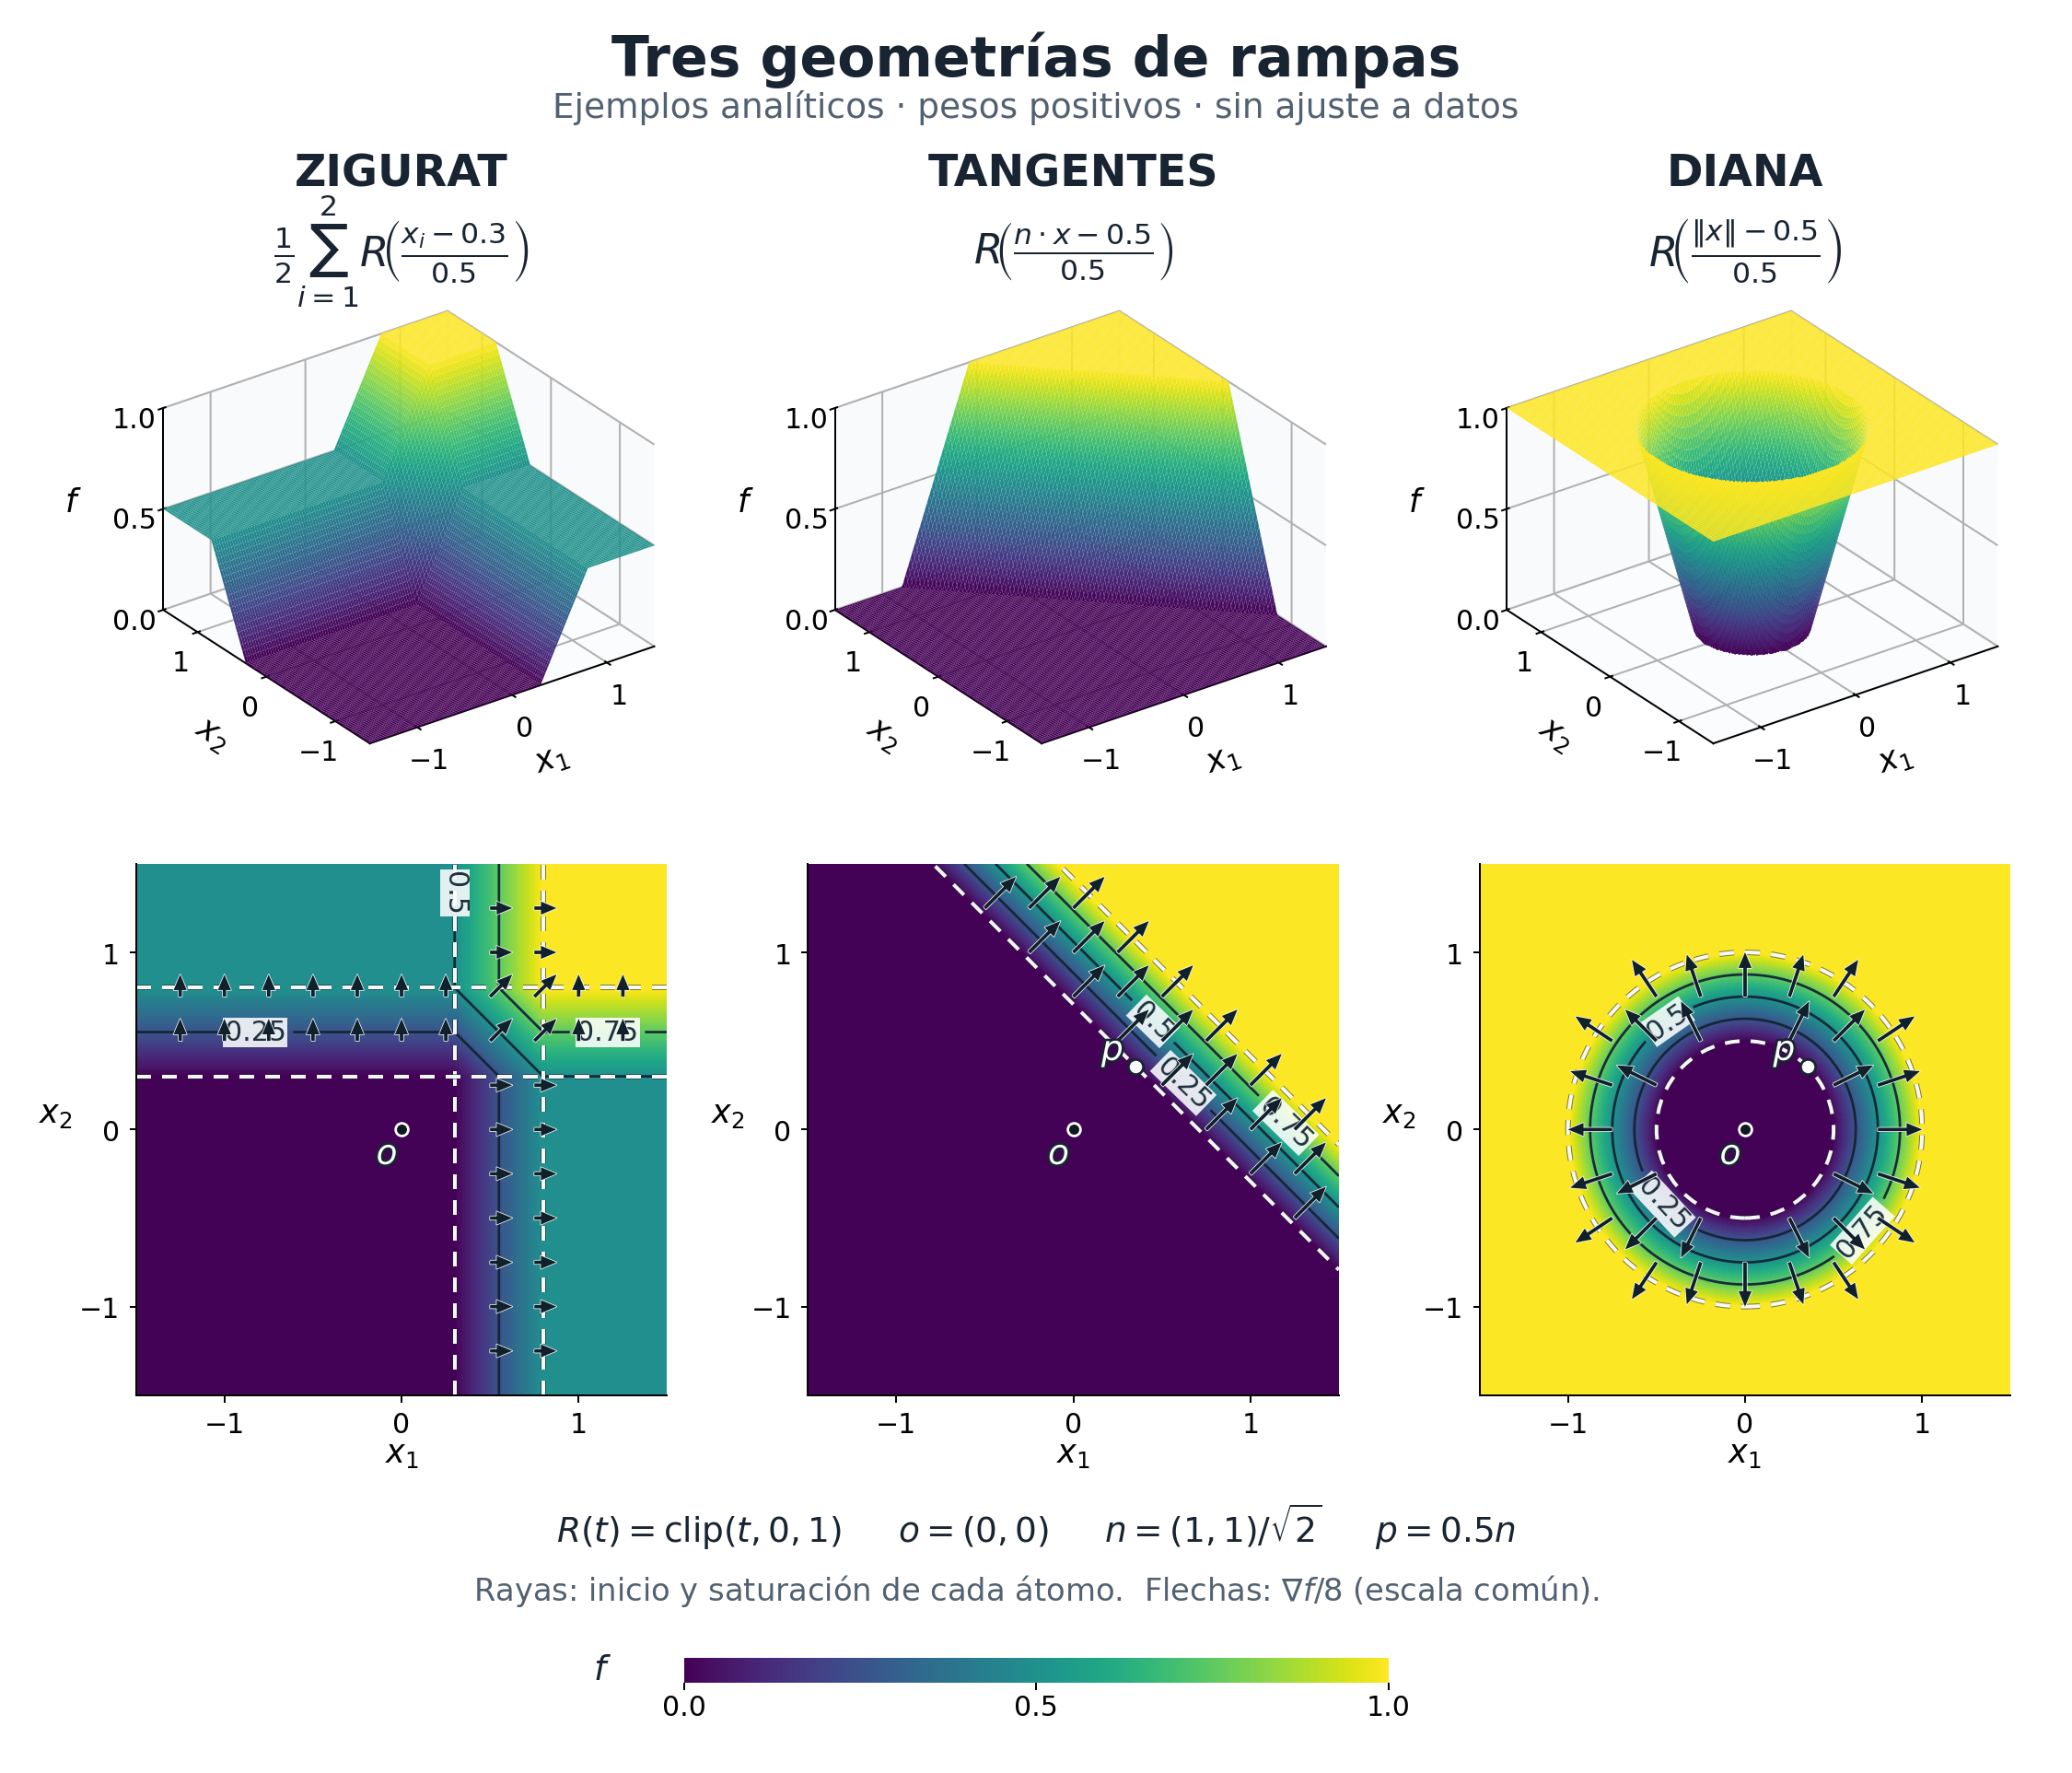

Los tres modelos pueden escribirse como
$$
\boxed{
f(\boldsymbol{x})
=
b+\sum_{j=1}^{M}
w_j\,
\rho\!\left(
\frac{q_j(\boldsymbol{x})-a_j}{h_j}
\right)
}
$$
con:
- $(\boldsymbol{x}=(x_1,x_2))$: entrada.
- $(q_j(\boldsymbol{x}))$: coordenada geométrica que observa la rampa.
- $(a_j)$: inicio de la transición.
- $(h_j>0)$: anchura de la transición.
- $(w_j)$: cambio total de altura aportado por esa rampa.
- $(b)$: nivel base, libre.

In [ ]:
import json
from bokeh.io import output_notebook
from bokeh.layouts import column, row
from bokeh.models import ColumnDataSource, CustomJS, Div, Select
from bokeh.plotting import figure, show

# Habilitar salida de gráficos de Bokeh en el cuaderno
output_notebook()

# 1. Definición de selectores usando las claves de los diccionarios existentes
selector_problema = Select(
    title="Problema:",
    value="Cobb-Douglas",
    options=list(problemas.keys()),
    width=250,
)

selector_sigma = Select(
    title="Ruido σ:",
    value="0.1",
    options=["0.1", "0.2"],
    width=130,
)

selector_modelo = Select(
    title="Modelo:",
    value="Isotónico",
    options=list(estimadores.keys()),
    width=250,
)

# 2. Obtener datos iniciales para popular las fuentes de datos de Bokeh
clave_inicial = f"Cobb-Douglas|0.1|Isotónico"
inicio = resultados[clave_inicial]

fuente_puntos = ColumnDataSource(
    data=dict(x=inicio["x"], y=inicio["y"])
)
fuente_curva = ColumnDataSource(
    data=dict(x=inicio["malla"], y=inicio["curva"])
)

# 3. Inicialización del gráfico
grafico = figure(
    width=900,
    height=400,
    title=f"Cobb-Douglas · Isotónico · σ=0.1",
    x_axis_label="x",
    y_axis_label="y",
    x_range=tuple(limites["Cobb-Douglas"]["x"]),
    y_range=tuple(limites["Cobb-Douglas"]["y"]),
    tools="pan,wheel_zoom,box_zoom,reset,save",
)

# Renderizadores de puntos y línea de regresión
grafico.scatter(
    "x", "y",
    source=fuente_puntos,
    size=7,
    color="black",
    alpha=0.7,
    legend_label="Observaciones",
)

grafico.line(
    "x", "y",
    source=fuente_curva,
    line_width=2.5,
    color="red",
    legend_label="Modelo ajustado",
)

grafico.legend.location = "top_left"

# Div de texto para el MSE de entrenamiento dinámico (usando 'styles' para compatibilidad en Bokeh)
resumen = Div(
    text=f"MSE de entrenamiento: <b>{inicio['mse']:.6f}</b>",
    styles={'font-size': '12pt', 'margin-top': '10px'}
)

# 4. Callback CustomJS para actualización rápida y sin necesidad de interactuar con Python
callback_actualizar = CustomJS(
    args=dict(
        registro_json=json.dumps(
            {"resultados": resultados, "limites": limites},
            allow_nan=False,
        ),
        problema=selector_problema,
        sigma=selector_sigma,
        modelo=selector_modelo,
        puntos=fuente_puntos,
        linea=fuente_curva,
        grafico=grafico,
        resumen=resumen,
    ),
    code="""
        const registro = JSON.parse(registro_json);

        // Crear la clave correspondiente usando la selección actual
        const clave = [
            problema.value,
            sigma.value,
            modelo.value
        ].join("|");

        const datos = registro.resultados[clave];

        if (datos) {
            // Actualizar fuentes de datos
            puntos.data = { x: datos.x, y: datos.y };
            linea.data = { x: datos.malla, y: datos.curva };

            // Forzar actualización en el render de Bokeh
            puntos.change.emit();
            linea.change.emit();

            // Actualizar el título del gráfico y el MSE de entrenamiento
            grafico.title.text = `${problema.value} · ${modelo.value} · σ=${sigma.value}`;
            resumen.text = `MSE de entrenamiento: <b>${datos.mse.toFixed(6)}</b>`;

            // Ajustar los rangos dinámicamente dependiendo del problema seleccionado
            const nuevos_limites = registro.limites[problema.value];
            grafico.x_range.start = nuevos_limites.x[0];
            grafico.x_range.end = nuevos_limites.x[1];
            grafico.y_range.start = nuevos_limites.y[0];
            grafico.y_range.end = nuevos_limites.y[1];
        }
    """,
)

# Asociar el callback a los eventos de cambio de valor
selector_problema.js_on_change("value", callback_actualizar)
selector_sigma.js_on_change("value", callback_actualizar)
selector_modelo.js_on_change("value", callback_actualizar)

# 5. Mostrar la estructura de la aplicación
show(column(
    row(selector_problema, selector_sigma, selector_modelo),
    grafico,
    resumen,
))

In [ ]:
import numpy as np
import cvxpy as cp

x_demo = np.array([0., 1., 3., 6.])
y_demo = np.array([-1., 1., 0., 2.])

monotona = True
nudos = np.unique(x_demo)


def base_escalones(puntos):
    puntos = np.asarray(puntos, dtype=float)

    escalones = (
        puntos[:, None] >= nudos[None, 1:]
    ).astype(float)

    # Primera columna: nivel inicial.
    # Las demás: escalones desplazados.
    return np.column_stack((
        np.ones(puntos.size),
        escalones,
    ))


Φ = base_escalones(x_demo)

coeficientes = cp.Variable(nudos.size)
predicciones = Φ @ coeficientes

restricciones = (
    [coeficientes[1:] >= 0]
    if monotona
    else []
)

problema = cp.Problem(
    cp.Minimize(cp.sum_squares(predicciones - y_demo)),
    restricciones,
)

problema.solve()

if problema.status != cp.OPTIMAL:
    raise RuntimeError(
        f"Estado del ajuste: {problema.status}"
    )

pesos = coeficientes.value.copy()


def predecir_escalones(puntos):
    return base_escalones(puntos) @ pesos


niveles = predecir_escalones(x_demo)

print("Nivel inicial e incrementos:", np.round(pesos, 6))
print("Niveles ajustados:", np.round(niveles, 6))
print("MSE:", np.mean((niveles - y_demo) ** 2))

In [ ]:
isot1 = regresion_isotonica(x1,y1_1)
isot2 = regresion_isotonica(x2,y2_1)
plot1.line(x1, y1_1, line_width=2, alpha=0.5, color="red")
plot2.line(x2, y2_1, line_width=2, alpha=0.5, color="red")

# display the figure
show(plot1)
show(plot2)

In [ ]:
#-- ===================================================================
#-- Isotónica de rampas: una "serie" de rampas truncadas
#-- ===================================================================
#-- Cada bloque "# %%" es una celda. Pégalas al final de Practica_3,
#-- en orden. Reutiliza lo que ya existe en el cuaderno:
#--     generar_datos_caso1, generar_datos_caso2,
#--     regresion_isotonica,
#--     modelo_lineal, modelo_cuadratico, modelo_cubico,
#--     modelo_potencial, modelo_logistico.
#--
#-- Capas, de abajo a arriba:
#--     1. La pieza base       -> rampa(t)
#--     2. El diccionario      -> qué rampas existen (inicio, anchura)
#--     3. El ajuste           -> cuánto pesa cada rampa (pesos >= 0)
#--     4. El espectro         -> dibujar qué rampas se han usado
#--     5. El banco de pruebas -> mismos datos para todos, ranking justo


# %% Celda 1 — La pieza base (primer principio)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass
from scipy.optimize import curve_fit
from scipy.optimize import lsq_linear


def rampa(
        t,
        ):
    """Señal t truncada: 0 si t < 0, t si 0 <= t <= 1, 1 si t > 1."""
    valores = np.asarray(t, dtype=float)
    return np.clip(valores, 0.0, 1.0)
    #-- Es tu step_line, pero trabaja con vectores enteros a la vez.


# %% Celda 2 — El diccionario de rampas (qué piezas hay disponibles)
@dataclass
class Diccionario:
    """Lista de rampas. La rampa k, evaluada en x, vale:
            rampa( (x - inicio_k) / ancho_k )
    Sube de 0 a 1 entre inicio_k e inicio_k + ancho_k."""

    inicios: np.ndarray
    anchos: np.ndarray

    def __post_init__(
            self,
            ):
        self.inicios = np.atleast_1d(np.asarray(self.inicios, dtype=float))
        self.anchos = np.atleast_1d(np.asarray(self.anchos, dtype=float))
        comprobar_diccionario(self.inicios, self.anchos)

    def __len__(
            self,
            ):
        return self.inicios.size

    def __add__(
            self,
            otro,
            ):
        """Unir dos diccionarios: todas las rampas de ambos."""
        inicios = np.concatenate((self.inicios, otro.inicios))
        anchos = np.concatenate((self.anchos, otro.anchos))
        return Diccionario(inicios, anchos)
        #-- Esto es el "álgebra": puedes escribir  grueso + fino.

    def evaluar(
            self,
            x,
            ):
        """Matriz (puntos x rampas): columna k = rampa k en cada punto."""
        puntos = np.asarray(x, dtype=float).reshape(-1, 1)
        distancia = puntos - self.inicios.reshape(1, -1)
        return rampa(distancia / self.anchos.reshape(1, -1))


def comprobar_diccionario(
        inicios,
        anchos,
        ):
    if inicios.ndim != 1 or inicios.shape != anchos.shape:
        raise ValueError("inicios y anchos deben ser vectores del mismo tamaño.")
    if inicios.size == 0:
        raise ValueError("El diccionario no puede estar vacío.")
    if not np.all(np.isfinite(inicios)) or not np.all(np.isfinite(anchos)):
        raise ValueError("inicios y anchos deben ser números finitos.")
    if np.any(anchos <= 0):
        raise ValueError("Todas las anchuras deben ser positivas.")


def diccionario_por_nudos(
        nudos,
        ):
    """Una rampa entre cada par de nudos consecutivos (una sola escala local)."""
    nudos_ordenados = np.unique(np.asarray(nudos, dtype=float))
    if nudos_ordenados.size < 2:
        raise ValueError("Hacen falta al menos dos nudos distintos.")
    return Diccionario(
        inicios=nudos_ordenados[:-1],
        anchos=np.diff(nudos_ordenados),
        )


def diccionario_de_una_escala(
        x,
        ancho,
        cantidad,
        ):
    """'cantidad' rampas de la misma anchura, repartidas por el rango de x."""
    x_min = float(np.min(x))
    x_max = float(np.max(x))
    posiciones = np.linspace(x_min - ancho, x_max, cantidad + 2)
    inicios = posiciones[1:-1]
    #-- Quitamos los extremos: una rampa que ya vale 1 en todos los datos
    #-- (o 0 en todos) no aporta nada que no aporte la constante base.
    anchos = np.full(cantidad, float(ancho))
    return Diccionario(inicios, anchos)


def diccionario_multiescala(
        x,
        fracciones=(1.0, 0.5, 0.25, 0.125),
        cantidad_por_escala=12,
        ):
    """Rampas anchas (tendencia general) + rampas estrechas (detalle).
    Es la idea de 'frecuencias' del Fourier, pero con anchuras."""
    rango = float(np.max(x) - np.min(x))
    if rango <= 0:
        raise ValueError("x debe tener al menos dos valores distintos.")

    escalas = [
        diccionario_de_una_escala(x, fraccion * rango, cantidad_por_escala)
        for fraccion in fracciones
        ]

    resultado = escalas[0]
    for escala in escalas[1:]:
        resultado = resultado + escala
    return resultado


# %% Celda 3 — El ajuste: cuánto pesa cada rampa
@dataclass
class ModeloRampas:
    """f(x) = base + suma_k  peso_k * rampa_k(x),   con peso_k >= 0."""

    base: float
    pesos: np.ndarray
    diccionario: Diccionario

    def __call__(
            self,
            x,
            ):
        return self.base + self.diccionario.evaluar(x) @ self.pesos
        #-- Un modelo se usa como una función:  modelo(x_nuevos)

    def rampas_activas(
            self,
            umbral=1e-9,
            ):
        return self.pesos > umbral


def comprobar_datos(
        x,
        y,
        ):
    if x.ndim != 1 or y.shape != x.shape or x.size == 0:
        raise ValueError("x e y deben ser vectores no vacíos del mismo tamaño.")
    if not np.all(np.isfinite(x)) or not np.all(np.isfinite(y)):
        raise ValueError("x e y deben contener solo números finitos.")


def ajustar_isotonica_rampas(
        x,
        y,
        diccionario,
        suavizado=0.0,
        ):
    """Mínimos cuadrados con pesos >= 0.
    Pesos >= 0  ->  cada rampa solo puede SUBIR  ->  f es no decreciente.
    suavizado > 0 penaliza pesos grandes (frena el sobreajuste)."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    comprobar_datos(x, y)
    if suavizado < 0:
        raise ValueError("suavizado no puede ser negativo.")

    columna_base = np.ones((x.size, 1))
    matriz = np.hstack((columna_base, diccionario.evaluar(x)))
    objetivo = y.copy()

    if suavizado > 0:
        filas_penalizacion = np.hstack((
            np.zeros((len(diccionario), 1)),
            np.sqrt(suavizado) * np.eye(len(diccionario)),
            ))
        #-- Añadir la fila  sqrt(s)*peso_k = 0  equivale a sumar
        #-- s * peso_k^2  al error. La base no se penaliza.
        matriz = np.vstack((matriz, filas_penalizacion))
        objetivo = np.concatenate((objetivo, np.zeros(len(diccionario))))

    limite_inferior = np.concatenate(([-np.inf], np.zeros(len(diccionario))))
    limite_superior = np.full(len(diccionario) + 1, np.inf)

    resultado = lsq_linear(
        matriz,
        objetivo,
        bounds=(limite_inferior, limite_superior),
        method="bvls",
        tol=1e-12,
        )
    if not resultado.success:
        raise RuntimeError(f"El ajuste de rampas no convergió: {resultado.message}")

    return ModeloRampas(
        base=float(resultado.x[0]),
        pesos=resultado.x[1:].copy(),
        diccionario=diccionario,
        )


# %% Celda 4 — El espectro: qué rampas ha elegido el ajuste
def dibujar_espectro(
        modelo,
        titulo="Espectro de rampas",
        ):
    """Eje x: centro de la rampa. Eje y: anchura (escala).
    Tamaño del punto: peso. Equivale al espectro de una FFT."""
    activas = modelo.rampas_activas()
    if not np.any(activas):
        print("Ninguna rampa activa: el modelo es una constante.")
        return

    inicios = modelo.diccionario.inicios[activas]
    anchos = modelo.diccionario.anchos[activas]
    pesos = modelo.pesos[activas]
    centros = inicios + anchos / 2

    plt.figure(figsize=(8, 4))
    plt.scatter(
        centros,
        anchos,
        s=2000 * pesos / pesos.max(),
        alpha=0.6,
        )
    plt.yscale("log")
    plt.xlabel("centro de la rampa (dónde sube)")
    plt.ylabel("anchura (escala)")
    plt.title(f"{titulo}  —  {activas.sum()} de {len(activas)} rampas activas")
    plt.grid(True, alpha=0.3)
    plt.show()


# %% Celda 5 — Banco de pruebas: mismos datos, mismo criterio, para todos
@dataclass
class Escenario:
    nombre: str
    x: np.ndarray
    y: np.ndarray
    verdad: object
    #-- La función real sin ruido. La conocemos porque simulamos los datos.




def crear_escenarios(
        semilla=42,
        n=25,
        ):
    """Generar los datos UNA sola vez. Todos los modelos usan los mismos."""
    np.random.seed(semilla)
    definiciones = [
        ("Caso 1 σ=0.1", generar_datos_caso1, verdad_caso1, 0.1),
        ("Caso 1 σ=0.2", generar_datos_caso1, verdad_caso1, 0.2),
        ("Caso 2 σ=0.1", generar_datos_caso2, verdad_caso2, 0.1),
        ("Caso 2 σ=0.2", generar_datos_caso2, verdad_caso2, 0.2),
        ]
    escenarios = []
    for nombre, generador, verdad, sigma in definiciones:
        x, y = generador(n=n, sigma=sigma)
        escenarios.append(Escenario(nombre, x, y, verdad))
    return escenarios


#-- Cada "ajustador" recibe (x, y) y devuelve una función predecir(puntos).
#-- Así todos los modelos tienen la misma forma y se tratan igual.

def ajustador_parametrico(
        modelo,
        p0=None,
        ):
    def ajustar(
            x,
            y,
            ):
        parametros, _ = curve_fit(modelo, x, y, p0=p0, maxfev=20000)

        def predecir(
                puntos,
                ):
            return modelo(np.asarray(puntos, dtype=float), *parametros)

        return predecir
    return ajustar


def ajustar_isotonica_qp(
        x,
        y,
        ):
    """Tu isotónica clásica, extendida a puntos nuevos como escalera."""
    valores = regresion_isotonica(x, y)
    if valores is None:
        raise RuntimeError("El solver de la isotónica QP no devolvió solución.")
    orden = np.argsort(x)
    x_ordenado = x[orden]
    valores_ordenados = valores[orden]

    def predecir(
            puntos,
            ):
        posicion = np.searchsorted(x_ordenado, puntos, side="right") - 1
        posicion = np.clip(posicion, 0, x_ordenado.size - 1)
        return valores_ordenados[posicion]

    return predecir


def ajustar_rampas_por_nudos(
        x,
        y,
        ):
    return ajustar_isotonica_rampas(x, y, diccionario_por_nudos(x))


def ajustar_rampas_multiescala(
        x,
        y,
        ):
    return ajustar_isotonica_rampas(
        x,
        y,
        diccionario_multiescala(x),
        suavizado=1e-3,
        )


MODELOS = {
    "Isotónica (QP)": ajustar_isotonica_qp,
    "Isotónica de rampas (nudos)": ajustar_rampas_por_nudos,
    "Isotónica de rampas (multiescala)": ajustar_rampas_multiescala,
    "Lineal": ajustador_parametrico(modelo_lineal),
    "Cuadrática": ajustador_parametrico(modelo_cuadratico),
    "Cúbica": ajustador_parametrico(modelo_cubico),
    "Potencial": ajustador_parametrico(modelo_potencial, p0=[1, 1]),
    "Logístico": ajustador_parametrico(modelo_logistico, p0=[1, 10, 0.5, 0]),
    }


def evaluar_modelo(
        ajustar,
        escenario,
        puntos_control,
        ):
    """Dos errores:
        - entrenamiento: contra los datos con ruido (premia memorizar)
        - verdad: contra la función real (premia acertar la forma)"""
    sin_resultado = {"entrenamiento": np.nan, "verdad": np.nan, "predecir": None}
    try:
        predecir = ajustar(escenario.x, escenario.y)
        prediccion_datos = predecir(escenario.x)
        prediccion_control = predecir(puntos_control)
    except (RuntimeError, ValueError, np.linalg.LinAlgError) as error:
        print(f"[{escenario.nombre}] un modelo falló: {error}")
        return sin_resultado

    error_entrenamiento = np.mean((prediccion_datos - escenario.y) ** 2)
    error_verdad = np.mean((prediccion_control - escenario.verdad(puntos_control)) ** 2)
    return {
        "entrenamiento": error_entrenamiento,
        "verdad": error_verdad,
        "predecir": predecir,
        }


def puntos_de_control(
        escenario,
        cantidad=400,
        ):
    return np.linspace(np.min(escenario.x), np.max(escenario.x), cantidad)
    #-- Solo dentro del rango observado: no juzgamos extrapolación.


def tabla_de_ranking(
        errores,
        ):
    """errores: DataFrame (filas = modelos, columnas = escenarios)."""
    rangos = errores.rank(axis=0, ascending=True)
    tabla = rangos.copy()
    tabla["Ranking Medio"] = rangos.mean(axis=1)
    tabla["MSE Medio"] = errores.mean(axis=1)
    return tabla.sort_values(by="Ranking Medio")


def ejecutar_banco_de_pruebas(
        escenarios,
        modelos,
        ):
    errores_entrenamiento = {}
    errores_verdad = {}
    predictores = {}

    for escenario in escenarios:
        control = puntos_de_control(escenario)
        errores_entrenamiento[escenario.nombre] = {}
        errores_verdad[escenario.nombre] = {}
        predictores[escenario.nombre] = {}

        for nombre, ajustar in modelos.items():
            resultado = evaluar_modelo(ajustar, escenario, control)
            errores_entrenamiento[escenario.nombre][nombre] = resultado["entrenamiento"]
            errores_verdad[escenario.nombre][nombre] = resultado["verdad"]
            predictores[escenario.nombre][nombre] = resultado["predecir"]

    return (
        pd.DataFrame(errores_entrenamiento),
        pd.DataFrame(errores_verdad),
        predictores,
        )


def dibujar_escenario(
        escenario,
        predictores_del_escenario,
        nombres,
        ):
    control = puntos_de_control(escenario)
    plt.figure(figsize=(10, 5))
    plt.scatter(escenario.x, escenario.y, color="black", zorder=5, label="Datos")
    plt.plot(control, escenario.verdad(control), "k:", linewidth=2, label="Función real")
    for nombre in nombres:
        predecir = predictores_del_escenario.get(nombre)
        if predecir is None:
            continue
        plt.plot(control, predecir(control), linewidth=2, label=nombre)
    plt.title(escenario.nombre)
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


# %% Celda 6 — Ejecutar
escenarios = crear_escenarios(semilla=42, n=25)

errores_entrenamiento, errores_verdad, predictores = ejecutar_banco_de_pruebas(
    escenarios,
    MODELOS,
    )

print("Ranking por error de ENTRENAMIENTO (lo que hacía el cuaderno):")
display(tabla_de_ranking(errores_entrenamiento))

print("Ranking por error frente a la FUNCIÓN REAL (el criterio honesto):")
display(tabla_de_ranking(errores_verdad))

for escenario in escenarios:
    dibujar_escenario(
        escenario,
        predictores[escenario.nombre],
        [
            "Isotónica (QP)",
            "Isotónica de rampas (nudos)",
            "Isotónica de rampas (multiescala)",
            "Logístico",
            ],
        )

modelo_ejemplo = predictores[escenarios[2].nombre]["Isotónica de rampas (multiescala)"]
dibujar_espectro(modelo_ejemplo, titulo=escenarios[2].nombre)

In [ ]:
# %% Celda 7 — Ranking de PREDICCIÓN con datos nuevos de las mismas fórmulas
#-- Idea: ajustar con un grupo de datos (entrenamiento) y medir el error
#-- con OTRO grupo nuevo, generado con la misma fórmula y el mismo ruido
#-- (prueba). El modelo nunca ha visto los datos de prueba.
#-- Se repite muchas veces para que el ranking no dependa de la suerte.
#--
#-- Reutiliza: generar_datos_caso1, generar_datos_caso2, MODELOS
#-- (celda 5) y las librerías importadas en la celda 1.

import warnings
from scipy.optimize import OptimizeWarning


@dataclass
class Experimento:
    """Una fórmula + un nivel de ruido. Sabe generar datos nuevos."""
    nombre: str
    generador: object
    sigma: float

    def generar(
            self,
            n,
            ):
        return self.generador(n=n, sigma=self.sigma)


EXPERIMENTOS = [
    Experimento("Caso 1 σ=0.1", generar_datos_caso1, 0.1),
    Experimento("Caso 1 σ=0.2", generar_datos_caso1, 0.2),
    Experimento("Caso 2 σ=0.1", generar_datos_caso2, 0.1),
    Experimento("Caso 2 σ=0.2", generar_datos_caso2, 0.2),
    ]


def error_de_prediccion(
        ajustar,
        entrenamiento,
        prueba,
        ):
    """Ajusta con 'entrenamiento' y mide el MSE sobre 'prueba'.
    Devuelve NaN si el modelo falla o predice valores no finitos."""
    x_entrenamiento, y_entrenamiento = entrenamiento
    x_prueba, y_prueba = prueba

    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", OptimizeWarning)
            #-- curve_fit avisa cuando no puede estimar la incertidumbre
            #-- de los parámetros. No nos importa aquí: solo predecimos.
            predecir = ajustar(x_entrenamiento, y_entrenamiento)
            prediccion = predecir(x_prueba)
    except (RuntimeError, ValueError, np.linalg.LinAlgError):
        return np.nan

    if not np.all(np.isfinite(prediccion)):
        return np.nan
    return np.mean((prediccion - y_prueba) ** 2)


def una_repeticion(
        experimento,
        modelos,
        n_entrenamiento,
        n_prueba,
        ):
    """Un grupo de entrenamiento y un grupo de prueba nuevos.
    Todos los modelos reciben exactamente los mismos datos."""
    entrenamiento = experimento.generar(n_entrenamiento)
    prueba = experimento.generar(n_prueba)

    errores = {}
    for nombre, ajustar in modelos.items():
        errores[nombre] = error_de_prediccion(ajustar, entrenamiento, prueba)
    return errores


def ejecutar_ranking_de_prediccion(
        experimentos,
        modelos,
        repeticiones=50,
        n_entrenamiento=25,
        n_prueba=500,
        semilla=2026,
        ):
    """Devuelve una tabla larga: una fila por (repetición, escenario, modelo)."""
    np.random.seed(semilla)
    #-- Tus generadores usan el estado aleatorio global de numpy.
    #-- Fijarlo aquí hace que toda la celda sea reproducible.

    registros = []
    for repeticion in range(repeticiones):
        for experimento in experimentos:
            errores = una_repeticion(
                experimento,
                modelos,
                n_entrenamiento,
                n_prueba,
                )
            for modelo, error in errores.items():
                registros.append({
                    "repeticion": repeticion,
                    "escenario": experimento.nombre,
                    "modelo": modelo,
                    "mse": error,
                    "ruido": experimento.sigma ** 2,
                    })

    tabla = pd.DataFrame(registros)
    tabla["exceso"] = tabla["mse"] - tabla["ruido"]
    #-- El ruido σ² no lo puede predecir nadie: es el suelo del error.
    #-- 'exceso' es lo que el modelo añade por encima de ese suelo.
    return tabla


def anadir_rangos(
        registros,
        ):
    """Rango de cada modelo DENTRO de cada (repetición, escenario).
    1 = mejor. Un modelo que falla recibe el peor rango."""
    grupos = registros.groupby(["repeticion", "escenario"])["mse"]
    registros = registros.copy()
    registros["rango"] = grupos.rank(method="average", na_option="bottom")
    return registros


def resumir_ranking_de_prediccion(
        registros,
        experimentos,
        ):
    orden_escenarios = [experimento.nombre for experimento in experimentos]

    rangos_por_escenario = registros.pivot_table(
        index="modelo",
        columns="escenario",
        values="rango",
        aggfunc="mean",
        )[orden_escenarios]

    resumen = rangos_por_escenario.copy()
    resumen["Ranking Medio"] = registros.groupby("modelo")["rango"].mean()
    resumen["Victorias (%)"] = registros.groupby("modelo")["rango"].apply(
        lambda rangos: 100 * np.mean(rangos == 1),
        )
    resumen["MSE prueba medio"] = registros.groupby("modelo")["mse"].mean()
    resumen["Exceso sobre σ²"] = registros.groupby("modelo")["exceso"].mean()
    resumen["Fallos"] = registros.groupby("modelo")["mse"].apply(
        lambda errores: int(errores.isna().sum()),
        )
    return resumen.sort_values(by="Ranking Medio")


def dibujar_distribucion_de_errores(
        registros,
        experimentos,
        orden_modelos,
        ):
    """Una caja por modelo: cómo varía el exceso de error entre repeticiones.
    Cajas estrechas y bajas = modelo fiable."""
    figura, ejes = plt.subplots(
        1,
        len(experimentos),
        figsize=(5 * len(experimentos), 5),
        sharey=False,
        )
    for eje, experimento in zip(ejes, experimentos):
        datos_escenario = registros[registros["escenario"] == experimento.nombre]
        valores = [
            datos_escenario.loc[datos_escenario["modelo"] == modelo, "exceso"].dropna()
            for modelo in orden_modelos
            ]
        posiciones = np.arange(1, len(orden_modelos) + 1)
        eje.boxplot(valores, positions=posiciones, vert=False, showfliers=False)
        eje.set_yticks(posiciones)
        eje.set_yticklabels(orden_modelos)
        #-- Etiquetas puestas a mano: el nombre del argumento 'labels'
        #-- de boxplot cambia entre versiones de matplotlib.
        eje.invert_yaxis()
        #-- El mejor modelo del ranking queda arriba.
        eje.axvline(0, color="black", linewidth=1)
        eje.set_title(experimento.nombre)
        eje.set_xlabel("MSE prueba − σ²")
        eje.grid(True, alpha=0.3)
    for eje in ejes[1:]:
        eje.set_yticklabels([])
    plt.tight_layout()
    plt.show()


# -- Ejecutar ---------------------------------------------------------
registros_prediccion = ejecutar_ranking_de_prediccion(
    EXPERIMENTOS,
    MODELOS,
    repeticiones=50,
    n_entrenamiento=25,
    n_prueba=500,
    )
registros_prediccion = anadir_rangos(registros_prediccion)

ranking_prediccion = resumir_ranking_de_prediccion(
    registros_prediccion,
    EXPERIMENTOS,
    )

print("Ranking de PREDICCIÓN (datos nuevos, 50 repeticiones):")
display(ranking_prediccion.round(4))

dibujar_distribucion_de_errores(
    registros_prediccion,
    EXPERIMENTOS,
    list(ranking_prediccion.index),
    )

Tangentes se ajusta por pasos:
  1. Barrer el ángulo de 0° a 90°; en cada uno, isotónica del residuo proyectado.
  2. Añadir la dirección de menor error.
  3. Reajustar todas las direcciones por turnos hasta que se estabilice.

Parar cuando el error de predicción deje de mejorar.

Al final, comprimir cada isotónica en rampas con los nudos deseados.

